# Trabajo Senasa + MQ: revisión, agrupamiento, categorías y reglas de asociación
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Un solo cuaderno para todo el trabajo actual. Lee las entradas de `datos_entrada/`, usa el código de `src/` y escribe
todo en `resultados/` (`excel/`, `tablas/`, `modelos/`). Se regenera con `build_notebook.py` (no editar a mano).

| sección | qué hace | escribe |
|---|---|---|
| 0 | rutas y parámetros | |
| 1 | lectura de Senasa y correcciones | |
| 2 | Excel de inconsistencias para revisión (solo Senasa; Senasa + MQ) | `excel/dataset_senasa_revision.xlsx`, `excel/dataset_senasa_mq_revision.xlsx` |
| 3 | agrupamiento solo Senasa (outliers por consenso, k-medias, tags, métricas y segundo nivel por familia: DDL y polvos; el queso va a una rama propia con la humedad del CAA, fuera del k-medias) | `tablas/clusters_senasa.csv`, `modelos/agrupamiento_senasa_clase41.joblib` |
| 4 | agrupamiento Senasa + MQ (MQ sale de `MQ encolumnado.xlsx`, sin las MO), con la clase 41 completa (y lo mismo que la sección 3, con la rama de queso y su agrupamiento sin tag previo) | `tablas/clusters_senasa_mq.csv`, `modelos/agrupamiento_senasa_mq_clase41.joblib` |
| 5 | cortes para categorizar (CAA por familia, terciles) | `tablas/cortes_categorias.csv` |
| 6 | categorías, ítems y reglas de asociación | `tablas/categorias_*.csv`, `tablas/transacciones_*.parquet` |
| 7 | MQ con el formato de Senasa encolumnado (solo si `REGENERAR_MQ = True`) | `excel/MQ encolumnado*.xlsx` |
| 8 | datos usados en cada entrenamiento (cuántas muestras entran a cada modelo, qué se excluye y cómo se reparte) | `resultados/datos_entrenamiento/trabajo_senasa_mq.csv` |
| 9 | verificación de las salidas | |

## 0 · Rutas y parámetros
Todas las rutas salen de `src/rutas.py` y son relativas a la carpeta `trabajo_senasa_mq/` (se puede cambiar con la
variable de entorno `TRABAJO_SENASA_MQ_RAIZ`). `REGENERAR_MQ = False` lee los dos Excel de MQ encolumnado ya generados;
con `True` los vuelve a armar desde los crudos de MQ (tarda más y los reemplaza). Las secciones 3 y 4 leen `MQ encolumnado.xlsx` (la sección 7 lo escribe al final), así que con `True` hay que ejecutar el cuaderno dos veces para que el agrupamiento use el Excel nuevo.

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import rutas as R
R.preparar()

REGENERAR_MQ = False

print("RAIZ:", R.RAIZ)
for nombre in ["SENASA", "CORRECCIONES", "MQ_ANCHA", "MQ_TIPO", "MQ_CRUDOS", "EXCEL", "TABLAS", "MODELOS"]:
    ruta = getattr(R, nombre)
    print(f"   {nombre:13} {ruta.relative_to(R.RAIZ)}{'' if ruta.exists() else '   (FALTA)'}")

RAIZ: E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq
   SENASA        datos_entrada\Senasa encolumnado.xlsx
   CORRECCIONES  datos_entrada\correcciones_clase41.csv
   MQ_ANCHA      datos_entrada\mq\muestras_ancha.csv
   MQ_TIPO       datos_entrada\mq\mq_tipo_muestra.csv
   MQ_CRUDOS     datos_entrada\mq\crudos
   EXCEL         resultados\excel
   TABLAS        resultados\tablas
   MODELOS       resultados\modelos


## 1 · Lectura y correcciones

`Senasa encolumnado.xlsx` (en `datos_entrada/`) tiene una fila por muestra y una columna `Resultado ...` por análisis.
Los resultados vienen como texto: `28,45`, `29,35 +/- 0,09`, `&lt; 0,03`. Se leen así: coma decimal, se toma el valor y
no la incertidumbre, y los «< LD» (menores al límite de detección) se toman como 0.

**Qué columnas entran en el agrupamiento.** Las cuatro de la composición centesimal que se miden **juntas**: humedad,
materia grasa, proteínas y cenizas. Los sólidos totales no entran porque son 100 − humedad (sería contar dos veces la
misma variable). La lactosa tampoco, porque casi nunca se mide junto con las otras cuatro. Entra una muestra solo si
tiene los cuatro valores, y se descartan las que suman más de 102 g/100 g (error de carga).

**Correcciones** (decididas al revisar los Excel de la sección 2). La lectura y las correcciones están en un solo
lugar, `src/datos_clase41.py`, que usan las secciones 2, 3, 4 y 6:
- las puntuales, en `datos_entrada/correcciones_clase41.csv` (Identificador, campo, antes, después, motivo);
  `Senasa encolumnado.xlsx` no se toca;
- dos reglas generales de lectura: «,.» es un tipeo de «,», y «NO DETECTADO» vale 0 por defecto (como «< LD»);
- quedan **fuera del análisis** las muestras de Senasa cuya humedad + sólidos totales no da 100 ± 1 (si falta alguno de
  los dos, no se excluyen por esto).

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, BisectingKMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

from datos_clase41 import COLUMNAS, FAMILIAS_NO_LACTEAS, N_INIT_KMEDIAS, SEMILLA, SIN_FAMILIA, SUMA_MAX, TAGS, leer_senasa, leer_mq, unir, etiquetar
import mejoras_clustering as M      # outliers por consenso y métricas (probados en prueba_mejoras_clustering.ipynb)
import segundo_nivel as N           # subtags por familia: DDL, polvos y queso (las pruebas por familia)
import clustering_quesos as Q       # la rama de queso: los quesos que confirma el catálogo, fuera del k-medias
import warnings
warnings.filterwarnings("ignore", message=".*covariance matrix.*full rank.*")   # la elipse en grupos chicos y casi planos
warnings.filterwarnings("ignore", message=".*Determinant has increased.*")

AZUL, AMBAR, GRIS, ROJO, VERDE, VIOLETA = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57", "#7c3aed"
COLORES = [AZUL, ROJO, VERDE, AMBAR, VIOLETA, "#0e7490", "#be185d", "#4d7c0f", "#92400e", "#334155"]
pd.set_option("display.width", 140)

S = leer_senasa()                    # Senasa corregido y parseado (datos_clase41.py)
senasa = S.crudo[["Identificador", "desc_familia", "desc_producto", "desc_tipo_muestra"] + COLUMNAS].copy()
coma = sum(v_[0] for v_ in S.celdas_tipeo.values()); no_det = sum(v_[1] for v_ in S.celdas_tipeo.values())
print(f"Senasa: {len(senasa)} muestras · {int(senasa[COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis")
print(f"Reglas generales: «,.» → «,» en {coma} celdas · NO DETECTADO = 0 en {no_det} celdas · "
      f"{len(S.excluidas)} muestras excluidas por humedad + sólidos fuera de 100 ± 1")
print("Correcciones puntuales (correcciones_clase41.csv):")
S.correcciones

Senasa: 16347 muestras · 2693 con los cuatro análisis
Reglas generales: «,.» → «,» en 2 celdas · NO DETECTADO = 0 en 42 celdas · 8 muestras excluidas por humedad + sólidos fuera de 100 ± 1
Correcciones puntuales (correcciones_clase41.csv):


,Identificador,campo,antes,despues,motivo
0,MO-02210-01,Resultado Humedad g/ 100g (*),4548,"45,48","error de tipeo: falta la coma decimal (queso, ..."
1,MQ-32694-01,Resultado Lactosa g /100g (*),"124,3",NaN,error de carga: lactosa > 100 en un suero; pod...
2,MQ-15026-02,desc_familia,manteca / crema,queso,"CREMOSO DOBLE CREMA es un queso cremoso, no ma..."


## 2 · Excel de inconsistencias
`src/revision_excel.py` (ex `exportar_dataset_senasa_mq.py`) arma un agrupamiento propio con el mismo método de las secciones 3 y 4
(outliers por consenso y k-medias por silueta), pero **sobre otra población**: no saca las familias que no son lácteas ni
los quesos de la rama de queso. Por eso su k y sus cantidades (muestras, outliers) **no coinciden** con las de esas
secciones; sirve para revisar las muestras, no para leer el agrupamiento. Marca las inconsistencias de cada muestra con reglas (suma > 102, humedad + sólidos, Senasa contra MQ,
todo cerca de 0...). Escribe dos Excel con las hojas `dataset`, `inconsistencias`, `resumen` y `notas`: uno solo con
Senasa y otro con Senasa + MQ. Las correcciones que salen de revisarlos van a `datos_entrada/correcciones_clase41.csv`.

In [3]:
import revision_excel
revision_excel.exportar()

Con 4 análisis: 4083 · tras filtro <=102: 4079 · K_PRE=6 · outliers: 112 · quedan 3967 · K=6


E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\src\revision_excel.py:177: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return (df["desc_familia"] == "helado") & _texto(df).str.contains(FRUTAL)


E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\src\revision_excel.py:177: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return (df["desc_familia"] == "helado") & _texto(df).str.contains(FRUTAL)


Escrito: E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\excel\dataset_senasa_mq_revision.xlsx
dataset: 30089 filas · inconsistencias: 924 filas
                                                 regla  filas  identificadores
                          R01 suma de los cuatro > 102      4                4
R03 Senasa: humedad + sólidos totales fuera de 100 ± 1      8                8
                              R04 Senasa y MQ difieren     67               63
                            R05 MQ con nota en revisar    138              138
                     R06 outlier (k-medias preliminar)    112              112
                                  R07 silueta negativa     14               14
    R08 familia distinta de la mayoritaria de su grupo    570              570
                          R09 valores todos cerca de 0     11               11


[solo Senasa] con 4 análisis: 2687 · tras filtro <=102: 2687 · K_PRE=5 · outliers: 62 · quedan 2625 · K=6


E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\src\revision_excel.py:177: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return (df["desc_familia"] == "helado") & _texto(df).str.contains(FRUTAL)
E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\src\revision_excel.py:177: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  return (df["desc_familia"] == "helado") & _texto(df).str.contains(FRUTAL)


Escrito: E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\excel\dataset_senasa_revision.xlsx
dataset: 16347 filas · inconsistencias: 161 filas
                                                           regla  filas  identificadores
                  S03 humedad + sólidos totales fuera de 100 ± 1      8                8
                  S07 outlier (k-medias preliminar, solo Senasa)     62               62
                              S08 silueta negativa (solo Senasa)      1                1
S09 familia distinta de la mayoritaria de su grupo (solo Senasa)     89               89
                            S10 valor anulado por error de carga      1                1


## 3 · Agrupamiento (clase 41): Senasa

Los dos cuadernos de la clase 41 (`Clase_41_agrupamiento_simple` y `Clase_41_agrupamiento_particional_y_jerarquico`)
agrupan socios de un gimnasio. Acá se aplican los algoritmos a `Senasa encolumnado.xlsx`, **solo con los datos de Senasa** (sin MQ). Versión hermana: sección 4 (la misma clase con Senasa + MQ, con todos los algoritmos).

Pregunta: sin decirle al algoritmo qué producto es cada muestra, **¿hay grupos de muestras de composición parecida?
¿cuántos, y cómo son?** La familia del producto (dulce de leche, leche en polvo...), cuando se conoce, cumple el papel que tenía el *plan*
en el gimnasio: **no entra** en el agrupamiento; se guarda aparte y se compara al final. A cada grupo final se le da un
**tag** corto (DDL, POLVO_GRASO, QUESO...) que sale de su centroide, no del número de cluster. Dentro del DDL, de los
polvos y del queso, un segundo nivel por familia le da a una parte de las muestras un **subtag** (DDL_REPOSTERO,
POLVO_WPC, QUESO_SEMIDURO...).

Partes: **muestras y outliers** · **B.1 · cuántos grupos** (codo y silueta) · **B.2 · el modelo y sus tags** · **B.5 · métricas sin el sesgo del grupo más grande** · **F · qué es cada grupo, segundo nivel y guardar** · **G · qué quedó**. El resto de la clase (A, B.3, B.4, C, D, E) está en la sección 4.

#### Las muestras que entran
Solo Senasa: no se completa nada con MQ. Se quitan las excluidas por humedad + sólidos y las familias que no son
lácteas (cárnicos, panificados / otros, agua / hisopado y base nutricional: `FAMILIAS_NO_LACTEAS`) y los quesos, que van
a su rama propia (más abajo); se piden los cuatro análisis y se descartan las que suman más de 102. Todas tienen familia
conocida.

In [4]:
n_inicial = len(senasa)                                    # todas las muestras de Senasa, antes de cualquier filtro
todas = senasa[~senasa["Identificador"].isin(S.excluidas)].assign(origen="Senasa")
no_lactea = todas["desc_familia"].isin(FAMILIAS_NO_LACTEAS)
print(f"Fuera por no ser lácteas ({', '.join(FAMILIAS_NO_LACTEAS)}): {int(no_lactea.sum())} muestras, "
      f"{int(todas.loc[no_lactea, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis")
todas = todas[~no_lactea]
rama, confirmados, sin_confirmar, conteo_q = Q.rama_queso(S, False)  # los quesos (desc_familia = queso) van a su rama
a_rama = todas["Identificador"].isin(confirmados)
print(f"Quesos de Senasa: {len(confirmados)} · salen de acá {int(a_rama.sum())} ({int(todas.loc[a_rama, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis): no pasan por el k-medias")
todas = todas[~a_rama]
completas = todas.dropna(subset=COLUMNAS)
muestras = completas[completas[COLUMNAS].sum(axis=1) <= SUMA_MAX].reset_index(drop=True)
familia = muestras["desc_familia"]                  # se guarda aparte: NO entra en el agrupamiento
conocida = (familia != SIN_FAMILIA).values          # en esta versión, todas
print(f"Con los cuatro análisis: {len(completas)} · descartadas por sumar más de {SUMA_MAX}: {len(completas) - len(muestras)} · quedan {len(muestras)}")
print("Familias (no entran):", familia.value_counts().to_dict())
muestras[COLUMNAS].describe().round(2).T

Fuera por no ser lácteas (carnicos, panificados / otros, agua / hisopado, base nutricional): 1727 muestras, 27 con los cuatro análisis


Quesos de Senasa: 4006 · salen de acá 4006 (0 con los cuatro análisis): no pasan por el k-medias
Con los cuatro análisis: 2660 · descartadas por sumar más de 102: 0 · quedan 2660
Familias (no entran): {'dulce de leche': 2161, 'concentrado proteico': 326, 'leche en polvo': 100, 'suero / permeado': 57, 'yogur / bebida lactea': 11, 'helado': 3, 'arroz con leche / postre': 2}


,count,mean,std,min,25%,50%,75%,max
humedad,2660.0,23.38,9.91,1.49,23.17,27.57,28.84,77.92
grasa,2660.0,7.02,4.39,0.00,6.10,6.74,7.49,55.17
proteinas,2660.0,11.95,14.09,1.84,5.75,6.64,8.03,91.63
cenizas,2660.0,2.31,1.68,0.68,1.35,1.58,2.15,8.20


#### Imputar y escalar
No hay faltantes (se pidieron los cuatro análisis), pero el imputador queda en el flujo como en la clase, para que una
muestra nueva con un hueco también se pueda ubicar. Después se **escala**: media 0 y desvío 1 por columna. `Z` es lo
que ven los algoritmos.

In [5]:
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print("Desvío de cada columna antes de escalar:", {c_: round(float(muestras[c_].std()), 2) for c_ in COLUMNAS})
print(f"Z: {Z.shape[0]} muestras × {Z.shape[1]} columnas · media ≈ {Z.mean(axis=0).round(2).tolist()} · desvío ≈ {Z.std(axis=0).round(2).tolist()}")

Desvío de cada columna antes de escalar: {'humedad': 9.91, 'grasa': 4.39, 'proteinas': 14.09, 'cenizas': 1.68}
Z: 2660 muestras × 4 columnas · media ≈ [-0.0, 0.0, 0.0, -0.0] · desvío ≈ [1.0, 1.0, 1.0, 1.0]


#### Quitar los outliers
Un filtro global por columna (IQR o z-score sobre todas las muestras) no sirve acá: el dulce de leche es la mayoría, y
un filtro así marcaría como «raros» a todos los polvos, que son grupos reales. Un outlier es una muestra
rara **para su tipo de producto**. Como la familia no se puede usar, el tipo sale de
un **k-medias preliminar**, con k elegido por silueta, igual que en B.1. Dentro de cada grupo se decide por **consenso**
(clase 46; `M.outliers_consenso`, probado en `prueba_mejoras_clustering.ipynb`):

1. k-medias preliminar sobre `Z`; cada muestra, a su grupo.
2. Dentro de cada grupo (de 30 muestras o más) se reescala con las muestras del grupo y se calculan tres puntajes, donde
   más bajo es más raro: el **factor local** (`LocalOutlierFactor`, 50 vecinos), el **bosque de aislamiento**
   (`IsolationForest`, 200 árboles) y la **elipse** (`EllipticEnvelope`).
3. Cada método marca el **3 %** de menor puntaje del grupo; es outlier lo que marcan **al menos 2 de los 3**.

Antes se usaba otra regla: distancia al centroide del grupo preliminar mayor que **Q3 + 1,5 · IQR** de las distancias
del grupo. Se reemplazó porque sacaba variantes legítimas del dulce de leche: el heladero (menos humedad, más cenizas)
queda lejos del centroide del DDL, y la regla IQR se llevaba casi todos. Abajo se comparan las dos reglas.

Se quitan, se vuelve a imputar y escalar con las que quedan, y **todo lo que sigue usa el conjunto sin outliers**.

k-medias preliminar con k = 5 · outliers por consenso (3 %, 2 de 3): 63 de 2660 (2.4 %) · con la regla IQR de antes serían 229 (8.6 %)


,muestras,outliers,con IQR (antes),% outliers
grupo preliminar,,,,
0,90,3,19,3.3
1,2167,51,207,2.4
2,344,9,3,2.6
3,49,0,0,0.0
4,10,0,0,0.0


Cuántas marca cada método y cuántas votos juntan: {'factor local': 81, 'bosque': 81, 'elipse': 81} · votos: {0: 2494, 1: 103, 2: 49, 3: 14}
Consenso contra la regla IQR de antes:


consenso (ahora),False,True,All
regla IQR (antes),,,
False,2425,6,2431
True,172,57,229
All,2597,63,2660


Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):


,muestras,se conservan (consenso),se conservaban (IQR)
repostero,623,620,616
heladero,176,152,36
reducido en grasa,11,3,0


Outliers por familia: {'dulce de leche': 41, 'suero / permeado': 19, 'yogur / bebida lactea': 3}
Algunos outliers (g/100 g), los de más votos:


,Identificador,desc_familia,origen,humedad,grasa,proteinas,cenizas,votos
143,MO-08545-02,suero / permeado,Senasa,2.28,0.91,14.07,0.84,3
142,MO-08545-01,suero / permeado,Senasa,2.39,0.97,14.25,0.90,3
108,MO-08333-01,suero / permeado,Senasa,1.49,55.17,4.86,3.98,3
144,MO-08545-03,suero / permeado,Senasa,2.30,1.06,13.94,0.78,3
150,MO-08633-01,suero / permeado,Senasa,2.24,1.05,13.74,0.83,3
146,MO-08545-05,suero / permeado,Senasa,2.29,1.01,13.92,0.81,3
145,MO-08545-04,suero / permeado,Senasa,2.36,1.03,13.62,0.84,3
152,MO-08633-03,suero / permeado,Senasa,2.21,1.13,13.58,0.86,3
153,MO-08637-01,suero / permeado,Senasa,2.54,1.18,13.98,0.81,3
154,MO-08637-02,suero / permeado,Senasa,2.74,1.17,13.57,0.84,3


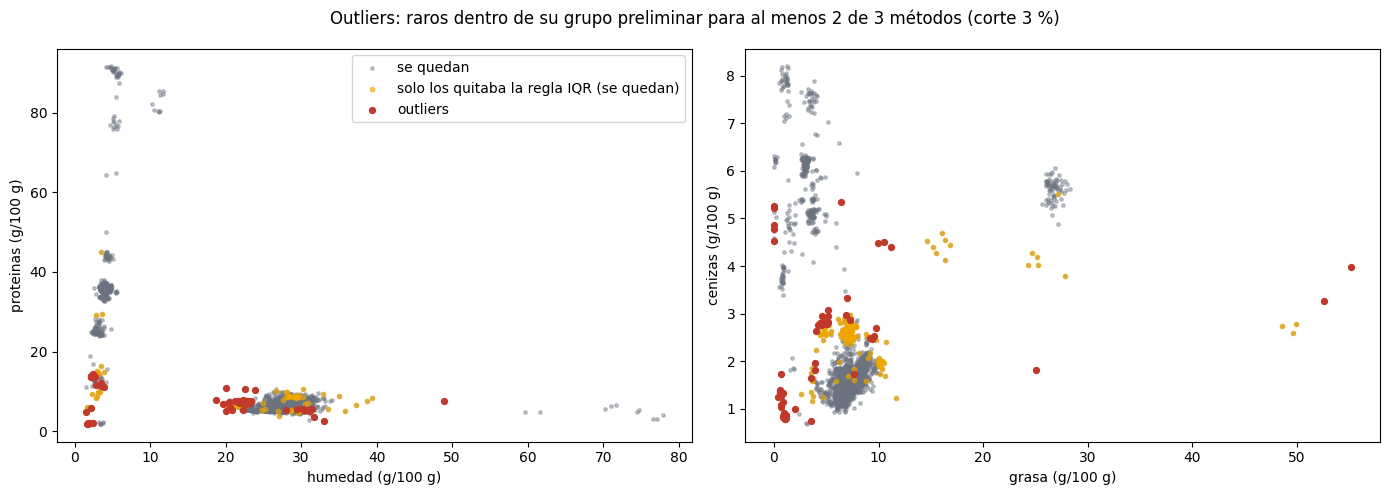

Quedan 2597 muestras


In [6]:
PCT_OUTLIER = 3                       # corte de cada método (% más raro del grupo); 2 de 3 votos
X_pre, Z_pre = muestras[COLUMNAS].to_numpy(), Z          # todas las que entran, antes de quitar (para B.5)
out_iqr, grupo_pre, K_PRE = M.outliers_iqr(Z)            # k-medias preliminar (k por silueta) y la regla IQR anterior
es_outlier, votos = M.outliers_consenso(X_pre, grupo_pre, pct=PCT_OUTLIER, minimo=2, n_vecinos=50)
ref = M.agregar_subtipo(muestras, S)                     # subtipo conocido y descripciones: NO entran, solo para comparar
muestras["subtipo_ref"] = ref["subtipo_ref"].to_numpy()
especiales = M.especiales_ddl(ref)                       # DDL repostero, heladero, reducido en grasa (por la descripción)

resumen = pd.DataFrame({"grupo preliminar": grupo_pre, "outlier": es_outlier, "regla IQR (antes)": out_iqr})
print(f"k-medias preliminar con k = {K_PRE} · outliers por consenso ({PCT_OUTLIER} %, 2 de 3): {int(es_outlier.sum())} de {len(Z)} "
      f"({100 * es_outlier.mean():.1f} %) · con la regla IQR de antes serían {int(out_iqr.sum())} ({100 * out_iqr.mean():.1f} %)")
display(resumen.groupby("grupo preliminar").agg(muestras=("outlier", "size"), outliers=("outlier", "sum"),
                                                **{"con IQR (antes)": ("regla IQR (antes)", "sum")}).assign(
    **{"% outliers": lambda t: (100 * t["outliers"] / t["muestras"]).round(1)}))
print("Cuántas marca cada método y cuántas votos juntan:", votos[["factor local", "bosque", "elipse"]].sum().to_dict(),
      "· votos:", votos["votos"].value_counts().sort_index().to_dict())
print("Consenso contra la regla IQR de antes:")
display(pd.crosstab(pd.Series(out_iqr, name="regla IQR (antes)"), pd.Series(es_outlier, name="consenso (ahora)"), margins=True))
conservados = pd.DataFrame({n: {"muestras": int(especiales[n].sum()), "se conservan (consenso)": int((especiales[n] & ~es_outlier).sum()),
                                "se conservaban (IQR)": int((especiales[n] & ~out_iqr).sum())} for n in especiales.columns}).T
print("Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):"); display(conservados)
print("Outliers por familia:", muestras.loc[es_outlier, "desc_familia"].value_counts().to_dict())
print("Algunos outliers (g/100 g), los de más votos:")
display(muestras.loc[es_outlier, ["Identificador", "desc_familia", "origen"] + COLUMNAS].assign(votos=votos.loc[es_outlier, "votos"].to_numpy())
        .sort_values("votos", ascending=False).head(12))

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in [(a, ("humedad", "proteinas")), (b, ("grasa", "cenizas"))]:
    ax.scatter(muestras.loc[~es_outlier, x], muestras.loc[~es_outlier, y], s=6, alpha=0.4, color=GRIS, label="se quedan")
    solo_iqr = out_iqr & ~es_outlier
    ax.scatter(muestras.loc[solo_iqr, x], muestras.loc[solo_iqr, y], s=10, color=AMBAR, alpha=0.6, label="solo los quitaba la regla IQR (se quedan)")
    ax.scatter(muestras.loc[es_outlier, x], muestras.loc[es_outlier, y], s=18, color=ROJO, label="outliers")
    ax.set_xlabel(f"{x} (g/100 g)"); ax.set_ylabel(f"{y} (g/100 g)")
a.legend()
fig.suptitle(f"Outliers: raros dentro de su grupo preliminar para al menos 2 de 3 métodos (corte {PCT_OUTLIER} %)")
plt.tight_layout(); plt.show()

# se guardan todas (con la marca de outlier) para el csv del final; desde acá, sin outliers
muestras_pre = muestras.assign(outlier=es_outlier)
muestras = muestras[~es_outlier].reset_index(drop=True)
familia = muestras["desc_familia"]; conocida = (familia != SIN_FAMILIA).values
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print(f"Quedan {len(muestras)} muestras")

### B · Cuántos grupos
#### B.1 · El codo y la silueta
Para k de 2 a 10: la **inercia** (baja siempre; se busca el codo) y la **silueta** promedio, (b − a)/max(a, b). Criterio
fijado antes de mirar: **k con la silueta máxima**.

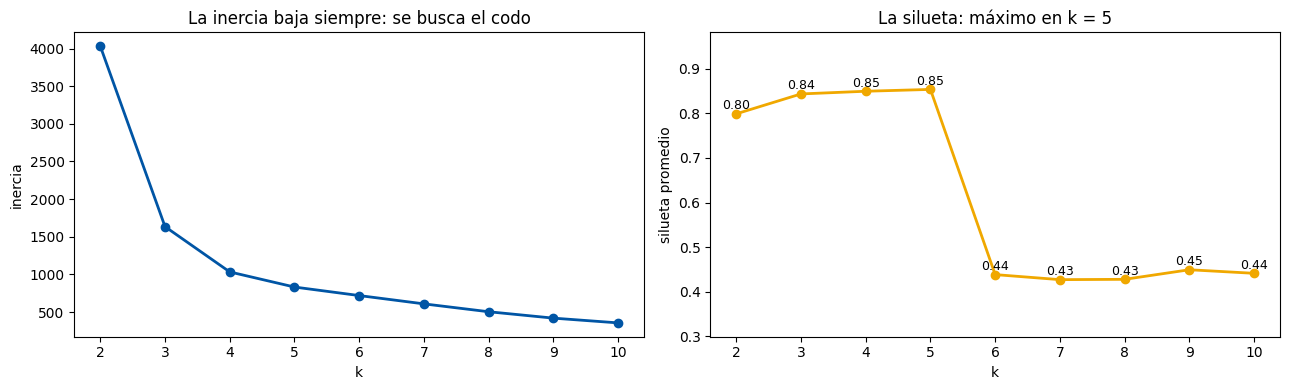

Inercia por k: {2: 4032, 3: 1635, 4: 1033, 5: 833, 6: 719, 7: 609, 8: 505, 9: 420, 10: 357}
Silueta por k: {2: 0.799, 3: 0.844, 4: 0.85, 5: 0.854, 6: 0.438, 7: 0.427, 8: 0.428, 9: 0.449, 10: 0.441}
Se elige k = 5.


In [7]:
ks = list(range(2, 11))
modelos = {k_: KMeans(n_clusters=k_, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(Z) for k_ in ks}
inercias = [modelos[k_].inertia_ for k_ in ks]; siluetas = [silhouette_score(Z, modelos[k_].labels_) for k_ in ks]
K = ks[int(np.argmax(siluetas))]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.plot(ks, inercias, marker="o", color=AZUL, lw=2); a.set_xlabel("k"); a.set_ylabel("inercia"); a.set_title("La inercia baja siempre: se busca el codo")
b.plot(ks, siluetas, marker="o", color=AMBAR, lw=2); b.set_xlabel("k"); b.set_ylabel("silueta promedio"); b.set_title(f"La silueta: máximo en k = {K}")
for k_, s_ in zip(ks, siluetas): b.text(k_, s_ + 0.01, f"{s_:.2f}", ha="center", fontsize=9)
b.margins(y=0.3); plt.tight_layout(); plt.show()
print("Inercia por k:", {k_: round(float(v)) for k_, v in zip(ks, inercias)})
print("Silueta por k:", {k_: round(float(s_), 3) for k_, s_ in zip(ks, siluetas)})
print(f"Se elige k = {K}.")

**Lectura.** A diferencia de los socios del gimnasio (silueta 0,17 a 0,21, estructura débil), acá la silueta es alta
(0,80 ya con k = 2, sin outliers): hay grupos de verdad, porque los productos tienen composiciones muy distintas. El
máximo está en **k = 5** (0,854), con k = 3 y 4 muy cerca (0,84 y 0,85); con k = 6 cae a 0,44 y sigue entre 0,43 y 0,45
hasta k = 10: no hay un sexto grupo natural. (Con pocos reinicios el k que elige el k-medias preliminar, y con él el k final, cambiaba con la
semilla; con `n_init` = 50 no.) Ojo:
el dulce de leche es el 81 % de las muestras y forma una nube muy compacta, lo que
infla el promedio de la silueta. El diagrama de B.2 lo muestra grupo por grupo, y B.5 da las métricas que no dependen
del tamaño de cada grupo.

#### B.2 · El modelo elegido, sus tags y su diagrama de silueta
Los centroides se devuelven a g/100 g para leerlos. Cada grupo recibe un **tag** con las reglas sobre su centroide
(`etiquetar` en `datos_clase41.py`): humedad > 70 → LIQUIDO; entre 35 y 65 con grasa > 15 → QUESO (se evalúa antes que alta humedad); > 50 → ALTA_HUMEDAD; > 15 → DDL;
si no es un polvo: proteína > 70 → PROT_ALTA; grasa > 15 → POLVO_GRASO; si no, POLVO_MAGRO. El número de cluster cambia
entre corridas; el tag no. Si dos grupos caen en la misma regla se desambiguan con `_2`, `_3`, ordenados por humedad.
El diagrama: un coeficiente por muestra, ordenados por grupo; la altura es cuántas muestras tiene, el ancho qué tan adentro
están, la línea roja el promedio.

Centroides en g/100 g:


,tag,muestras,humedad,grasa,proteinas,cenizas
cluster,,,,,,
0,DDL,2116,27.64,7.03,6.47,1.57
1,POLVO_MAGRO,335,3.95,2.87,33.92,5.99
2,POLVO_GRASO,87,3.07,26.55,23.40,5.33
3,LIQUIDO,10,71.50,5.67,4.82,1.16
4,PROT_ALTA,49,6.39,2.39,84.76,4.11


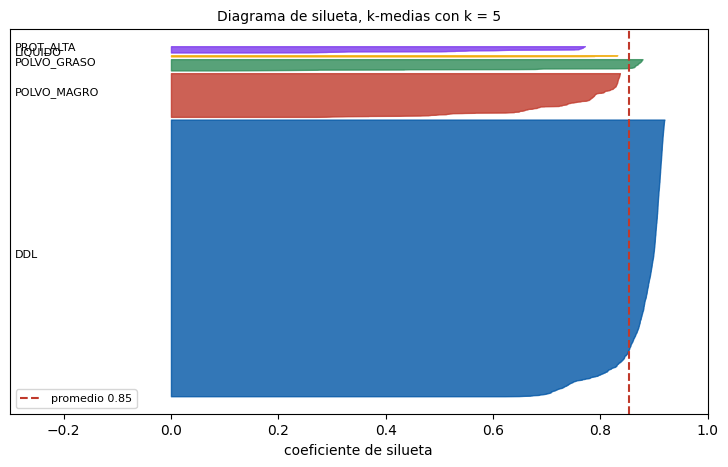

Silueta media por tag: {'DDL': 0.88, 'LIQUIDO': 0.76, 'POLVO_GRASO': 0.79, 'POLVO_MAGRO': 0.75, 'PROT_ALTA': 0.62}
Muestras con coeficiente negativo: 0 de 2597


In [8]:
km = modelos[K]; grupos = km.labels_
centros = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=COLUMNAS, index=range(K)).round(2)
nombres, tags, repetidos = etiquetar(centros)
if repetidos:
    print(f"AVISO: más de un grupo cae en {repetidos}; se desambiguan con sufijo _2, _3 (por humedad del centroide).")
tag_de = np.array([tags[g] for g in grupos])
centros.insert(0, "muestras", np.bincount(grupos)); centros.insert(0, "tag", [tags[j] for j in range(K)])
centros.index.name = "cluster"
print("Centroides en g/100 g:"); display(centros)

def diagrama_silueta(ax, X, etiquetas, titulo, rotulos):
    valores = silhouette_samples(X, etiquetas); y0 = 10
    for j in range(etiquetas.max() + 1):
        v = np.sort(valores[etiquetas == j]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORES[j], alpha=0.8)
        ax.text(-0.29, y0 + len(v) / 2, rotulos[j], fontsize=8); y0 += len(v) + 20
    ax.axvline(valores.mean(), color=ROJO, ls="--", label=f"promedio {valores.mean():.2f}")
    ax.set_xlim(-0.3, 1); ax.set_yticks([]); ax.set_xlabel("coeficiente de silueta"); ax.legend(fontsize=8); ax.set_title(titulo, fontsize=10)
    return valores

fig, ax = plt.subplots(figsize=(9, 5))
coef = diagrama_silueta(ax, Z, grupos, f"Diagrama de silueta, k-medias con k = {K}", tags)
plt.show()
print("Silueta media por tag:", pd.Series(coef).groupby(tag_de).mean().round(2).to_dict())
print(f"Muestras con coeficiente negativo: {int((coef < 0).sum())} de {len(Z)}")

#### B.5 · Métricas sin el sesgo del grupo más grande
La silueta promedio pesa cada **muestra** igual, así que la domina el DDL, que es la mayoría y forma una nube compacta.
Junto a ella (clase 43, `M.metricas`): la **silueta macro** (el promedio de las siluetas medias de cada grupo: cada
**grupo** pesa igual), la del **peor grupo**, **Davies-Bouldin** (cuánto se pisan los grupos con su vecino más
parecido; menor es mejor) y **Calinski-Harabasz** (dispersión entre grupos sobre dispersión dentro; mayor es mejor).

Para comparar el filtro de outliers nuevo con el de antes no alcanza con la silueta de cada uno sobre sus propias
muestras: el que quita más saca justo lo que está entre grupos y sale favorecido. Por eso se rehace el k-medias final
con cada filtro (`M.variante`) y se mide también sobre las **muestras comunes** (las que no quita ninguno de los dos), en
la misma escala.

In [9]:
print("Métricas del modelo elegido (sus muestras):")
display(pd.DataFrame([M.metricas(Z, grupos)]).round(3))
comunes = ~(out_iqr | es_outlier)
filtros = {}
for nombre_f, quita in [("regla IQR (antes)", out_iqr), (f"consenso {PCT_OUTLIER} % (ahora)", es_outlier)]:
    r_f, filtros[nombre_f], _ = M.variante(X_pre, quita, Z_pre, comunes)
    for e in especiales.columns:
        filtros[nombre_f][f"conserva {e}"] = int((especiales[e].to_numpy() & ~quita).sum())
assert r_f["K"] == K and (r_f["tag_de"] == tag_de).all()     # el k-medias de M.variante es el mismo de B.2
comparacion_filtros = pd.DataFrame(filtros).T.infer_objects()
print(f"Los dos filtros, cada uno con su k-medias final · muestras comunes: {int(comunes.sum())}")
display(comparacion_filtros.style.format(precision=3).format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))

Métricas del modelo elegido (sus muestras):


,grupos,ruido,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz
0,5,0,0.854,0.76,0.62,0.327,7437.45


Los dos filtros, cada uno con su k-medias final · muestras comunes: 2425


,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
regla IQR (antes),8.6,2431,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.869257,0.791109,0.615366,0.316797,9846,0.839349,0.747175,0.876348,0.798804,0.303934,616,36,0
consenso 3 % (ahora),2.4,2597,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.853913,0.759912,0.620382,0.326592,7437,0.839349,0.747175,0.876348,0.798804,0.303934,620,152,3


### F · Usarlo
#### Qué es cada grupo: cluster → tag → nombre → centroide → familia mayoritaria
El centroide en g/100 g, cuántas muestras, la familia más común y la tabla cruzada con la familia. El tag y el nombre
salen de las reglas sobre el centroide (B.2), no de la familia.

,tag,nombre,muestras,humedad,grasa,proteinas,cenizas,silueta media,familia mayoritaria,% de esa familia
cluster,,,,,,,,,,
0,DDL,pastoso tipo dulce de leche,2116,27.64,7.03,6.47,1.57,0.88,dulce de leche,100
1,POLVO_MAGRO,polvo magro (suero / concentrado),335,3.95,2.87,33.92,5.99,0.75,concentrado proteico,82
2,POLVO_GRASO,polvo graso (tipo leche entera),87,3.07,26.55,23.40,5.33,0.79,leche en polvo,82
3,LIQUIDO,líquido (leche fluida / suero),10,71.50,5.67,4.82,1.16,0.76,dulce de leche,50
4,PROT_ALTA,polvo de proteína muy alta,49,6.39,2.39,84.76,4.11,0.62,concentrado proteico,100


desc_familia,dulce de leche,concentrado proteico,leche en polvo,suero / permeado,yogur / bebida lactea,helado,arroz con leche / postre
tag,,,,,,,
DDL,2115,0,0,0,0,1,0
LIQUIDO,5,0,0,0,1,2,2
POLVO_GRASO,0,1,71,8,7,0,0
POLVO_MAGRO,0,276,29,30,0,0,0
PROT_ALTA,0,49,0,0,0,0,0


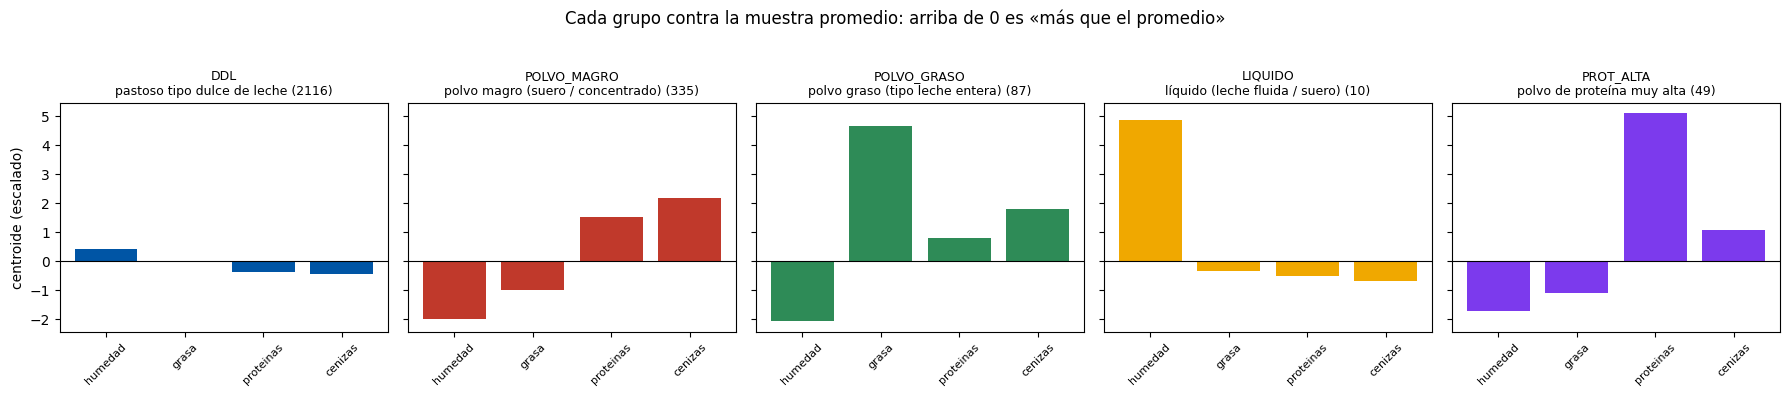

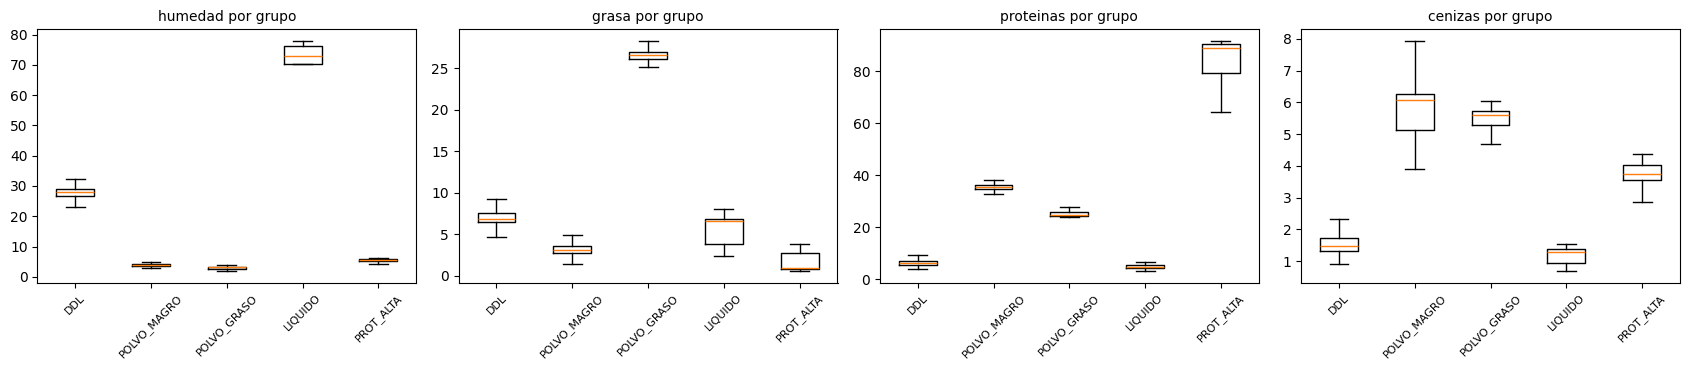

In [10]:
descripcion = centros.copy(); descripcion.insert(1, "nombre", [nombres[j] for j in range(K)])
descripcion["silueta media"] = [round(float(coef[grupos == j].mean()), 2) for j in range(K)]
fam_c = familia[conocida]; gr_c = grupos[conocida]
descripcion["familia mayoritaria"] = [fam_c[gr_c == j].mode()[0] if (gr_c == j).any() else "-" for j in range(K)]
descripcion["% de esa familia"] = [round(100 * (fam_c[gr_c == j] == fam_c[gr_c == j].mode()[0]).mean()) if (gr_c == j).any() else 0 for j in range(K)]
display(descripcion)
tabla = pd.crosstab(pd.Series(tag_de, name="tag"), familia)
display(tabla.loc[:, tabla.sum().sort_values(ascending=False).index])

fig, ejes = plt.subplots(1, K, figsize=(3.6 * K, 3.8), sharey=True)
for j, ax in enumerate(np.atleast_1d(ejes)):
    ax.bar(COLUMNAS, km.cluster_centers_[j], color=COLORES[j]); ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{tags[j]}\n{nombres[j]} ({np.bincount(grupos)[j]})", fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=8)
np.atleast_1d(ejes)[0].set_ylabel("centroide (escalado)")
fig.suptitle("Cada grupo contra la muestra promedio: arriba de 0 es «más que el promedio»", y=1.03)
plt.tight_layout(); plt.show()

fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col in zip(ejes, COLUMNAS):
    ax.boxplot([muestras.loc[grupos == j, col] for j in range(K)], tick_labels=[tags[j] for j in range(K)], showfliers=False)
    ax.set_title(f"{col} por grupo", fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout(); plt.show()

#### Segundo nivel por familia: subtags del DDL, de los polvos y del queso
El primer nivel separa tipos de producto; adentro de tres de ellos hay variantes que importan. Cada rama usa el método
que aprobó su prueba por familia (README, «Pruebas por familia»; código en `src/segundo_nivel.py`). Las ramas van por el
**tag**, no por la familia del rótulo: así el subtag queda siempre dentro de su tag y se puede predecir para una muestra
nueva con los cuatro análisis.

| rama | muestras | método | subtags |
|---|---|---|---|
| DDL | tag DDL | **regresión logística** multinomial sobre los cuatro análisis, entrenada con el subtipo conocido (`desc_subtipo`, o el de `desc_producto` o `mq_tipo_muestra.csv`); decide si la probabilidad es ≥ 0,70 y la muestra no es novedad (Mahalanobis robusta o LOF). Exactitud balanceada 0,86 en clientes no vistos (`prueba_subtipo_ddl.ipynb`) | DDL_FAMILIAR, DDL_REPOSTERO, DDL_HELADERO; «DDL» si no decide |
| polvo | tags POLVO_GRASO, POLVO_MAGRO y PROT_ALTA con humedad ≤ 15 | primero dos **reglas de composición en base seca**: suero reengrasado (grasa ≥ 15 y proteína ≤ 12) y leche descremada (grasa ≤ 2,5, cenizas ≥ 7 y proteína 30 a 40); el resto, outliers por consenso dentro de la rama y **k-medias** (k por silueta) en grasa, proteína y cenizas **en base seca**; un cluster lleva subtag si su tipo del rótulo tiene pureza ≥ 70 % y cobertura ≥ 50 % o, si no, su familia pureza ≥ 70 %, contado sin las muestras de las reglas (`prueba_clustering_polvos.ipynb`) | POLVO_SUERO_REENGRASADO, POLVO_LECHE_DESCREMADA, POLVO_LECHE_ENTERA, POLVO_WPC, POLVO_CASEINATO, POLVO_SUERO_...; el tag si no |
| queso | los quesos que confirma el catálogo (rama propia, fuera del k-medias; abajo) | **clase de humedad del CAA** (art. 605): < 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad. Coincide con la consistencia del rótulo mejor que cualquier agrupamiento (`prueba_clustering_quesos.ipynb`) | QUESO_DURO, QUESO_SEMIDURO, QUESO_PASTA_BLANDA, QUESO_MUY_ALTA_HUMEDAD |

Las dos reglas del polvo existen porque el k-medias no separa esos productos: escala la proteína con todos los polvos
(de 3 a 91 g/100 g de extracto seco), y a esa escala el suero reengrasado queda con la leche entera o con los sueros
magros, y la leche descremada (proteína 35, cenizas 8) con un concentrado de suero de 46 % de proteína y las mismas
cenizas: ningún k de 6 a 14 le da un cluster puro. Por proteína sola la leche descremada (34 a 38,5) y el WPC 35 (35 a
39) se pisan; los separan las cenizas (8,1 contra 6,2) y la grasa (1,1 contra 3,4). Los umbrales salen de los rótulos y
se verifican abajo (subtag × tipo del rótulo).

Los demás tags quedan sin subtag (su subtag es el tag). El queso no depende del k-medias: sale de su rama. El subtipo o tipo del rótulo se usa para entrenar (DDL) y para
nombrar los clusters (polvo), **nunca como entrada**. Reemplaza al segundo nivel anterior (mezcla de gaussianas dentro del
DDL, que daba DDL_HELADERO y DDL_FAMILIAR y nunca el repostero). Los subtags se juzgan por pureza y cobertura, no con la
silueta: son un segundo nivel dentro de un grupo, no grupos del primero.

In [11]:
subtag_de, criterio_de, modelos_subtag = N.ajustar(muestras, tag_de, S)
print("De dónde sale el subtag:", pd.Series(criterio_de).value_counts().to_dict())
print("Muestras por subtag:", pd.Series(subtag_de).value_counts().to_dict())
base_ = N.tag_base(tag_de)          # sin el sufijo _2, _3: los clusters repetidos van a la misma rama
ddl_ = base_ == "DDL"
m_ = modelos_subtag["DDL"]
print(f"DDL · logística entrenada con {m_['etiquetadas']} muestras con subtipo {m_['por_clase']}; "
      f"decide en {int((criterio_de[ddl_] == N.C_DDL).sum())} de {int(ddl_.sum())}")
print("DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sobre ellas mismas:")
display(pd.crosstab(subtag_de[ddl_], muestras.loc[ddl_, "subtipo_ref"].fillna("sin subtipo").to_numpy(),
                    rownames=["subtag"], colnames=["subtipo conocido"], margins=True, margins_name="total"))
if "polvo" in modelos_subtag:
    p_ = modelos_subtag["polvo"]
    print(f"Polvo · {p_['n']} muestras en la rama, {p_['n_outliers']} outliers de la rama · k-medias con k = {p_['k']} "
          f"(silueta {p_['siluetas'][p_['k']]:.3f}) · por cluster (base seca, g/100 g de extracto seco):")
    display(p_["descripcion"])
    pol_ = N.es_polvo(tag_de)
    print("Polvo · tag (filas) × subtag (columnas):")
    display(pd.crosstab(tag_de[pol_], subtag_de[pol_], rownames=["tag"], colnames=["subtag"]))
    tipo_ = N._referencias_polvo(muestras.loc[pol_, "Identificador"], S)["tipo"].fillna("sin tipo").to_numpy()
    print("Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:")
    t_ = pd.crosstab(subtag_de[pol_], tipo_, rownames=["subtag"], colnames=["tipo del rótulo"])
    display(t_.loc[:, t_.sum().sort_values(ascending=False).index])
if "queso" in modelos_subtag:
    q_ = base_ == "QUESO"
    print("Queso · subtag × familia del rótulo:")
    display(pd.crosstab(subtag_de[q_], muestras.loc[q_, "desc_familia"].to_numpy(), rownames=["subtag"], colnames=["familia"],
                        margins=True, margins_name="total"))

De dónde sale el subtag: {'DDL: logística (prob ≥ 0,70)': 1632, 'DDL: sin decidir (prob < 0,70)': 452, 'polvo: k-medias en base seca': 423, 'DDL: sin decidir (novedad)': 32, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 29, 'sin segundo nivel': 10, 'polvo: regla suero reengrasado (grasa ≥ 15, proteína ≤ 12)': 8, 'polvo: cluster sin tipo': 7, 'polvo: outlier de la rama': 4}
Muestras por subtag: {'DDL_FAMILIAR': 854, 'DDL_REPOSTERO': 621, 'DDL': 484, 'POLVO_WPC': 275, 'DDL_HELADERO': 157, 'POLVO_LECHE_ENTERA': 72, 'POLVO_CASEINATO': 39, 'POLVO_SUERO_PERMEADO': 32, 'POLVO_LECHE_DESCREMADA': 29, 'LIQUIDO': 10, 'POLVO_SUERO_REENGRASADO': 8, 'POLVO_GRASO': 7, 'POLVO_CONCENTRADO': 5, 'PROT_ALTA': 4}
DDL · logística entrenada con 1521 muestras con subtipo {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}; decide en 1632 de 2116
DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sobre ellas mismas:


subtipo conocido,FAMILIAR,HELADERO,REPOSTERO,sin subtipo,total
subtag,,,,,
DDL,145,5,122,212,484
DDL_FAMILIAR,564,0,44,246,854
DDL_HELADERO,1,146,3,7,157
DDL_REPOSTERO,39,1,451,130,621
total,749,152,620,595,2116


Polvo · 471 muestras en la rama, 8 outliers de la rama · k-medias con k = 8 (silueta 0.734) · por cluster (base seca, g/100 g de extracto seco):


,subtag,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,,
0,POLVO_SUERO_PERMEADO,32,7,1.5,11.4,5.1,82.0,3.0,SUERO DESMINERALIZADO,47.0,32,100.0,suero / permeado,94.0,-,NaN
1,(el tag),7,0,16.4,19.8,4.6,59.2,3.3,-,NaN,0,NaN,-,NaN,-,NaN
2,POLVO_LECHE_ENTERA,72,13,27.6,26.4,5.8,40.3,3.1,LECHE ENTERA,97.0,65,100.0,leche en polvo,99.0,entera,97.0
3,POLVO_WPC,98,3,3.8,37.2,5.3,53.7,4.0,WPC,99.0,98,36.0,concentrado proteico,100.0,-,NaN
4,POLVO_WPC,148,4,3.0,37.4,6.4,53.2,4.1,WPC,99.0,148,54.0,concentrado proteico,100.0,-,NaN
5,POLVO_WPC,29,2,3.7,45.1,7.8,43.3,4.3,WPC,100.0,27,10.0,concentrado proteico,100.0,-,NaN
6,POLVO_CONCENTRADO,5,1,1.3,90.5,9.0,-0.8,10.9,CASEINA,100.0,5,83.0,concentrado proteico,100.0,-,NaN
7,POLVO_CASEINATO,39,2,2.6,91.0,3.9,2.5,5.5,CASEINATO,84.0,31,100.0,concentrado proteico,100.0,-,NaN


Polvo · tag (filas) × subtag (columnas):


subtag,POLVO_CASEINATO,POLVO_CONCENTRADO,POLVO_GRASO,POLVO_LECHE_DESCREMADA,POLVO_LECHE_ENTERA,POLVO_SUERO_PERMEADO,POLVO_SUERO_REENGRASADO,POLVO_WPC,PROT_ALTA
tag,,,,,,,,,
POLVO_GRASO,0,0,7,0,72,0,8,0,0
POLVO_MAGRO,0,0,0,29,0,32,0,274,0
PROT_ALTA,39,5,0,0,0,0,0,1,4


Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:


tipo del rótulo,WPC,LECHE ENTERA,LECHE DESCREMADA,CASEINATO,sin tipo,SUERO,SUERO DESMINERALIZADO,CASEINA,PERMEADO,PROTEINAS LACTEAS,SUERO REENGRASADO,LECHE MODIFICADA,LECHE PARCIALMENTE DESCREMADA,MPC
subtag,,,,,,,,,,,,,,
POLVO_CASEINATO,2,0,0,26,8,0,0,1,0,2,0,0,0,0
POLVO_CONCENTRADO,0,0,0,0,0,0,0,5,0,0,0,0,0,0
POLVO_GRASO,0,0,0,0,7,0,0,0,0,0,0,0,0,0
POLVO_LECHE_DESCREMADA,0,0,28,0,0,0,0,0,0,0,0,0,1,0
POLVO_LECHE_ENTERA,0,63,0,0,7,0,0,0,0,0,0,1,0,1
POLVO_SUERO_PERMEADO,0,0,0,0,0,9,15,0,6,2,0,0,0,0
POLVO_SUERO_REENGRASADO,0,0,0,0,0,6,0,0,0,0,2,0,0,0
POLVO_WPC,271,0,0,0,2,0,0,0,0,2,0,0,0,0
PROT_ALTA,0,0,0,0,1,0,0,3,0,0,0,0,0,0


#### Rama de queso: fuera del k-medias de cuatro análisis
Los quesos no pasan por el k-medias: casi ninguno trae proteína ni cenizas (Senasa no las pide en queso), así que con la
regla de los cuatro análisis quedaban afuera o, si entraban, formaban un grupo débil entre el dulce de leche y los
polvos. Van a una **rama propia** con lo que sí tienen: **humedad** (100 − sólidos totales) y **materia grasa**. Solo
entra como queso **lo que confirma el catálogo**:

- **Senasa**: `desc_familia = queso`.
- **Solo MQ** (con `MQ encolumnado.xlsx`): la familia de las muestras solo MQ sale de un modelo (`mq_tipo_muestra.csv`,
  sin revisar a mano), así que no alcanza. Hace falta que el **rótulo** nombre una variedad de queso (el subtipo
  normalizado con el catálogo). Las que el modelo llama queso pero el rótulo no confirma **no entran** a la rama y siguen
  en el k-medias si tienen los cuatro análisis (desconfiar por defecto: no se les asume categoría).

Una muestra tiene **una sola asignación**: los quesos confirmados salen del k-medias (se quitan antes de elegir k y de
buscar outliers), de modo que el tag QUESO sale solo de esta rama. El **subtag** es la clase de humedad del CAA (art. 605):
< 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad (`segundo_nivel.subtag_queso`; en
`prueba_clustering_quesos.ipynb` coincide con la consistencia del rótulo mejor que cualquier agrupamiento). Se piden MG y
ST y se descartan los imposibles (MG > ST, humedad + ST fuera de 100 ± 1). Código: `clustering_quesos.rama_queso`.

In [12]:
rama = rama.copy()
rama["subtag"] = N.subtag_queso(rama["humedad"]); rama["criterio_subtag"] = N.C_QUESO
assert (rama["subtag"] == rama["caa_humedad"].map(lambda c_: "QUESO_" + Q.NOMBRE_CAA[c_])).all()   # misma regla que el CAA
print("Cuántos quesos confirma el catálogo y cuántos entran a la rama:")
print({k_: v_ for k_, v_ in conteo_q.items()})
print(f"Rama de queso: {len(rama)} muestras · por origen: {rama['origen'].value_counts().to_dict()}")
print("Subtag:", rama["subtag"].value_counts().to_dict())
display(pd.crosstab(rama["subtag"], rama["origen"], margins=True, margins_name="total"))
print("Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:")
display(pd.crosstab(rama["subtag"], rama["consistencia"].fillna("sin dato"), margins=True, margins_name="total"))
print("Con solo Senasa no hay solo MQ: todos los quesos son de desc_familia = queso.")

Cuántos quesos confirma el catálogo y cuántos entran a la rama:
{'quesos leídos': 4006, 'con MG y ST': 1627, 'excluidas: humedad + ST fuera de 100 ± 1': 0, 'excluidas: MG > ST o fuera de rango': 0, 'quedan': 1627, 'solo MQ de familia queso sin confirmar por el rótulo (no entran)': 0, 'de ellas, con MG y ST': 0}
Rama de queso: 1627 muestras · por origen: {'Senasa': 1627}
Subtag: {'QUESO_SEMIDURO': 793, 'QUESO_PASTA_BLANDA': 358, 'QUESO_DURO': 325, 'QUESO_MUY_ALTA_HUMEDAD': 151}


origen,Senasa,total
subtag,,
QUESO_DURO,325,325
QUESO_MUY_ALTA_HUMEDAD,151,151
QUESO_PASTA_BLANDA,358,358
QUESO_SEMIDURO,793,793
total,1627,1627


Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:


consistencia,alta humedad,baja humedad,mediana humedad,procesado,sin dato,untable,total
subtag,,,,,,,
QUESO_DURO,0,295,1,26,3,0,325
QUESO_MUY_ALTA_HUMEDAD,4,0,1,137,0,9,151
QUESO_PASTA_BLANDA,309,0,42,7,0,0,358
QUESO_SEMIDURO,54,6,702,21,10,0,793
total,367,301,746,191,13,9,1627


Con solo Senasa no hay solo MQ: todos los quesos son de desc_familia = queso.


#### ¿Se pueden diferenciar los quesos en clusters sin aprender de un tag previo?
Se agrupan los quesos de la rama usando **solo humedad y MGES** (grasa en el extracto seco = 100·MG/ST), estandarizadas y
sin los outliers por consenso (3 %). No se usa ningún rótulo ni el CAA para ajustar nada: **k-medias** con k por silueta
y **mezcla de gaussianas** con k por BIC. Recién después se comparan con la **clase de humedad del CAA**, la **clase de
MGES del CAA** y la **consistencia** y el **tipo** del rótulo: Rand ajustado (ARI, 0 = azar, 1 = igual) e información
mutua normalizada (NMI), tablas cruzadas y estabilidad con otras semillas (`clustering_quesos.no_supervisado`). La fila
«regla CAA de humedad» es el corte del CAA aplicado directo, sin agrupar: es el techo contra el que mirar.

1627 quesos · 43 outliers por consenso · se agrupan 1584
k-medias, silueta por k: {2: 0.425, 3: 0.483, 4: 0.518, 5: 0.52, 6: 0.457, 7: 0.479, 8: 0.469, 9: 0.431, 10: 0.436} → k = 5
Mezcla de gaussianas, BIC por k: {1: 8950, 2: 8054, 3: 7846, 4: 7155, 5: 6908, 6: 6788, 7: 6663, 8: 6672} → k = 7


,k-medias (k = 5),"mezcla de gaussianas (k = 7, BIC)",regla CAA de humedad (sin agrupar)
grupos,5.00,7.00,4.00
ruido,0.00,0.00,0.00
silueta,0.52,0.43,0.31
silueta macro,0.53,0.46,0.34
peor grupo,0.37,0.06,0.26
Davies-Bouldin,0.63,0.79,1.23
Calinski-Harabasz,1716.79,1414.79,682.30
ARI CAA humedad,0.40,0.46,1.00
NMI CAA humedad,0.53,0.58,1.00
ARI CAA MGES,0.37,0.29,0.23


k-medias (k = 5) (filas) contra CAA humedad (columnas):


CAA humedad,alta humedad,baja humedad,mediana humedad,muy alta humedad
cluster,,,,
0,0,87,0,0
1,0,200,123,0
2,104,3,530,7
3,253,0,140,1
4,1,0,0,135


k-medias (k = 5) (filas) contra CAA MGES (columnas):


CAA MGES,extra graso,graso,semigraso
cluster,,,
0,0,0,87
1,0,207,116
2,1,643,0
3,0,50,344
4,2,99,35


... (7 outputs left out)

consistencia,alta humedad,baja humedad,mediana humedad,procesado,sin dato,untable
cluster,,,,,,
0,0,77,0,0,0,0
1,0,138,0,0,0,0
2,36,77,202,2,13,0
3,9,0,534,0,0,0
4,252,0,9,25,0,0
5,68,0,0,53,0,0
6,0,0,1,85,0,3


Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:


,ARI k-medias (k fijo),ARI mezcla (k fijo),k elegido k-medias,k elegido mezcla
semilla,,,,
0,1.0,0.99,5,7
1,1.0,0.98,5,7
2,1.0,0.99,5,7
3,1.0,0.98,5,7
4,1.0,0.99,5,7
5,1.0,0.99,5,7
6,1.0,0.98,5,7
7,1.0,0.99,5,7
8,1.0,0.99,5,7


Promedio: {'ARI k-medias (k fijo)': 0.998, 'ARI mezcla (k fijo)': 0.987, 'k elegido k-medias': 5.0, 'k elegido mezcla': 7.0}


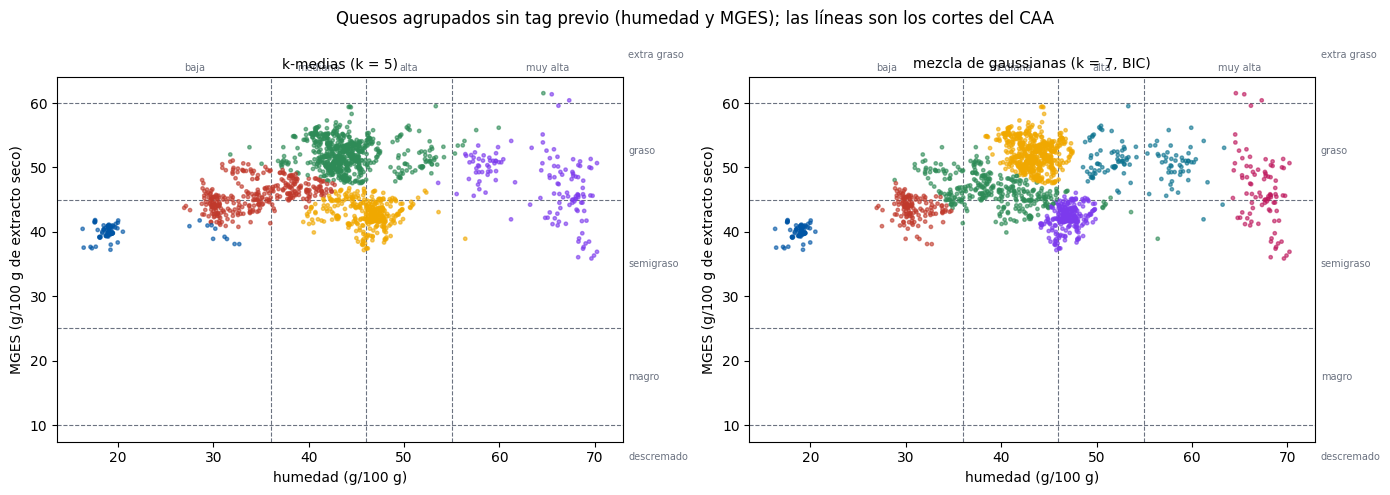

In [13]:
ns = Q.no_supervisado(rama)
print(f"{len(rama)} quesos · {ns['n_outliers']} outliers por consenso · se agrupan {len(ns['base'])}")
print("k-medias, silueta por k:", {k_: round(float(v_), 3) for k_, v_ in ns["silueta"].items()}, "→ k =", ns["k_km"])
print("Mezcla de gaussianas, BIC por k:", {k_: round(float(v_)) for k_, v_ in ns["bic"].items()}, "→ k =", ns["k_gm"])
display(ns["tabla"].round(2).T)
for (alg_, ref_), t_ in ns["cruzadas"].items():
    print(f"{alg_} (filas) contra {ref_} (columnas):")
    display(t_)
print("Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:")
display(ns["estabilidad"].round(2))
print("Promedio:", ns["estabilidad"].mean().round(3).to_dict())

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax_, (nombre_, et_) in zip(ejes, ns["et"].items()):
    ax_.scatter(ns["base"]["humedad"], ns["base"]["mges"], c=[COLORES[e_ % len(COLORES)] for e_ in et_], s=6, alpha=0.6)
    Q.lineas_caa(ax_); ax_.set_xlabel("humedad (g/100 g)"); ax_.set_ylabel("MGES (g/100 g de extracto seco)"); ax_.set_title(nombre_, fontsize=10)
fig.suptitle("Quesos agrupados sin tag previo (humedad y MGES); las líneas son los cortes del CAA")
plt.tight_layout(); plt.show()

**Respuesta.** Sí hay estructura, pero no es la del dominio y el número de grupos no es robusto. De los 1627 quesos de
Senasa, 43 salen como outliers y se agrupan 1584 (humedad y MGES estandarizadas).

- **Qué encuentra.** k-medias elige k = 5 (silueta 0,52; silueta macro 0,53; Davies-Bouldin 0,63) y la mezcla de
  gaussianas k = 7 por BIC (silueta 0,43). Son grupos más compactos que los del corte del CAA (silueta 0,31, Davies-Bouldin
  1,23): la composición no es una nube uniforme.
- **Coincidencia con el dominio.** Contra la clase de humedad del CAA el Rand ajustado (ARI) es 0,40 (k-medias) y 0,46
  (mezcla); contra la clase de MGES, 0,37 y 0,29. Los extremos se reconocen: un grupo de 135 quesos es casi puro de muy alta
  humedad (135 de 136) y otro de 87, puro de baja humedad; en el medio no hay un corte natural: dos grupos mezclan
  mediana y alta humedad (530 y 104; 140 y 253), porque el límite de 46 g/100 g del CAA cae dentro de una nube continua.
  Contra la **consistencia del rótulo** el agrupamiento da ARI 0,51 y 0,54, y la **regla del CAA aplicada directo, 0,76**:
  el corte por humedad coincide con el rótulo mejor que cualquier agrupamiento sin tag. Contra el **tipo** (variedad) pasa
  al revés: 0,46 y 0,52 contra 0,26 de la regla, porque los grupos separan también por grasa.
- **Estabilidad.** Con k fijo, otras 10 semillas dan la misma partición (ARI medio 1,00 en k-medias y 0,99 en la mezcla),
  y el k que elige la silueta es 5 en las 10 semillas (la mezcla elige 7 en las 10).

Conclusión: sin tag previo se separan grupos reproducibles en la composición, pero son una partición del continuo y
no una clasificación por tipo de queso; por eso el subtag de la rama sale de la regla del CAA, que además coincide mejor
con el rótulo.

#### Guardar: el tag y el subtag de cada muestra y el agrupamiento
`clusters_senasa.csv`: una fila por muestra que pasó el filtro (incluidos los outliers, que quedan sin cluster, tag ni subtag),
con Identificador, familia, origen, los cuatro análisis, cluster, tag, subtag (el tag cuando no hay subtag),
criterio_subtag (de qué rama y regla sale), silueta, outlier, votos_outlier (cuántos de los tres métodos la marcan) y, en
el DDL, las tres probabilidades de la logística (p_familiar, p_heladero, p_repostero). Y `agrupamiento_senasa_clase41.joblib`: imputar,
escalar y k-medias en un `Pipeline`, con el mapeo cluster → tag, los nombres, los centroides, el filtro de outliers usado
y los modelos del segundo nivel (`segundo_nivel`: la logística y los detectores de novedad del DDL; el escalador, el
k-medias, el mapeo cluster → subtag y los outliers de la rama del polvo; los cortes de humedad del queso).
`N.predecir` los usa.

In [14]:
import joblib
from sklearn.pipeline import Pipeline
muestras["cluster"] = grupos; muestras["tag"] = tag_de; muestras["subtag"] = subtag_de; muestras["criterio_subtag"] = criterio_de
muestras["silueta"] = coef
prob_ = N.probabilidades_ddl(modelos_subtag, muestras.loc[N.tag_base(tag_de) == "DDL", COLUMNAS]).round(4)
for c_ in prob_:
    muestras[c_] = np.nan
    muestras.loc[N.tag_base(tag_de) == "DDL", c_] = prob_[c_].to_numpy()
salida = muestras_pre[["Identificador", "desc_familia", "origen"] + COLUMNAS + ["outlier"]].rename(columns={"desc_familia": "familia"})
salida["votos_outlier"] = votos["votos"].to_numpy()
salida = salida.merge(muestras[["Identificador", "cluster", "tag", "subtag", "criterio_subtag", "silueta"] + list(prob_)],
                      on="Identificador", how="left")
salida["cluster"] = salida["cluster"].astype("Int64"); salida["silueta"] = salida["silueta"].round(4)
salida["rama"] = "k-medias"
filas_queso = pd.DataFrame({"Identificador": rama["Identificador"], "familia": "queso", "origen": rama["origen"], "humedad": rama["humedad"],
                            "grasa": rama["mg"], "proteinas": rama["proteina"], "cenizas": rama["cenizas"], "tag": "QUESO",
                            "subtag": rama["subtag"], "criterio_subtag": rama["criterio_subtag"], "outlier": False,
                            "rama": "queso (humedad y MG)"})
salida = pd.concat([salida, filas_queso], ignore_index=True)       # los quesos de la rama: sin cluster ni silueta
salida = salida[["Identificador", "familia", "origen", "rama"] + COLUMNAS + ["cluster", "tag", "subtag", "criterio_subtag", "silueta",
                                                                           "outlier", "votos_outlier"] + list(prob_)]
salida.to_csv(R.TABLAS / "clusters_senasa.csv", index=False, encoding="utf-8-sig")
print(f"Guardado: resultados/tablas/clusters_senasa.csv ({len(salida)} filas: {int((salida['rama'] == 'k-medias').sum())} del k-medias y {len(filas_queso)} de la rama de queso; "
      f"{int(salida['tag'].notna().sum())} con tag, {int(salida['outlier'].sum())} outliers)")
print("tag:", salida["tag"].value_counts(dropna=False).to_dict())
print("subtag:", salida["subtag"].value_counts(dropna=False).to_dict())
print("criterio_subtag:", salida["criterio_subtag"].value_counts(dropna=False).to_dict())

agrupamiento = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                         ("kmedias", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA))]).fit(muestras[COLUMNAS])
assert (agrupamiento.predict(muestras[COLUMNAS]) == grupos).all()
out_polvo_ = muestras["Identificador"].isin(modelos_subtag.get("polvo", {}).get("outliers", [])).to_numpy()
assert (N.predecir(modelos_subtag, muestras[COLUMNAS], tag_de, out_polvo_)[0] == subtag_de).all()
joblib.dump({"modelo": agrupamiento, "tags": tags, "nombres": nombres, "columnas": COLUMNAS, "centros": centros,
             "outliers": {"método": "consenso (LOF 50 vecinos, IsolationForest 200, EllipticEnvelope) dentro del k-medias preliminar",
                          "k_preliminar": K_PRE, "pct": PCT_OUTLIER, "minimo_votos": 2},
             "segundo_nivel": N.para_guardar(modelos_subtag),
             "rama_queso": {"criterio": "familia queso del catálogo (Senasa) o rótulo con variedad (solo MQ); humedad = 100 − ST; subtag por clase de humedad del CAA",
                            "cortes_humedad": N.CORTES_QUESO, "muestras": int(len(rama))}},
            R.MODELOS / "agrupamiento_senasa_clase41.joblib")
print("Guardado: resultados/modelos/agrupamiento_senasa_clase41.joblib · cluster → tag:", tags, "· ramas del segundo nivel:", list(modelos_subtag),
      "· polvo, cluster → subtag:", modelos_subtag.get("polvo", {}).get("mapa"))

Guardado: resultados/tablas/clusters_senasa.csv (4287 filas: 2660 del k-medias y 1627 de la rama de queso; 4224 con tag, 63 outliers)
tag: {'DDL': 2116, 'QUESO': 1627, 'POLVO_MAGRO': 335, 'POLVO_GRASO': 87, nan: 63, 'PROT_ALTA': 49, 'LIQUIDO': 10}
subtag: {'DDL_FAMILIAR': 854, 'QUESO_SEMIDURO': 793, 'DDL_REPOSTERO': 621, 'DDL': 484, 'QUESO_PASTA_BLANDA': 358, 'QUESO_DURO': 325, 'POLVO_WPC': 275, 'DDL_HELADERO': 157, 'QUESO_MUY_ALTA_HUMEDAD': 151, 'POLVO_LECHE_ENTERA': 72, nan: 63, 'POLVO_CASEINATO': 39, 'POLVO_SUERO_PERMEADO': 32, 'POLVO_LECHE_DESCREMADA': 29, 'LIQUIDO': 10, 'POLVO_SUERO_REENGRASADO': 8, 'POLVO_GRASO': 7, 'POLVO_CONCENTRADO': 5, 'PROT_ALTA': 4}
criterio_subtag: {'DDL: logística (prob ≥ 0,70)': 1632, 'queso: humedad del CAA': 1627, 'DDL: sin decidir (prob < 0,70)': 452, 'polvo: k-medias en base seca': 423, nan: 63, 'DDL: sin decidir (novedad)': 32, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 29, 'sin segundo nivel': 10, 'polvo: regla su

#### Cuántos datos entran en cada entrenamiento
La celda siguiente guarda los conteos de esta versión (cuántas muestras hay antes de los filtros, cuántas saca cada filtro,
cuántas entran a cada modelo); el apartado «Datos usados en cada entrenamiento», al final del cuaderno, los junta en una
tabla. No calcula nada nuevo.

In [15]:
ENTRENOS = globals().get("ENTRENOS", {})
n_nolact, n_quesos = int(no_lactea.sum()), int(a_rama.sum())
_ddl, _pol = modelos_subtag["DDL"], modelos_subtag["polvo"]
ENTRENOS["senasa"] = dict(
    inicial=n_inicial, n_hs=n_inicial - len(todas) - n_nolact - n_quesos, n_nolact=n_nolact, n_quesos=n_quesos,
    n_sin4=len(todas) - len(completas), n_suma=len(completas) - len(muestras_pre),
    pre=len(muestras_pre), k_pre=int(K_PRE), n_out=int(es_outlier.sum()), final=len(muestras), k=int(K), silueta=float(coef.mean()),
    ddl_n=int(ddl_.sum()), ddl_lab=int(_ddl["etiquetadas"]), ddl_clases=dict(_ddl["por_clase"]),
    ddl_decide=int((criterio_de[ddl_] == N.C_DDL).sum()),
    pol_tag=int(pol_.sum()), pol_rama=int(_pol["n"]), pol_out=int(_pol["n_outliers"]), pol_k=int(_pol["k"]),
    pol_sil=float(_pol["siluetas"][_pol["k"]]),
    q_leidos=int(conteo_q["quesos leídos"]), q_mgst=int(conteo_q["con MG y ST"]), q_rama=len(rama),
    q_sin_confirmar=int(conteo_q.get("solo MQ de familia queso sin confirmar por el rótulo (no entran)", 0)),
    q_out=int(ns["n_outliers"]), q_base=len(ns["base"]), q_k_km=int(ns["k_km"]), q_k_gm=int(ns["k_gm"]),
    comparacion=False)
print({k_: v_ for k_, v_ in ENTRENOS["senasa"].items()})

{'inicial': 16347, 'n_hs': 8, 'n_nolact': 1727, 'n_quesos': 4006, 'n_sin4': 7946, 'n_suma': 0, 'pre': 2660, 'k_pre': 5, 'n_out': 63, 'final': 2597, 'k': 5, 'silueta': 0.8539128512077044, 'ddl_n': 2116, 'ddl_lab': 1521, 'ddl_clases': {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}, 'ddl_decide': 1632, 'pol_tag': 471, 'pol_rama': 471, 'pol_out': 8, 'pol_k': 8, 'pol_sil': 0.733676343794965, 'q_leidos': 4006, 'q_mgst': 1627, 'q_rama': 1627, 'q_sin_confirmar': 0, 'q_out': 43, 'q_base': 1584, 'q_k_km': 5, 'q_k_gm': 7, 'comparacion': False}


### G · Qué quedó
- Solo Senasa, con las correcciones de la revisión (`correcciones_clase41.csv`, «,.» → «,», NO DETECTADO = 0) y sin
  las 8 muestras con humedad + sólidos incoherentes. Sin las familias que no son lácteas (1727 muestras, 27 con los
  cuatro análisis: los cárnicos caían en ALTA_HUMEDAD): 2660 muestras con los cuatro análisis, ninguna suma más de 102.
- Outliers **dentro de cada tipo de producto**, por consenso (k-medias preliminar con k = 5; LOF, bosque de aislamiento y
  elipse dentro de cada grupo, corte 3 %, 2 de 3 votos): 63 (2,4 %), sobre todo dulces de leche (41) y sueros (19).
  Quedan 2597. La regla anterior (Q3 + 1,5·IQR) quitaría 229 (8,6 %) y se llevaría 140 de los 176 heladeros y los 11
  reducidos en grasa; el consenso conserva 152 heladeros y 3 reducidos en grasa.
- La silueta elige **k = 5** (0,854), con estructura fuerte; los mismos cinco tags con la regla anterior de outliers. Los
  cinco grupos y su tag: **DDL** (2116, dulce de leche), **POLVO_MAGRO** (335, concentrados y sueros), **POLVO_GRASO** (87,
  leche en polvo), **PROT_ALTA** (49, concentrados de más de 80 % de proteína) y **LIQUIDO** (10, humedad media 71,5:
  dulces de leche, helados y postres muy húmedos, no líquidos de verdad). **Ya no hay un sexto grupo (POLVO_GRASO_2)**: con
  k = 6 la silueta cae a 0,44 (B.1); los sueros reengrasados, que ese grupo separaba, quedan dentro de POLVO_GRASO y el
  segundo nivel los reconoce por regla (abajo). Sin los cárnicos ya no aparece ALTA_HUMEDAD; con solo Senasa no
  aparece QUESO en el k-medias: los quesos van a su rama propia (más abajo). PROT_ALTA es el grupo más débil (silueta media 0,62).
- Sin el sesgo del DDL (B.5): silueta macro 0,760, peor grupo 0,62, Davies-Bouldin 0,33, Calinski-Harabasz 7437. La
  silueta baja respecto de la regla anterior (0,869 y macro 0,791) porque ahora quedan muestras legítimas del borde de
  cada grupo; sobre las muestras que no quita ninguno de los dos filtros, los dos modelos dan lo mismo (0,876 y macro
  0,799).
- Segundo nivel por familia. **DDL** (logística entrenada con 1521 muestras de subtipo conocido): decide en 1632 de
  2116: **DDL_FAMILIAR** 854, **DDL_REPOSTERO** 621 y **DDL_HELADERO** 157; 484 quedan como DDL (452 sin probabilidad
  suficiente y 32 novedades). A las 595 sin subtipo les propone 246 familiar, 130 repostero y 7 heladero (212 sin
  decidir), lo mismo que `prueba_subtipo_ddl.ipynb`. **Polvo** (471 muestras con humedad ≤ 15; 8 outliers de la rama;
  k-medias k = 8 en base seca, silueta 0,73): por regla, **POLVO_LECHE_DESCREMADA** 29 (28 leche descremada y 1
  parcialmente descremada: todas las descremadas) y **POLVO_SUERO_REENGRASADO** 8 (2 rotuladas suero reengrasado y 6
  rotuladas suero); por k-medias, **POLVO_WPC** 275 (tres clusters de 99 a 100 % WPC; el de 45 % de proteína en
  base seca, de 29 muestras, es casi todo de IND-70: un concentrado), **POLVO_LECHE_ENTERA** 72, **POLVO_CASEINATO** 39,
  **POLVO_SUERO_PERMEADO** 32 (suero desmineralizado, suero y permeado: nombrado por la familia) y **POLVO_CONCENTRADO** 5
  (caseína). Un cluster de 7 sin tipo (grasa 16,4 y proteína 19,8 en base seca) y 4 outliers de la rama quedan con su tag. **Queso** (rama propia,
  fuera del k-medias: ninguno de los 4006 quesos de Senasa tiene los cuatro análisis, pero 1627 tienen humedad y grasa): 1627
  muestras, QUESO_SEMIDURO 793, QUESO_PASTA_BLANDA 358, QUESO_DURO 325 y QUESO_MUY_ALTA_HUMEDAD 151. El agrupamiento sin
  tag previo de esos quesos está en la sección anterior (k-medias k = 5, mezcla k = 7; ARI 0,40 y 0,46 contra la humedad del
  CAA).
- Al revelar la familia, los grupos se leen como tipos de producto; no coinciden del todo porque algunas familias
  comparten composición (suero en polvo y concentrados magros).
- En el trabajo anterior (los dos cuadernos separados) esta versión también corría los demás algoritmos: escalar casi no
  cambiaba la partición (Rand ajustado 0,98); k-medias, Ward, los enlaces completo y promedio euclidianos y los minilotes
  llegaban a la misma partición (1,00); el bisectivo que parte el grupo más grande cortaba el dulce de leche (silueta
  0,19). En el notebook único esa comparación se hace solo en la sección 4, con Senasa + MQ.
- Cada muestra queda con su `tag`, su `subtag` y su `criterio_subtag` en `resultados/tablas/clusters_senasa.csv` (2660
  del k-medias, 63 de ellas outliers sin tag, y 1627 de la rama de queso, con `rama = queso (humedad y MG)` y sin cluster),
  y el modelo con el mapeo cluster → tag y los modelos del segundo nivel en
  `resultados/modelos/agrupamiento_senasa_clase41.joblib`.

## 4 · Agrupamiento (clase 41): Senasa + MQ

Los dos cuadernos de la clase 41 (`Clase_41_agrupamiento_simple` y `Clase_41_agrupamiento_particional_y_jerarquico`)
agrupan socios de un gimnasio. Acá se aplican **los mismos algoritmos** a `Senasa encolumnado.xlsx`, sumándole las muestras de MQ (`resultados/excel/MQ encolumnado.xlsx`, la misma estructura que Senasa). Versión hermana: sección 3 (la misma clase solo con Senasa).

Pregunta: sin decirle al algoritmo qué producto es cada muestra, **¿hay grupos de muestras de composición parecida?
¿cuántos, y cómo son?** La familia del producto (dulce de leche, leche en polvo...), cuando se conoce, cumple el papel que tenía el *plan*
en el gimnasio: **no entra** en el agrupamiento; se guarda aparte y se compara al final. A cada grupo final se le da un
**tag** corto (DDL, POLVO_GRASO, QUESO...) que sale de su centroide, no del número de cluster. Dentro del DDL, de los
polvos y del queso, un segundo nivel por familia le da a una parte de las muestras un **subtag** (DDL_REPOSTERO,
POLVO_WPC, QUESO_SEMIDURO...).

Partes: **A · k-medias y k-means++** · **B · cuántos grupos** (codo, silueta, minilotes, escalar o no) · **C · aglomerativo** (Ward, enlaces, métricas, dendrograma) · **D · bisectivo** · **E · comparativo** · **B.5 · métricas sin el sesgo del grupo más grande** · **F · usarlo** (con el segundo nivel por familia) · **G · qué quedó**.

#### Sumar los datos MQ (`resultados/excel/MQ encolumnado.xlsx`)
MQ se lee con **la misma estructura que Senasa**: de `MQ encolumnado.xlsx` (sección 7), que tiene las 177 columnas de
`Senasa encolumnado.xlsx` (texto con coma decimal; la humedad en `humedad_derivada_100_menos_solidos`, 100 − sólidos
totales) más algunas propias de MQ. Así los dos orígenes se leen, se corrigen y se filtran igual. Entran **solo los
códigos MQ** (15821): las 1839 muestras de tipo MO de `muestras_ancha.csv` quedan afuera (decisión de Matías) porque ya
forman parte de Senasa; las que tienen código en Senasa entran por Senasa como cualquier muestra de Senasa (1511 de 1839;
las otras 328 no están en Senasa y no se agregan). Se suman con la regla del proyecto (la de `build_datos_mq.py`, hoy en
`_archivo/proyecto/`): **el catálogo Senasa manda**. En una muestra que está en Senasa, MQ solo completa un análisis que
Senasa no tiene; nunca pisa un valor. Las muestras que están solo en MQ se agregan enteras, **con su `desc_familia`,
`desc_producto` y `desc_tipo_muestra` de MQ encolumnado**, y se les aplican las mismas reglas que a las de Senasa: las
familias que no son lácteas (cárnicos, panificados / otros, agua / hisopado y base nutricional: `FAMILIAS_NO_LACTEAS`) no
entran, y solo entra como queso lo que confirma el catálogo (rama de queso, más abajo). La familia de las solo MQ la
asigna un modelo (`mq_tipo_muestra.csv`) y no está revisada a mano; las que el modelo no clasifica quedan en
«sin clasificar», que no es lo mismo que «sin familia»: no se sabe que no sean lácteas y siguen al k-medias. La familia no
entra en el agrupamiento: se guarda aparte y se usa al comparar. MQ encolumnado tiene huecos donde la tabla ancha tiene
valor (se verifica en `datos_clase41.leer_mq`; donde las dos tienen valor, coinciden): esas muestras no completan los
cuatro análisis.

In [16]:
mq_crudo, mq = leer_mq()
todas, completado = unir(senasa, mq)
n_inicial = len(todas)                                     # todas las muestras de Senasa y de MQ, antes de cualquier filtro
todas = todas[~todas["Identificador"].isin(S.excluidas)]   # humedad + sólidos de Senasa incoherentes
no_lactea = todas["desc_familia"].isin(FAMILIAS_NO_LACTEAS)
print(f"Fuera por no ser lácteas ({', '.join(FAMILIAS_NO_LACTEAS)}): {int(no_lactea.sum())} muestras, "
      f"{int(todas.loc[no_lactea, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis")
todas = todas[~no_lactea]
rama, confirmados, sin_confirmar, conteo_q = Q.rama_queso(S, True)   # los quesos que confirma el catálogo van a su rama
a_rama = todas["Identificador"].isin(confirmados)
print(f"Quesos confirmados por el catálogo: {len(confirmados)} · de las muestras de acá salen {int(a_rama.sum())} "
      f"({int(todas.loc[a_rama, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis): no pasan por el k-medias")
todas = todas[~a_rama]
completas = todas.dropna(subset=COLUMNAS)
muestras = completas[completas[COLUMNAS].sum(axis=1) <= SUMA_MAX].reset_index(drop=True)
familia = muestras["desc_familia"]                  # se guarda aparte: NO entra en el agrupamiento
conocida = (familia != SIN_FAMILIA).values
print(f"MQ: {len(mq)} muestras · {int(mq['Identificador'].isin(senasa['Identificador']).sum())} también están en Senasa · "
      f"{int((todas['origen'] == 'solo MQ').sum())} solo en MQ")
print("Valores de Senasa completados con MQ, por análisis:", completado)
print(f"Con los cuatro análisis: {len(completas)} · descartadas por sumar más de {SUMA_MAX}: {len(completas) - len(muestras)} · quedan {len(muestras)}")
print("Por origen:", muestras["origen"].value_counts().to_dict())
print("Familias (no entran):", familia.value_counts().to_dict())
muestras[COLUMNAS].describe().round(2).T

Fuera por no ser lácteas (carnicos, panificados / otros, agua / hisopado, base nutricional): 2319 muestras, 68 con los cuatro análisis

Quesos confirmados por el catálogo: 5915 · de las muestras de acá salen 5915 (75 con los cuatro análisis): no pasan por el k-medias
MQ: 15821 muestras · 2079 también están en Senasa · 11241 solo en MQ
Valores de Senasa completados con MQ, por análisis: {'humedad': 851, 'grasa': 800, 'proteinas': 444, 'cenizas': 783}
Con los cuatro análisis: 3940 · descartadas por sumar más de 102: 3 · quedan 3937
Por origen: {'Senasa': 2660, 'solo MQ': 950, 'Senasa completada con MQ': 327}
Familias (no entran): {'dulce de leche': 2233, 'leche en polvo': 681, 'concentrado proteico': 390, 'suero / permeado': 268, 'leche fluida': 148, 'yogur / bebida lactea': 98, 'sin clasificar': 57, 'queso': 44, 'manteca / crema': 8, 'arroz con leche / postre': 6, 'helado': 4}


,count,mean,std,min,25%,50%,75%,max
humedad,3937.0,27.33,24.57,1.49,4.15,27.32,29.22,99.40
grasa,3937.0,9.27,8.81,0.00,4.62,6.76,8.27,72.85
proteinas,3937.0,13.56,13.98,0.00,5.68,6.96,24.61,91.63
cenizas,3937.0,2.76,2.16,0.00,1.31,1.64,5.12,21.34


#### Las cuatro columnas, una por una
Histogramas. La humedad tiene tres montones: los polvos (menos de 10 g/100 g), el dulce de leche (cerca de 28) y,
con los datos de MQ, los líquidos (leche fluida y suero, más de 80); los quesos ya no están: van a su rama propia. La
proteína va de 0 a más de 90 y las cenizas de 0 a 21: unidades y rangos muy distintos.

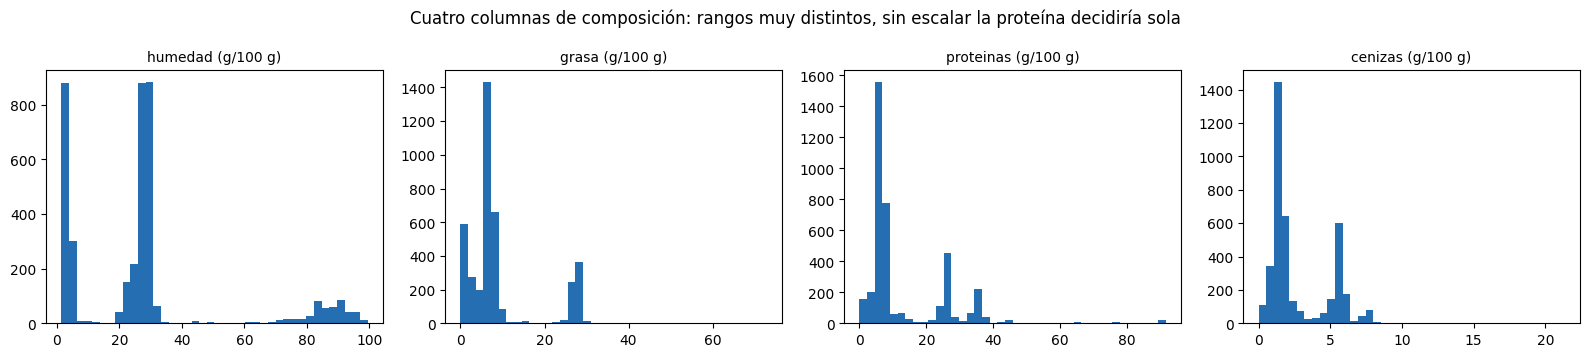

In [17]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(ejes, COLUMNAS):
    ax.hist(muestras[col], bins=40, color=AZUL, alpha=0.85); ax.set_title(f"{col} (g/100 g)", fontsize=10)
fig.suptitle("Cuatro columnas de composición: rangos muy distintos, sin escalar la proteína decidiría sola")
plt.tight_layout(); plt.show()

#### Imputar y escalar
No hay faltantes (se pidieron los cuatro análisis), pero el imputador queda en el flujo como en la clase, para que una
muestra nueva con un hueco también se pueda ubicar. Después se **escala**: media 0 y desvío 1 por columna. `Z` es lo
que ven los algoritmos.

In [18]:
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print("Desvío de cada columna antes de escalar:", {c_: round(float(muestras[c_].std()), 2) for c_ in COLUMNAS})
print(f"Z: {Z.shape[0]} muestras × {Z.shape[1]} columnas · media ≈ {Z.mean(axis=0).round(2).tolist()} · desvío ≈ {Z.std(axis=0).round(2).tolist()}")

Desvío de cada columna antes de escalar: {'humedad': 24.57, 'grasa': 8.81, 'proteinas': 13.98, 'cenizas': 2.16}
Z: 3937 muestras × 4 columnas · media ≈ [0.0, -0.0, -0.0, -0.0] · desvío ≈ [1.0, 1.0, 1.0, 1.0]


#### Quitar los outliers
Un filtro global por columna (IQR o z-score sobre todas las muestras) no sirve acá: el dulce de leche es la mayoría, y
un filtro así marcaría como «raros» a todos los polvos y líquidos, que son grupos reales. Un outlier es una muestra
rara **para su tipo de producto**. Como la familia no se puede usar (y las muestras de MQ no la tienen), el tipo sale de
un **k-medias preliminar**, con k elegido por silueta, igual que en B.1. Dentro de cada grupo se decide por **consenso**
(clase 46; `M.outliers_consenso`, probado en `prueba_mejoras_clustering.ipynb`):

1. k-medias preliminar sobre `Z`; cada muestra, a su grupo.
2. Dentro de cada grupo (de 30 muestras o más) se reescala con las muestras del grupo y se calculan tres puntajes, donde
   más bajo es más raro: el **factor local** (`LocalOutlierFactor`, 50 vecinos), el **bosque de aislamiento**
   (`IsolationForest`, 200 árboles) y la **elipse** (`EllipticEnvelope`).
3. Cada método marca el **3 %** de menor puntaje del grupo; es outlier lo que marcan **al menos 2 de los 3**.

Antes se usaba otra regla: distancia al centroide del grupo preliminar mayor que **Q3 + 1,5 · IQR** de las distancias
del grupo. Se reemplazó porque sacaba variantes legítimas del dulce de leche: el heladero (menos humedad, más cenizas)
queda lejos del centroide del DDL, y la regla IQR se llevaba casi todos. Abajo se comparan las dos reglas.

Se quitan, se vuelve a imputar y escalar con las que quedan, y **todo lo que sigue usa el conjunto sin outliers**.

k-medias preliminar con k = 5 · outliers por consenso (3 %, 2 de 3): 101 de 3937 (2.6 %) · con la regla IQR de antes serían 362 (9.2 %)


,muestras,outliers,con IQR (antes),% outliers
grupo preliminar,,,,
0,2281,55,234,2.4
1,665,21,86,3.2
2,67,1,0,1.5
3,466,12,38,2.6
4,458,12,4,2.6


Cuántas marca cada método y cuántas votos juntan: {'factor local': 119, 'bosque': 119, 'elipse': 119} · votos: {0: 3745, 1: 91, 2: 37, 3: 64}
Consenso contra la regla IQR de antes:


consenso (ahora),False,True,All
regla IQR (antes),,,
False,3562,13,3575
True,274,88,362
All,3836,101,3937


Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):


,muestras,se conservan (consenso),se conservaban (IQR)
repostero,623,622,613
heladero,176,172,35
reducido en grasa,11,11,2


Outliers por origen: {'solo MQ': 57, 'Senasa': 35, 'Senasa completada con MQ': 9}
Outliers por familia: {'suero / permeado': 29, 'sin clasificar': 21, 'queso': 21, 'dulce de leche': 8, 'manteca / crema': 8, 'concentrado proteico': 4, 'yogur / bebida lactea': 3, 'arroz con leche / postre': 3, 'helado': 2, 'leche fluida': 1, 'leche en polvo': 1}
Algunos outliers (g/100 g), los de más votos:


,Identificador,desc_familia,origen,humedad,grasa,proteinas,cenizas,votos
78,MO-07984-01,yogur / bebida lactea,Senasa,3.97,9.96,11.05,4.49,3
85,MO-08051-01,suero / permeado,Senasa,1.79,0.00,2.14,5.23,3
106,MO-08308-01,yogur / bebida lactea,Senasa,3.46,11.23,11.33,4.39,3
142,MO-08545-01,suero / permeado,Senasa,2.39,0.97,14.25,0.90,3
143,MO-08545-02,suero / permeado,Senasa,2.28,0.91,14.07,0.84,3
144,MO-08545-03,suero / permeado,Senasa,2.30,1.06,13.94,0.78,3
145,MO-08545-04,suero / permeado,Senasa,2.36,1.03,13.62,0.84,3
146,MO-08545-05,suero / permeado,Senasa,2.29,1.01,13.92,0.81,3
150,MO-08633-01,suero / permeado,Senasa,2.24,1.05,13.74,0.83,3
151,MO-08633-02,suero / permeado,Senasa,2.22,0.91,13.52,0.82,3


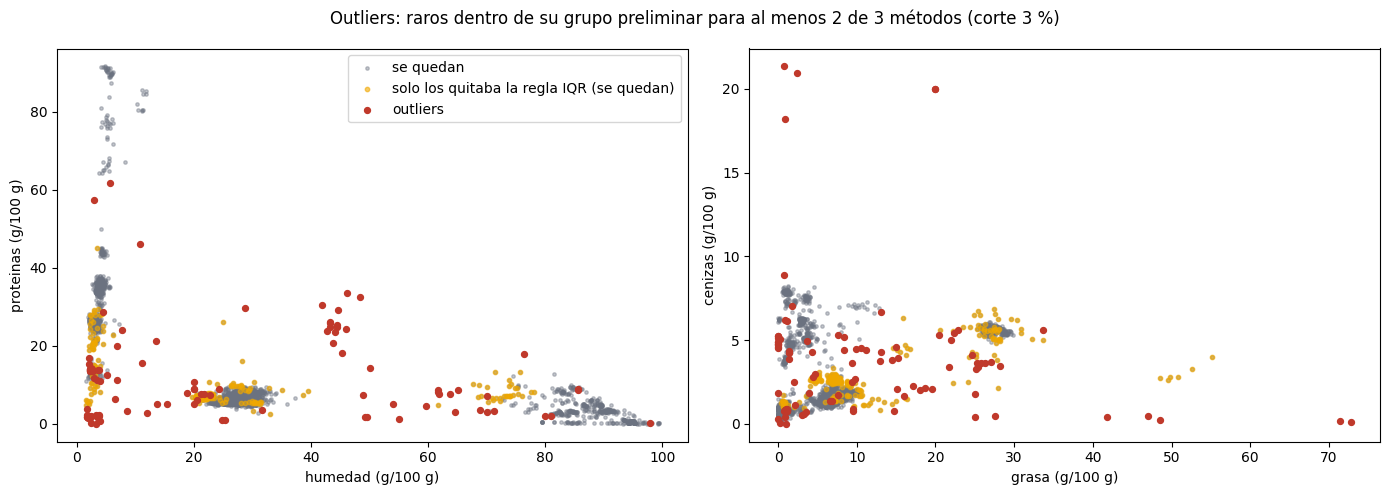

Quedan 3836 muestras · por origen: {'Senasa': 2625, 'solo MQ': 893, 'Senasa completada con MQ': 318}


In [19]:
PCT_OUTLIER = 3                       # corte de cada método (% más raro del grupo); 2 de 3 votos
X_pre, Z_pre = muestras[COLUMNAS].to_numpy(), Z          # todas las que entran, antes de quitar (para B.5)
out_iqr, grupo_pre, K_PRE = M.outliers_iqr(Z)            # k-medias preliminar (k por silueta) y la regla IQR anterior
es_outlier, votos = M.outliers_consenso(X_pre, grupo_pre, pct=PCT_OUTLIER, minimo=2, n_vecinos=50)
ref = M.agregar_subtipo(muestras, S)                     # subtipo conocido y descripciones: NO entran, solo para comparar
muestras["subtipo_ref"] = ref["subtipo_ref"].to_numpy()
especiales = M.especiales_ddl(ref)                       # DDL repostero, heladero, reducido en grasa (por la descripción)

resumen = pd.DataFrame({"grupo preliminar": grupo_pre, "outlier": es_outlier, "regla IQR (antes)": out_iqr})
print(f"k-medias preliminar con k = {K_PRE} · outliers por consenso ({PCT_OUTLIER} %, 2 de 3): {int(es_outlier.sum())} de {len(Z)} "
      f"({100 * es_outlier.mean():.1f} %) · con la regla IQR de antes serían {int(out_iqr.sum())} ({100 * out_iqr.mean():.1f} %)")
display(resumen.groupby("grupo preliminar").agg(muestras=("outlier", "size"), outliers=("outlier", "sum"),
                                                **{"con IQR (antes)": ("regla IQR (antes)", "sum")}).assign(
    **{"% outliers": lambda t: (100 * t["outliers"] / t["muestras"]).round(1)}))
print("Cuántas marca cada método y cuántas votos juntan:", votos[["factor local", "bosque", "elipse"]].sum().to_dict(),
      "· votos:", votos["votos"].value_counts().sort_index().to_dict())
print("Consenso contra la regla IQR de antes:")
display(pd.crosstab(pd.Series(out_iqr, name="regla IQR (antes)"), pd.Series(es_outlier, name="consenso (ahora)"), margins=True))
conservados = pd.DataFrame({n: {"muestras": int(especiales[n].sum()), "se conservan (consenso)": int((especiales[n] & ~es_outlier).sum()),
                                "se conservaban (IQR)": int((especiales[n] & ~out_iqr).sum())} for n in especiales.columns}).T
print("Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):"); display(conservados)
print("Outliers por origen:", muestras.loc[es_outlier, "origen"].value_counts().to_dict())
print("Outliers por familia:", muestras.loc[es_outlier, "desc_familia"].value_counts().to_dict())
print("Algunos outliers (g/100 g), los de más votos:")
display(muestras.loc[es_outlier, ["Identificador", "desc_familia", "origen"] + COLUMNAS].assign(votos=votos.loc[es_outlier, "votos"].to_numpy())
        .sort_values("votos", ascending=False).head(12))

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in [(a, ("humedad", "proteinas")), (b, ("grasa", "cenizas"))]:
    ax.scatter(muestras.loc[~es_outlier, x], muestras.loc[~es_outlier, y], s=6, alpha=0.4, color=GRIS, label="se quedan")
    solo_iqr = out_iqr & ~es_outlier
    ax.scatter(muestras.loc[solo_iqr, x], muestras.loc[solo_iqr, y], s=10, color=AMBAR, alpha=0.6, label="solo los quitaba la regla IQR (se quedan)")
    ax.scatter(muestras.loc[es_outlier, x], muestras.loc[es_outlier, y], s=18, color=ROJO, label="outliers")
    ax.set_xlabel(f"{x} (g/100 g)"); ax.set_ylabel(f"{y} (g/100 g)")
a.legend()
fig.suptitle(f"Outliers: raros dentro de su grupo preliminar para al menos 2 de 3 métodos (corte {PCT_OUTLIER} %)")
plt.tight_layout(); plt.show()

# se guardan todas (con la marca de outlier) para el csv del final; desde acá, sin outliers
muestras_pre = muestras.assign(outlier=es_outlier)
muestras = muestras[~es_outlier].reset_index(drop=True)
familia = muestras["desc_familia"]; conocida = (familia != SIN_FAMILIA).values
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print(f"Quedan {len(muestras)} muestras · por origen: {muestras['origen'].value_counts().to_dict()}")

### A · Centroides: k-medias y k-means++
#### A.1 · Asignar y mover, a mano
El algoritmo de la clase en cuatro líneas, sobre dos columnas (humedad y proteínas, escaladas) para poder dibujarlo:
k centroides iniciales; cada muestra al centroide más cercano; cada centroide a la media de su grupo; se repite. Los
centroides arrancan a propósito en las muestras de menor humedad, para ver cómo se mueven. La inercia baja en cada paso.

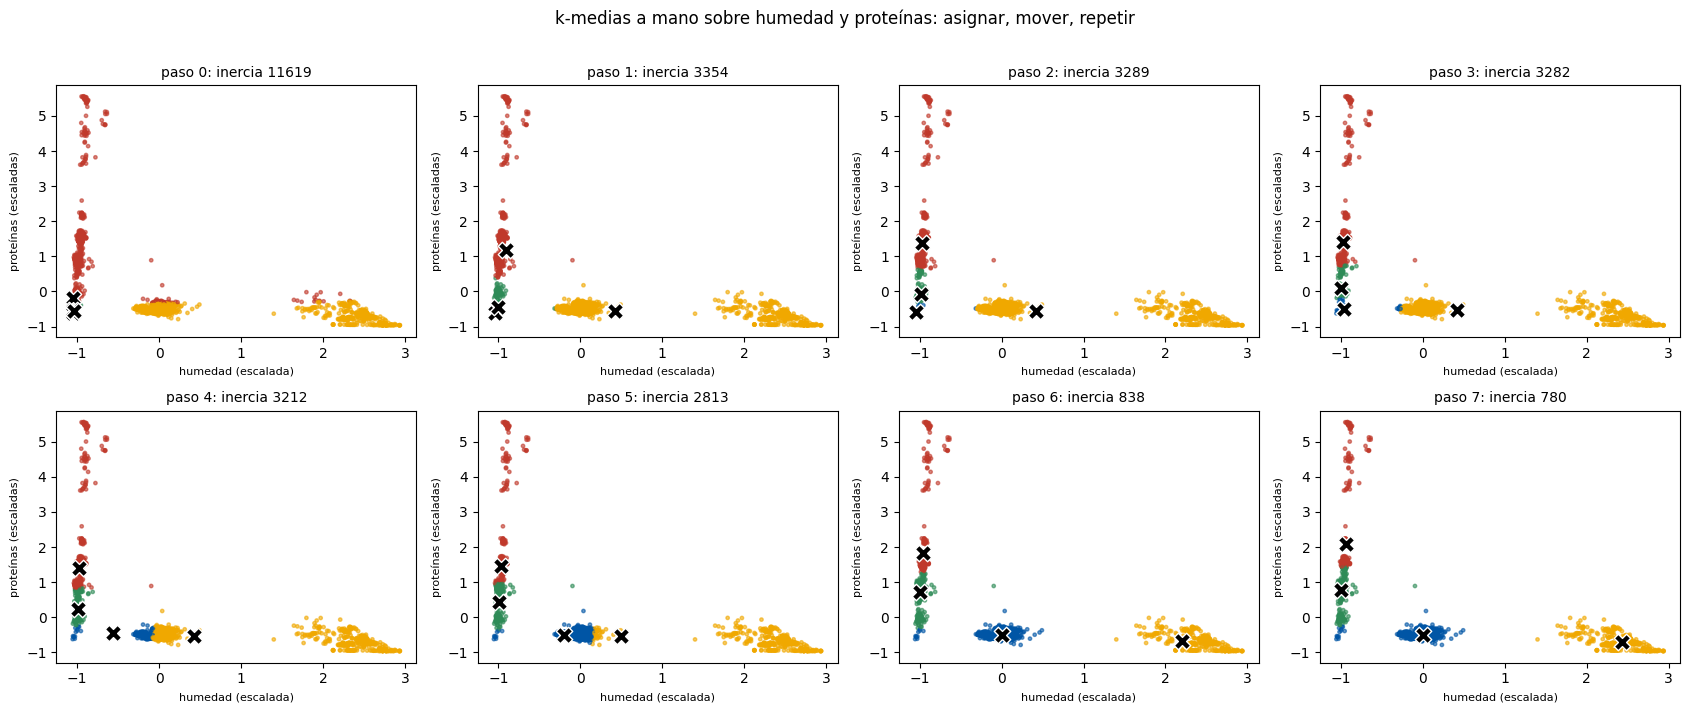

In [20]:
i_h, i_p = COLUMNAS.index("humedad"), COLUMNAS.index("proteinas")
dos = Z[:, [i_h, i_p]]

def asignar(X, centroides):
    return np.argmin(np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2), axis=1)
def mover(X, etiquetas, k, anteriores):
    return np.array([X[etiquetas == j].mean(axis=0) if (etiquetas == j).any() else anteriores[j] for j in range(k)])
def inercia(X, centroides, etiquetas):
    return float(np.sum((X - centroides[etiquetas]) ** 2))

k = 4
centroides = dos[np.argsort(dos[:, 0])[:k]]                 # todos en la humedad más baja, a propósito
fig, ejes = plt.subplots(2, 4, figsize=(17, 7)); ejes = ejes.ravel()
for paso in range(8):
    etiquetas = asignar(dos, centroides)
    ax = ejes[paso]; ax.scatter(dos[:, 0], dos[:, 1], c=[COLORES[e] for e in etiquetas], s=6, alpha=0.6)
    ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=140, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"paso {paso}: inercia {inercia(dos, centroides, etiquetas):.0f}", fontsize=10)
    ax.set_xlabel("humedad (escalada)", fontsize=8); ax.set_ylabel("proteínas (escaladas)", fontsize=8)
    nuevos = mover(dos, etiquetas, k, centroides)
    if np.allclose(nuevos, centroides):
        for ax_ in ejes[paso + 1:]: ax_.axis("off")
        break
    centroides = nuevos
fig.suptitle("k-medias a mano sobre humedad y proteínas: asignar, mover, repetir", y=1.01)
plt.tight_layout(); plt.show()

#### A.2 · Converge, pero adónde: inicialización al azar contra k-means++
Cuarenta corridas de `KMeans(init="random", n_init=1)` y cuarenta con `init="k-means++"` sobre las cuatro columnas,
con k = 4: dónde termina cada una. Por eso la biblioteca corre `n_init` veces y se queda con la menor inercia, y por eso
k-means++ (centroides iniciales elegidos con probabilidad proporcional a D(x)²) es el defecto.

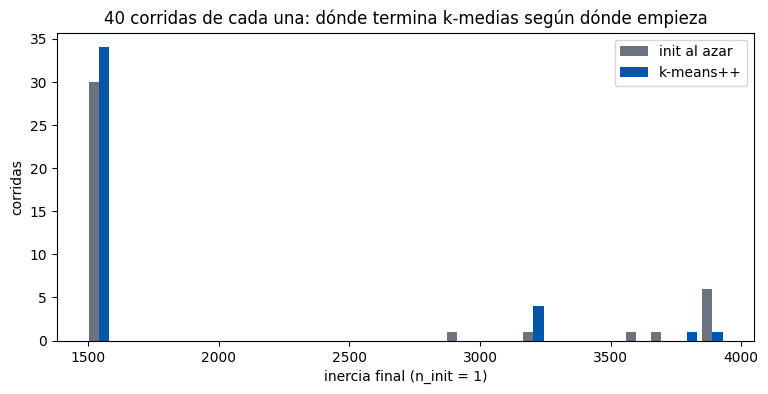

Al azar: inercia entre 1492 y 3939 · 10 de 40 terminan más de 1 % arriba de la mejor
k-means++: inercia entre 1492 y 3865 · 6 de 40 terminan más de 1 % arriba de la mejor


In [21]:
in_azar = np.array([KMeans(n_clusters=4, init="random", n_init=1, random_state=s).fit(Z).inertia_ for s in range(40)])
in_pp = np.array([KMeans(n_clusters=4, init="k-means++", n_init=1, random_state=s).fit(Z).inertia_ for s in range(40)])
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist([in_azar, in_pp], bins=25, color=[GRIS, AZUL], label=["init al azar", "k-means++"])
ax.set_xlabel("inercia final (n_init = 1)"); ax.set_ylabel("corridas"); ax.legend()
ax.set_title("40 corridas de cada una: dónde termina k-medias según dónde empieza")
plt.show()
mejor = min(in_azar.min(), in_pp.min())
print(f"Al azar: inercia entre {in_azar.min():.0f} y {in_azar.max():.0f} · {int((in_azar > mejor * 1.01).sum())} de 40 terminan más de 1 % arriba de la mejor")
print(f"k-means++: inercia entre {in_pp.min():.0f} y {in_pp.max():.0f} · {int((in_pp > mejor * 1.01).sum())} de 40 terminan más de 1 % arriba de la mejor")

### B · Cuántos grupos
#### B.1 · El codo y la silueta
Para k de 2 a 10: la **inercia** (baja siempre; se busca el codo) y la **silueta** promedio, (b − a)/max(a, b). Criterio
fijado antes de mirar: **k con la silueta máxima**.

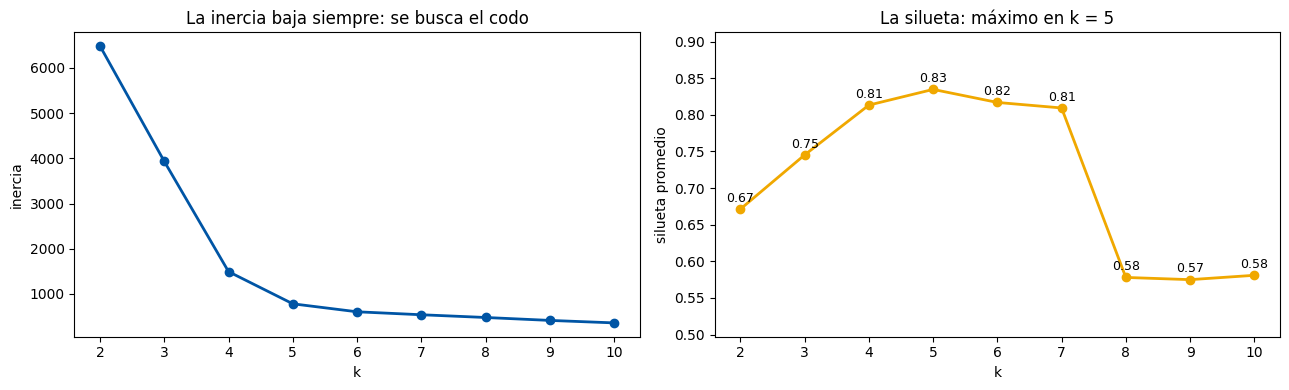

Inercia por k: {2: 6482, 3: 3930, 4: 1492, 5: 781, 6: 604, 7: 539, 8: 478, 9: 414, 10: 359}
Silueta por k: {2: 0.671, 3: 0.745, 4: 0.813, 5: 0.835, 6: 0.817, 7: 0.809, 8: 0.578, 9: 0.575, 10: 0.581}
Se elige k = 5.


In [22]:
ks = list(range(2, 11))
modelos = {k_: KMeans(n_clusters=k_, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(Z) for k_ in ks}
inercias = [modelos[k_].inertia_ for k_ in ks]; siluetas = [silhouette_score(Z, modelos[k_].labels_) for k_ in ks]
K = ks[int(np.argmax(siluetas))]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.plot(ks, inercias, marker="o", color=AZUL, lw=2); a.set_xlabel("k"); a.set_ylabel("inercia"); a.set_title("La inercia baja siempre: se busca el codo")
b.plot(ks, siluetas, marker="o", color=AMBAR, lw=2); b.set_xlabel("k"); b.set_ylabel("silueta promedio"); b.set_title(f"La silueta: máximo en k = {K}")
for k_, s_ in zip(ks, siluetas): b.text(k_, s_ + 0.01, f"{s_:.2f}", ha="center", fontsize=9)
b.margins(y=0.3); plt.tight_layout(); plt.show()
print("Inercia por k:", {k_: round(float(v)) for k_, v in zip(ks, inercias)})
print("Silueta por k:", {k_: round(float(s_), 3) for k_, s_ in zip(ks, siluetas)})
print(f"Se elige k = {K}.")

**Lectura.** A diferencia de los socios del gimnasio (silueta 0,17 a 0,21, estructura débil), acá la silueta es alta
(0,81 o más de k = 4 a 7, ya sin outliers): hay grupos de verdad, porque los productos tienen composiciones muy
distintas. Con solo Senasa también sale k = 5 (ver la sección 3); al sumar MQ entran líquidos (leche fluida, suero), que
forman un grupo propio, y la silueta es máxima en **k = 5** (0,835). Sin los quesos, que van a su rama, ya no hay un grupo
entre el dulce de leche y los polvos (en una versión anterior, con los quesos adentro, el k había sido 6, con un grupo QUESO
de 87 muestras). La curva es casi
plana entre 4 y 7 (0,81 a 0,83) y cae a 0,58 con k = 8, así que k = 5 es una elección por criterio, no una verdad. Ojo: el
dulce de leche es más de la mitad de las muestras y forma una nube muy compacta, lo que infla el promedio de la silueta. El
diagrama de B.2 lo muestra grupo por grupo, y B.5 da las métricas que no dependen del tamaño de cada grupo.

#### B.2 · El modelo elegido, sus tags y su diagrama de silueta
Los centroides se devuelven a g/100 g para leerlos. Cada grupo recibe un **tag** con las reglas sobre su centroide
(`etiquetar` en `datos_clase41.py`): humedad > 70 → LIQUIDO; entre 35 y 65 con grasa > 15 → QUESO (se evalúa antes que alta humedad); > 50 → ALTA_HUMEDAD; > 15 → DDL;
si no es un polvo: proteína > 70 → PROT_ALTA; grasa > 15 → POLVO_GRASO; si no, POLVO_MAGRO. El número de cluster cambia
entre corridas; el tag no. Si dos grupos caen en la misma regla se desambiguan con `_2`, `_3`, ordenados por humedad.
El diagrama: un coeficiente por muestra, ordenados por grupo; la altura es cuántas muestras tiene, el ancho qué tan adentro
están, la línea roja el promedio.

Centroides en g/100 g:


,tag,muestras,humedad,grasa,proteinas,cenizas
cluster,,,,,,
0,DDL,2226,27.63,6.96,6.47,1.58
1,POLVO_GRASO,644,2.88,27.42,25.32,5.58
2,POLVO_MAGRO,446,3.84,3.01,32.36,6.12
3,LIQUIDO,454,86.88,1.46,3.69,0.79
4,PROT_ALTA,66,6.07,2.64,81.00,4.60


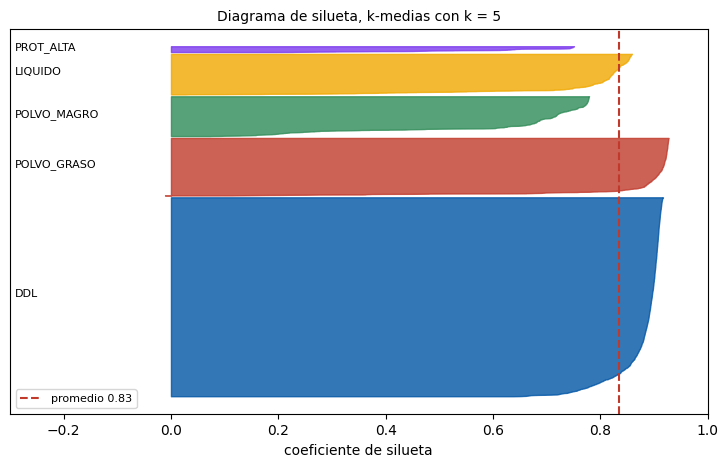

Silueta media por tag: {'DDL': 0.88, 'LIQUIDO': 0.78, 'POLVO_GRASO': 0.88, 'POLVO_MAGRO': 0.63, 'PROT_ALTA': 0.6}
Muestras con coeficiente negativo: 1 de 3836


In [23]:
km = modelos[K]; grupos = km.labels_
centros = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=COLUMNAS, index=range(K)).round(2)
nombres, tags, repetidos = etiquetar(centros)
if repetidos:
    print(f"AVISO: más de un grupo cae en {repetidos}; se desambiguan con sufijo _2, _3 (por humedad del centroide).")
tag_de = np.array([tags[g] for g in grupos])
centros.insert(0, "muestras", np.bincount(grupos)); centros.insert(0, "tag", [tags[j] for j in range(K)])
centros.index.name = "cluster"
print("Centroides en g/100 g:"); display(centros)

def diagrama_silueta(ax, X, etiquetas, titulo, rotulos):
    valores = silhouette_samples(X, etiquetas); y0 = 10
    for j in range(etiquetas.max() + 1):
        v = np.sort(valores[etiquetas == j]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORES[j], alpha=0.8)
        ax.text(-0.29, y0 + len(v) / 2, rotulos[j], fontsize=8); y0 += len(v) + 20
    ax.axvline(valores.mean(), color=ROJO, ls="--", label=f"promedio {valores.mean():.2f}")
    ax.set_xlim(-0.3, 1); ax.set_yticks([]); ax.set_xlabel("coeficiente de silueta"); ax.legend(fontsize=8); ax.set_title(titulo, fontsize=10)
    return valores

fig, ax = plt.subplots(figsize=(9, 5))
coef = diagrama_silueta(ax, Z, grupos, f"Diagrama de silueta, k-medias con k = {K}", tags)
plt.show()
print("Silueta media por tag:", pd.Series(coef).groupby(tag_de).mean().round(2).to_dict())
print(f"Muestras con coeficiente negativo: {int((coef < 0).sum())} de {len(Z)}")

#### B.5 · Métricas sin el sesgo del grupo más grande
La silueta promedio pesa cada **muestra** igual, así que la domina el DDL, que es la mayoría y forma una nube compacta.
Junto a ella (clase 43, `M.metricas`): la **silueta macro** (el promedio de las siluetas medias de cada grupo: cada
**grupo** pesa igual), la del **peor grupo**, **Davies-Bouldin** (cuánto se pisan los grupos con su vecino más
parecido; menor es mejor) y **Calinski-Harabasz** (dispersión entre grupos sobre dispersión dentro; mayor es mejor).

Para comparar el filtro de outliers nuevo con el de antes no alcanza con la silueta de cada uno sobre sus propias
muestras: el que quita más saca justo lo que está entre grupos y sale favorecido. Por eso se rehace el k-medias final
con cada filtro (`M.variante`) y se mide también sobre las **muestras comunes** (las que no quita ninguno de los dos), en
la misma escala.

In [24]:
print("Métricas del modelo elegido (sus muestras):")
display(pd.DataFrame([M.metricas(Z, grupos)]).round(3))
comunes = ~(out_iqr | es_outlier)
filtros = {}
for nombre_f, quita in [("regla IQR (antes)", out_iqr), (f"consenso {PCT_OUTLIER} % (ahora)", es_outlier)]:
    r_f, filtros[nombre_f], _ = M.variante(X_pre, quita, Z_pre, comunes)
    for e in especiales.columns:
        filtros[nombre_f][f"conserva {e}"] = int((especiales[e].to_numpy() & ~quita).sum())
assert r_f["K"] == K and (r_f["tag_de"] == tag_de).all()     # el k-medias de M.variante es el mismo de B.2
comparacion_filtros = pd.DataFrame(filtros).T.infer_objects()
print(f"Los dos filtros, cada uno con su k-medias final · muestras comunes: {int(comunes.sum())}")
display(comparacion_filtros.style.format(precision=3).format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))

Métricas del modelo elegido (sus muestras):


,grupos,ruido,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz
0,5,0,0.835,0.754,0.596,0.371,17860.286


Los dos filtros, cada uno con su k-medias final · muestras comunes: 3562


,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
regla IQR (antes),9.2,3575,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.861806,0.779391,0.584806,0.360833,23252,0.808864,0.731923,0.864367,0.784430,0.349663,613,35,2
consenso 3 % (ahora),2.6,3836,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.834644,0.753618,0.596164,0.371020,17860,0.808770,0.731274,0.864367,0.784430,0.349663,622,172,11


#### B.3 · Más rápido: Elkan y minilotes
Las dos variantes de la clase: `algorithm="elkan"` (usa la desigualdad triangular para calcular menos distancias) y
`MiniBatchKMeans` (lotes en vez de todo el conjunto). Con unas pocas miles de muestras y cuatro columnas, todo tarda
milisegundos; lo que importa es si la inercia empeora y si los grupos cambian.

In [25]:
filas = []
for nombre, modelo in [("k-medias (lloyd)", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, algorithm="lloyd", random_state=SEMILLA)),
                       ("k-medias (elkan)", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, algorithm="elkan", random_state=SEMILLA)),
                       ("minilotes (256)", MiniBatchKMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, batch_size=256, random_state=SEMILLA))]:
    t0 = time.perf_counter(); modelo.fit(Z); ms = (time.perf_counter() - t0) * 1000
    filas.append({"variante": nombre, "ms": ms, "inercia": modelo.inertia_, "silueta": silhouette_score(Z, modelo.labels_),
                  "Rand ajustado contra k-medias": adjusted_rand_score(grupos, modelo.labels_)})
display(pd.DataFrame(filas).round(3))

,variante,ms,inercia,silueta,Rand ajustado contra k-medias
0,k-medias (lloyd),44.161,780.938,0.835,1.0
1,k-medias (elkan),68.964,780.938,0.835,1.0
2,minilotes (256),77.596,787.397,0.835,1.0


#### B.4 · Sin escalar
El mismo k-medias sobre las columnas en g/100 g. La proteína y la humedad (los desvíos más grandes) dominan la
distancia; las cenizas casi no cuentan. En los socios del gimnasio esto cambiaba todo (la cuota decidía sola). Acá los
grupos están tan separados en humedad y proteína que la partición cambia poco: se mide con el Rand ajustado.

In [26]:
X_crudo = imputador.transform(muestras[COLUMNAS])
km_crudo = KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(X_crudo)
print(f"Rand ajustado entre sin escalar y escalado: {adjusted_rand_score(grupos, km_crudo.labels_):.2f}")
print("Sin escalar contra escalado (tag):"); display(pd.crosstab(pd.Series(km_crudo.labels_, name="sin escalar"), pd.Series(tag_de, name="escalado")))
print("Centroides sin escalar (g/100 g):"); display(pd.DataFrame(km_crudo.cluster_centers_, columns=COLUMNAS).round(2))

Rand ajustado entre sin escalar y escalado: 1.00
Sin escalar contra escalado (tag):


escalado,DDL,LIQUIDO,POLVO_GRASO,POLVO_MAGRO,PROT_ALTA
sin escalar,,,,,
0,2226,0,0,0,0
1,0,454,0,0,0
2,0,0,644,0,0
3,0,0,0,446,0
4,0,0,0,0,66


Centroides sin escalar (g/100 g):


,humedad,grasa,proteinas,cenizas
0,27.63,6.96,6.47,1.58
1,86.88,1.46,3.69,0.79
2,2.88,27.42,25.32,5.58
3,3.84,3.01,32.36,6.12
4,6.07,2.64,81.00,4.60


### C · Fusionar: el aglomerativo
#### C.1 · Ward
`AgglomerativeClustering(n_clusters=K, linkage="ward")`: cada muestra empieza sola y se fusionan de a dos las que menos
aumentan la varianza, hasta que quedan K. Se compara con k-medias: tamaños, tabla cruzada, Rand ajustado, silueta.

In [27]:
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
print(f"Ward: tamaños {np.bincount(ward.labels_).tolist()} · silueta {silhouette_score(Z, ward.labels_):.3f} "
      f"(k-medias {silhouette_score(Z, grupos):.3f}) · Rand ajustado contra k-medias {adjusted_rand_score(grupos, ward.labels_):.2f}")
display(pd.crosstab(pd.Series(ward.labels_, name="Ward"), pd.Series(tag_de, name="k-medias (tag)")))

Ward: tamaños [446, 2226, 644, 454, 66] · silueta 0.835 (k-medias 0.835) · Rand ajustado contra k-medias 1.00


k-medias (tag),DDL,LIQUIDO,POLVO_GRASO,POLVO_MAGRO,PROT_ALTA
Ward,,,,,
0,0,0,0,446,0
1,2226,0,0,0,0
2,0,0,644,0,0
3,0,454,0,0,0
4,0,0,0,0,66


#### C.2 · Los enlaces y las métricas
Simple, completo y promedio, con distancia euclidiana, Manhattan y coseno (Ward solo admite la euclidiana). El enlace
decide qué es «cercano» entre dos grupos; el simple encadena vecino a vecino y suele dejar un grupo gigante. La silueta
se calcula con la misma métrica, así que no es comparable entre métricas.

In [28]:
filas = []
for enlace in ["single", "complete", "average"]:
    for metrica in ["euclidean", "manhattan", "cosine"]:
        et = AgglomerativeClustering(n_clusters=K, linkage=enlace, metric=metrica).fit_predict(Z)
        filas.append({"enlace": enlace, "métrica": metrica, "tamaños": sorted(np.bincount(et).tolist(), reverse=True),
                      "silueta (misma métrica)": silhouette_score(Z, et, metric=metrica),
                      "Rand ajustado contra k-medias": adjusted_rand_score(grupos, et)})
filas.append({"enlace": "ward", "métrica": "euclidean", "tamaños": sorted(np.bincount(ward.labels_).tolist(), reverse=True),
              "silueta (misma métrica)": silhouette_score(Z, ward.labels_), "Rand ajustado contra k-medias": adjusted_rand_score(grupos, ward.labels_)})
display(pd.DataFrame(filas).round(3))

,enlace,métrica,tamaños,silueta (misma métrica),Rand ajustado contra k-medias
0,single,euclidean,"[2680, 1149, 5, 1, 1]",0.535,0.639
1,single,manhattan,"[2680, 1084, 66, 5, 1]",0.717,0.657
2,single,cosine,"[2679, 1085, 66, 5, 1]",0.297,0.643
3,complete,euclidean,"[2680, 630, 454, 66, 6]",0.748,0.725
4,complete,manhattan,"[2680, 630, 454, 66, 6]",0.772,0.725
5,complete,cosine,"[2226, 644, 454, 446, 66]",0.879,1.000
6,average,euclidean,"[2680, 637, 447, 66, 6]",0.750,0.727
7,average,manhattan,"[2680, 630, 454, 66, 6]",0.772,0.725
8,average,cosine,"[2226, 643, 454, 447, 66]",0.881,0.985
9,ward,euclidean,"[2226, 644, 454, 446, 66]",0.835,1.000


#### C.3 · El dendrograma
Con miles de muestras el árbol no se lee. Se toman 40 al azar **estratificadas por grupo de k-medias** (para que
aparezcan los grupos chicos) y se dibuja el dendrograma de Ward: la altura de cada unión es la distancia a la que se
fusionaron; se corta donde la rama vertical es más larga. Las hojas llevan el tag de k-medias y la familia, que el
algoritmo no vio.

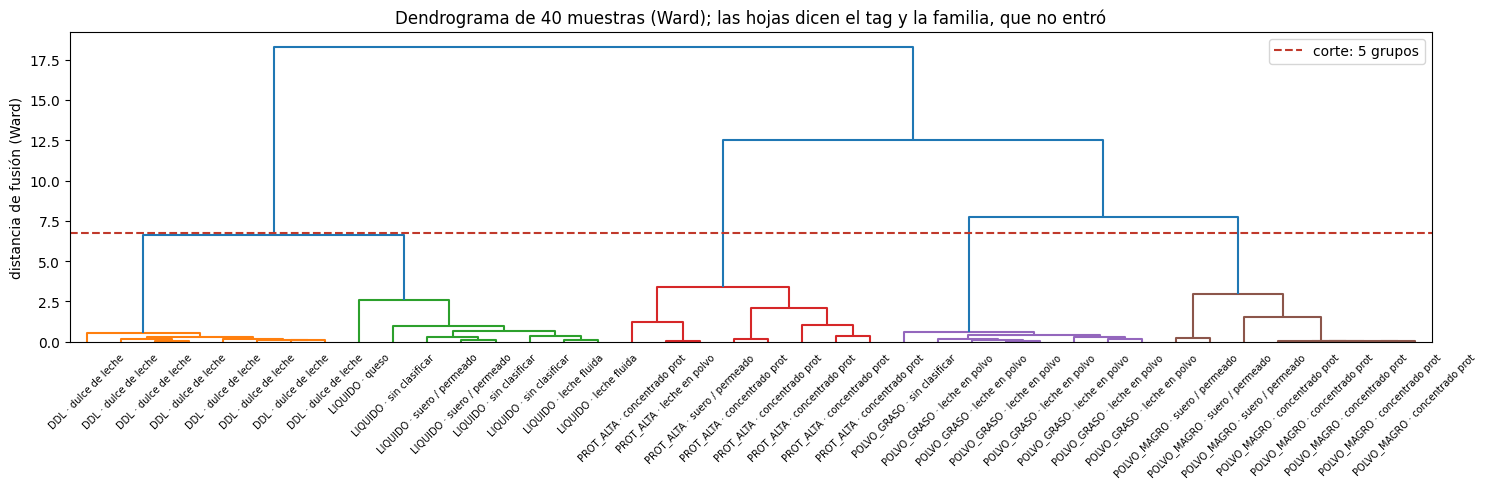

Últimas cinco fusiones a distancias [3.4, 6.6, 7.7, 12.5, 18.3] · el salto más grande deja 2 grupos


In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram
rng = np.random.default_rng(SEMILLA)
por_grupo = max(2, 40 // K)
muestra = np.concatenate([rng.choice(np.where(grupos == j)[0], min(por_grupo, int((grupos == j).sum())), replace=False) for j in range(K)])
enlaces = linkage(Z[muestra], method="ward")
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(enlaces, labels=[f"{tag_de[i]} · {familia[i][:16]}" for i in muestra], leaf_font_size=7, color_threshold=enlaces[-(K - 1), 2], ax=ax)
ax.axhline(enlaces[-(K - 1), 2] * 1.02, color=ROJO, ls="--", label=f"corte: {K} grupos"); ax.set_ylabel("distancia de fusión (Ward)"); ax.legend()
ax.set_title(f"Dendrograma de {len(muestra)} muestras (Ward); las hojas dicen el tag y la familia, que no entró")
plt.tight_layout(); plt.show()
saltos = np.diff(enlaces[:, 2]); k_sugerido = len(enlaces) + 1 - (int(np.argmax(saltos)) + 1)
print(f"Últimas cinco fusiones a distancias {enlaces[-5:, 2].round(1).tolist()} · el salto más grande deja {k_sugerido} grupos")

### D · Dividir: k-medias bisectivo
`BisectingKMeans`: parte un grupo en dos, y otra vez, hasta K. Las dos estrategias para elegir qué grupo partir: el más
grande o el de mayor inercia. Primero se ven las divisiones sucesivas sobre humedad y proteínas.

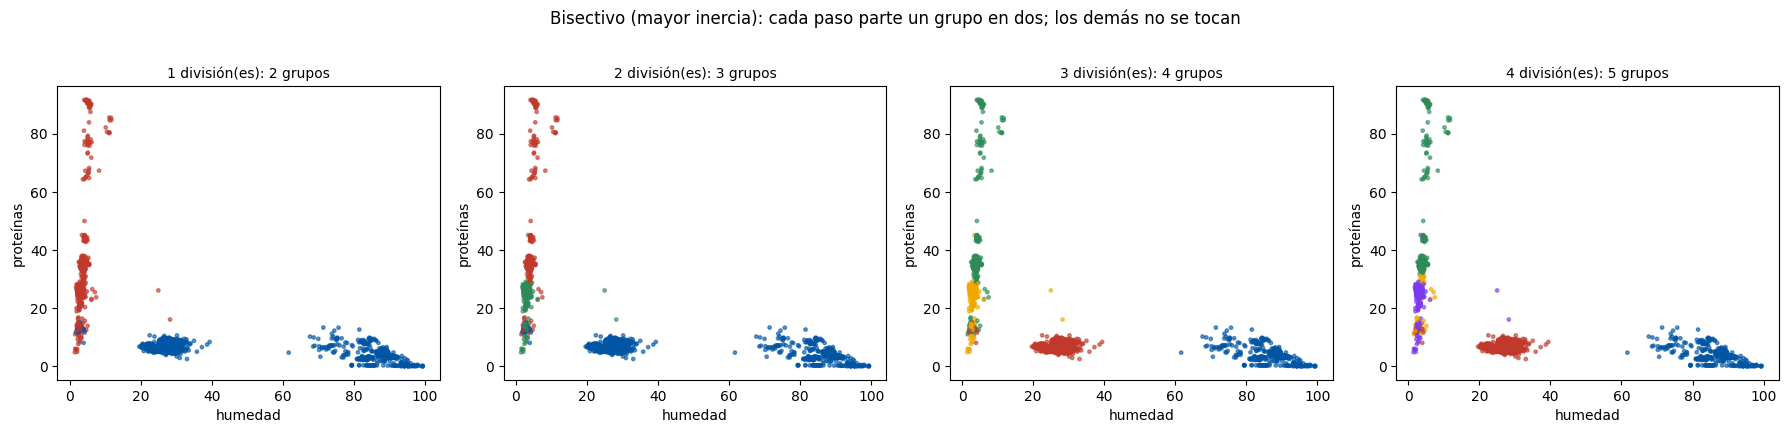

,estrategia,tamaños,inercia,silueta,Rand ajustado contra k-medias
0,largest_cluster,"[454, 182, 1258, 824, 1118]",3840.415,0.424,0.486
1,biggest_inertia,"[454, 2264, 428, 47, 643]",1371.167,0.772,0.960
2,k-medias (referencia),"[2226, 644, 446, 454, 66]",780.938,0.835,1.000


In [30]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, kb in zip(ejes, [2, 3, 4, 5]):
    bk = BisectingKMeans(n_clusters=kb, bisecting_strategy="biggest_inertia", random_state=SEMILLA).fit(Z)
    ax.scatter(muestras["humedad"], muestras["proteinas"], c=[COLORES[e] for e in bk.labels_], s=6, alpha=0.6)
    ax.set_title(f"{kb - 1} división(es): {kb} grupos", fontsize=10); ax.set_xlabel("humedad"); ax.set_ylabel("proteínas")
fig.suptitle("Bisectivo (mayor inercia): cada paso parte un grupo en dos; los demás no se tocan", y=1.02)
plt.tight_layout(); plt.show()
filas = []
for estrategia in ["largest_cluster", "biggest_inertia"]:
    bk = BisectingKMeans(n_clusters=K, bisecting_strategy=estrategia, random_state=SEMILLA).fit(Z)
    filas.append({"estrategia": estrategia, "tamaños": np.bincount(bk.labels_).tolist(), "inercia": bk.inertia_,
                  "silueta": silhouette_score(Z, bk.labels_), "Rand ajustado contra k-medias": adjusted_rand_score(grupos, bk.labels_)})
filas.append({"estrategia": "k-medias (referencia)", "tamaños": np.bincount(grupos).tolist(), "inercia": km.inertia_,
              "silueta": silhouette_score(Z, grupos), "Rand ajustado contra k-medias": 1.0})
display(pd.DataFrame(filas).round(3))

### E · El comparativo: cuál para qué
Los cuatro algoritmos con K grupos: silueta, inercia, tiempo, tamaños y coincidencia con k-medias. Y, recién ahora,
la **familia** (que ninguno vio): Rand ajustado contra la familia.

,algoritmo,silueta,inercia,ms,tamaños,Rand ajustado contra k-medias,Rand ajustado contra la familia (conocida)
0,k-medias,0.835,780.938,43.302,"[2226, 644, 454, 446, 66]",1.00,0.921
1,minilotes,0.835,781.261,61.586,"[2226, 644, 454, 446, 66]",1.00,0.921
2,aglomerativo (Ward),0.835,NaN,213.754,"[2226, 644, 454, 446, 66]",1.00,0.921
3,bisectivo,0.772,1371.167,5.385,"[2264, 643, 454, 428, 47]",0.96,0.908


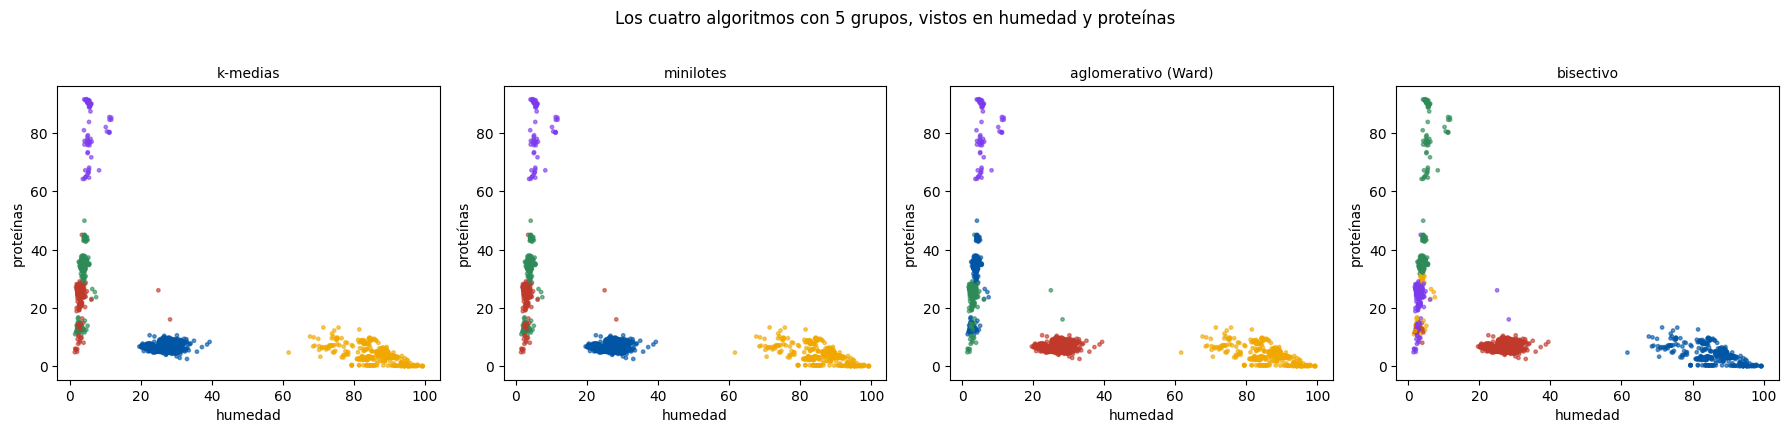

In [31]:
filas, particiones = [], {}
for nombre, modelo in [("k-medias", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA)),
                       ("minilotes", MiniBatchKMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA)),
                       ("aglomerativo (Ward)", AgglomerativeClustering(n_clusters=K, linkage="ward")),
                       ("bisectivo", BisectingKMeans(n_clusters=K, bisecting_strategy="biggest_inertia", random_state=SEMILLA))]:
    t0 = time.perf_counter(); et = modelo.fit_predict(Z); ms = (time.perf_counter() - t0) * 1000
    particiones[nombre] = et
    filas.append({"algoritmo": nombre, "silueta": silhouette_score(Z, et), "inercia": getattr(modelo, "inertia_", np.nan), "ms": ms,
                  "tamaños": sorted(np.bincount(et).tolist(), reverse=True), "Rand ajustado contra k-medias": adjusted_rand_score(grupos, et),
                  "Rand ajustado contra la familia (conocida)": adjusted_rand_score(familia[conocida], et[conocida])})
display(pd.DataFrame(filas).round(3))

fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (nombre, et) in zip(ejes, particiones.items()):
    ax.scatter(muestras["humedad"], muestras["proteinas"], c=[COLORES[e] for e in et], s=6, alpha=0.6)
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("humedad"); ax.set_ylabel("proteínas")
fig.suptitle(f"Los cuatro algoritmos con {K} grupos, vistos en humedad y proteínas", y=1.02)
plt.tight_layout(); plt.show()

### F · Usarlo
#### Qué es cada grupo: cluster → tag → nombre → centroide → familia mayoritaria
El centroide en g/100 g, cuántas muestras, la familia más común y la tabla cruzada con la familia. El tag y el nombre
salen de las reglas sobre el centroide (B.2), no de la familia.

,tag,nombre,muestras,humedad,grasa,proteinas,cenizas,silueta media,familia mayoritaria,% de esa familia,% solo MQ
cluster,,,,,,,,,,,
0,DDL,pastoso tipo dulce de leche,2226,27.63,6.96,6.47,1.58,0.88,dulce de leche,100,3
1,POLVO_GRASO,polvo graso (tipo leche entera),644,2.88,27.42,25.32,5.58,0.88,leche en polvo,93,79
2,POLVO_MAGRO,polvo magro (suero / concentrado),446,3.84,3.01,32.36,6.12,0.63,concentrado proteico,65,17
3,LIQUIDO,líquido (leche fluida / suero),454,86.88,1.46,3.69,0.79,0.78,leche fluida,32,50
4,PROT_ALTA,polvo de proteína muy alta,66,6.07,2.64,81.00,4.60,0.60,concentrado proteico,88,14


desc_familia,dulce de leche,leche en polvo,concentrado proteico,suero / permeado,leche fluida,yogur / bebida lactea,sin clasificar,queso,arroz con leche / postre,helado
tag,,,,,,,,,,
DDL,2220,0,0,0,2,0,3,0,0,1
LIQUIDO,5,1,38,144,145,88,7,22,3,1
POLVO_GRASO,0,600,1,13,0,7,23,0,0,0
POLVO_MAGRO,0,74,289,79,0,0,3,1,0,0
PROT_ALTA,0,5,58,3,0,0,0,0,0,0


Grupos contra el origen del dato:


origen,Senasa,Senasa completada con MQ,solo MQ
tag,,,
DDL,2149,4,73
LIQUIDO,9,217,228
POLVO_GRASO,89,47,508
POLVO_MAGRO,329,42,75
PROT_ALTA,49,8,9


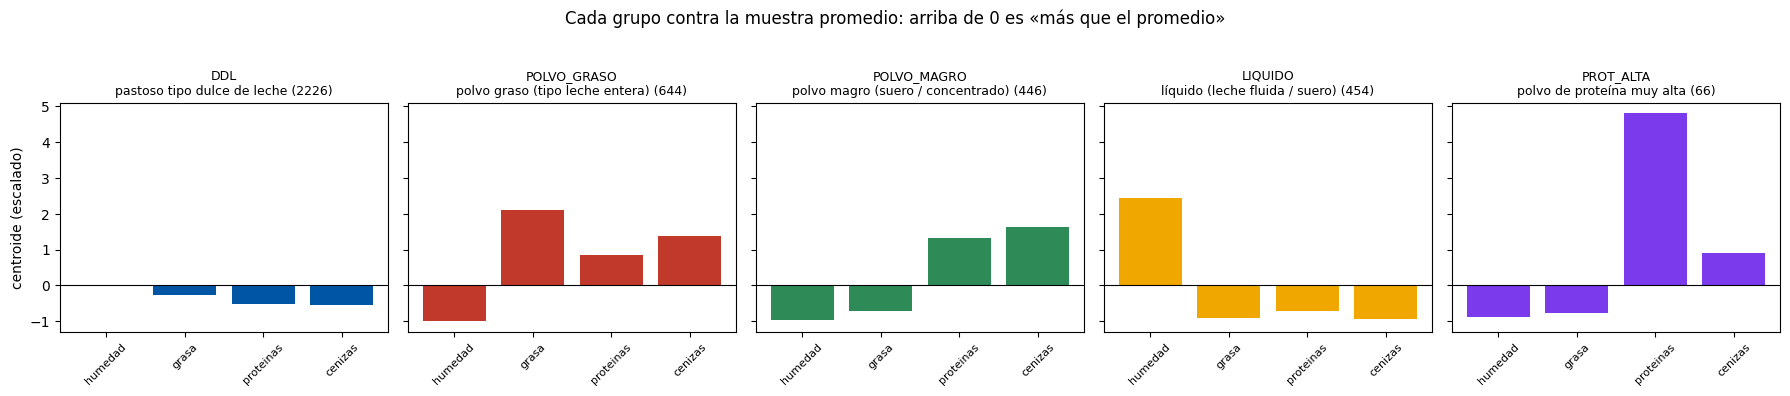

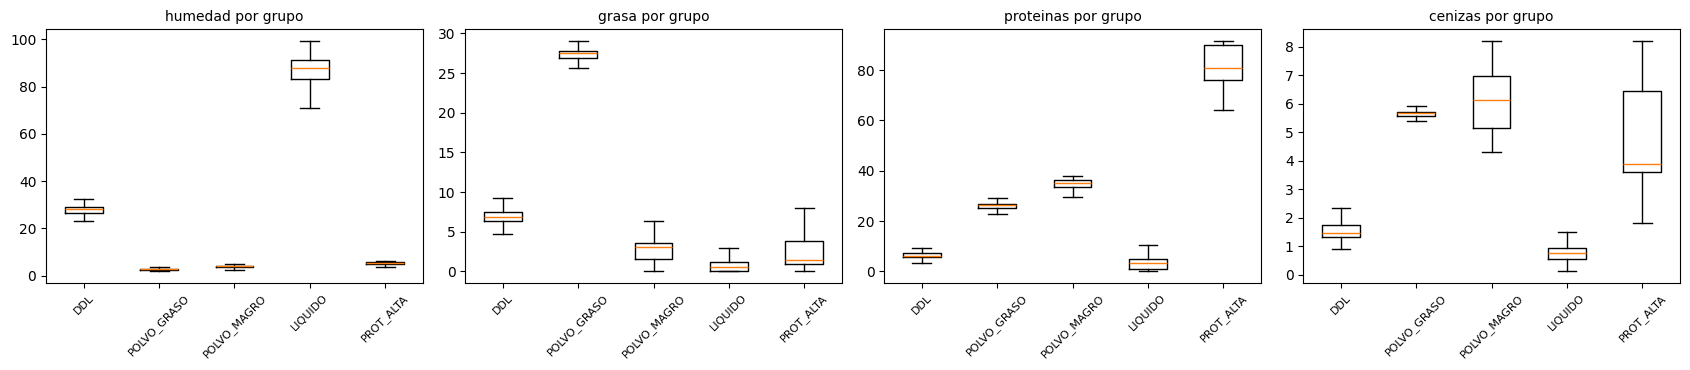

In [32]:
descripcion = centros.copy(); descripcion.insert(1, "nombre", [nombres[j] for j in range(K)])
descripcion["silueta media"] = [round(float(coef[grupos == j].mean()), 2) for j in range(K)]
fam_c = familia[conocida]; gr_c = grupos[conocida]
descripcion["familia mayoritaria"] = [fam_c[gr_c == j].mode()[0] if (gr_c == j).any() else "-" for j in range(K)]
descripcion["% de esa familia"] = [round(100 * (fam_c[gr_c == j] == fam_c[gr_c == j].mode()[0]).mean()) if (gr_c == j).any() else 0 for j in range(K)]
descripcion["% solo MQ"] = [round(100 * (muestras.loc[grupos == j, "origen"] == "solo MQ").mean()) for j in range(K)]
display(descripcion)
tabla = pd.crosstab(pd.Series(tag_de, name="tag"), familia)
display(tabla.loc[:, tabla.sum().sort_values(ascending=False).index])
print("Grupos contra el origen del dato:"); display(pd.crosstab(pd.Series(tag_de, name="tag"), muestras["origen"]))

fig, ejes = plt.subplots(1, K, figsize=(3.6 * K, 3.8), sharey=True)
for j, ax in enumerate(np.atleast_1d(ejes)):
    ax.bar(COLUMNAS, km.cluster_centers_[j], color=COLORES[j]); ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{tags[j]}\n{nombres[j]} ({np.bincount(grupos)[j]})", fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=8)
np.atleast_1d(ejes)[0].set_ylabel("centroide (escalado)")
fig.suptitle("Cada grupo contra la muestra promedio: arriba de 0 es «más que el promedio»", y=1.03)
plt.tight_layout(); plt.show()

fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col in zip(ejes, COLUMNAS):
    ax.boxplot([muestras.loc[grupos == j, col] for j in range(K)], tick_labels=[tags[j] for j in range(K)], showfliers=False)
    ax.set_title(f"{col} por grupo", fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout(); plt.show()

#### Los grupos en dos pares de columnas
Todas las muestras con el color de su grupo (calculado con las cuatro columnas) y su tag.

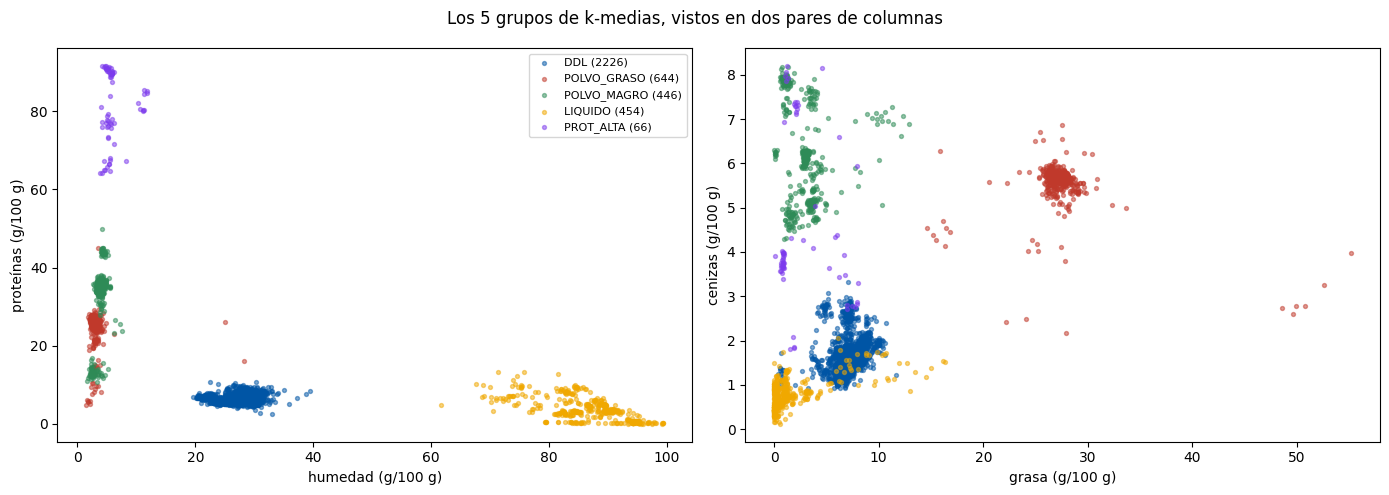

In [33]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
for j in range(K):
    sel = grupos == j
    a.scatter(muestras.loc[sel, "humedad"], muestras.loc[sel, "proteinas"], s=8, alpha=0.5, color=COLORES[j], label=f"{tags[j]} ({sel.sum()})")
    b.scatter(muestras.loc[sel, "grasa"], muestras.loc[sel, "cenizas"], s=8, alpha=0.5, color=COLORES[j])
a.set_xlabel("humedad (g/100 g)"); a.set_ylabel("proteínas (g/100 g)"); a.legend(fontsize=8)
b.set_xlabel("grasa (g/100 g)"); b.set_ylabel("cenizas (g/100 g)")
fig.suptitle(f"Los {K} grupos de k-medias, vistos en dos pares de columnas")
plt.tight_layout(); plt.show()

#### Una muestra nueva
Se arma la fila, se imputa y escala con lo aprendido; `predict` da el grupo (y su tag) y `transform` la distancia a cada
centroide. Dos ejemplos: un dulce de leche típico y una leche en polvo entera.

In [34]:
nuevas = pd.DataFrame([{"humedad": 28.0, "grasa": 7.0, "proteinas": 6.5, "cenizas": 1.6},
                       {"humedad": 3.0, "grasa": 26.0, "proteinas": 25.0, "cenizas": 5.8}], index=["dulce de leche típico", "leche en polvo entera"])[COLUMNAS]
z_nuevas = escalador.transform(imputador.transform(nuevas))
for (etiqueta, fila), z in zip(nuevas.iterrows(), z_nuevas):
    g = int(km.predict(z[None, :])[0]); d = km.transform(z[None, :])[0]
    print(f"{etiqueta} {fila.to_dict()} → {tags[g]} ({nombres[g]}) · distancias: { {tags[j]: round(float(v), 2) for j, v in enumerate(d)} }")

dulce de leche típico {'humedad': 28.0, 'grasa': 7.0, 'proteinas': 6.5, 'cenizas': 1.6} → DDL (pastoso tipo dulce de leche) · distancias: {'DDL': 0.02, 'POLVO_GRASO': 3.49, 'POLVO_MAGRO': 3.06, 'LIQUIDO': 2.53, 'PROT_ALTA': 5.6}
leche en polvo entera {'humedad': 3.0, 'grasa': 26.0, 'proteinas': 25.0, 'cenizas': 5.8} → POLVO_GRASO (polvo graso (tipo leche entera)) · distancias: {'DDL': 3.43, 'POLVO_GRASO': 0.2, 'POLVO_MAGRO': 2.72, 'LIQUIDO': 5.29, 'PROT_ALTA': 4.86}


#### Diez muestras, con su tag y su silueta
Diez muestras elegidas para cubrir el rango de la silueta: de la que está bien adentro de su grupo a la que está sobre
un límite (o del lado equivocado). Es la tabla para discutir: ¿la muestra mal ubicada es un error de carga, un producto
raro, o un grupo que falta?

In [35]:
objetivos = np.linspace(coef.max(), coef.min(), 10); elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(coef - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
explicado = muestras.loc[elegidos, ["Identificador", "desc_familia", "desc_producto"] + COLUMNAS].copy()
explicado["tag"] = tag_de[elegidos]
explicado["silueta"] = coef[elegidos].round(3)
explicado.style.format(precision=2).background_gradient(subset=["silueta"], cmap="RdYlGn", vmin=-0.3, vmax=1)

,Identificador,desc_familia,desc_producto,humedad,grasa,proteinas,cenizas,tag,silueta
3817,MQ-46324-01,leche en polvo,nan,2.52,27.52,26.34,5.64,POLVO_GRASO,0.93
2796,MQ-43994-01,suero / permeado,PERMEADO DE LECHE LIQUIDO UF,94.57,0.00,0.23,0.50,LIQUIDO,0.82
426,MO-10908-04,concentrado proteico,CONCENTRADO DE PROTEINAS DE SUERO DE QUESO EN POLVO,4.13,3.46,34.83,5.12,POLVO_MAGRO,0.72
2830,MQ-44236-01,concentrado proteico,POLVO CONCENTRADO DE PROTEINAS MUESTRAS · OBSERV,4.23,7.73,77.33,2.76,PROT_ALTA,0.61
3437,MQ-44509-01,sin clasificar,nan,7.14,7.98,25.50,5.49,POLVO_MAGRO,0.51
3039,MQ-40658-01,suero / permeado,nan,4.16,10.86,31.09,6.96,POLVO_MAGRO,0.41
2643,MQ-43201-01,suero / permeado,SUERO EN POLVO,5.48,2.01,67.49,7.30,PROT_ALTA,0.30
2340,MQ-40513-01,suero / permeado,SUERO DESMINERALIZADO EN POLVO,2.58,1.41,13.88,4.64,POLVO_MAGRO,0.20
379,MO-10554-01,suero / permeado,SUERO EN POLVO PARCIALMENTE DESMINERALIZADO,4.15,1.43,12.34,4.50,POLVO_MAGRO,0.09
3299,MQ-42969-01,sin clasificar,nan,3.96,22.19,8.09,2.42,POLVO_GRASO,-0.01


#### Segundo nivel por familia: subtags del DDL, de los polvos y del queso
El primer nivel separa tipos de producto; adentro de tres de ellos hay variantes que importan. Cada rama usa el método
que aprobó su prueba por familia (README, «Pruebas por familia»; código en `src/segundo_nivel.py`). Las ramas van por el
**tag**, no por la familia del rótulo: así el subtag queda siempre dentro de su tag y se puede predecir para una muestra
nueva con los cuatro análisis.

| rama | muestras | método | subtags |
|---|---|---|---|
| DDL | tag DDL | **regresión logística** multinomial sobre los cuatro análisis, entrenada con el subtipo conocido (`desc_subtipo`, o el de `desc_producto` o `mq_tipo_muestra.csv`); decide si la probabilidad es ≥ 0,70 y la muestra no es novedad (Mahalanobis robusta o LOF). Exactitud balanceada 0,86 en clientes no vistos (`prueba_subtipo_ddl.ipynb`) | DDL_FAMILIAR, DDL_REPOSTERO, DDL_HELADERO; «DDL» si no decide |
| polvo | tags POLVO_GRASO, POLVO_MAGRO y PROT_ALTA con humedad ≤ 15 | primero dos **reglas de composición en base seca**: suero reengrasado (grasa ≥ 15 y proteína ≤ 12) y leche descremada (grasa ≤ 2,5, cenizas ≥ 7 y proteína 30 a 40); el resto, outliers por consenso dentro de la rama y **k-medias** (k por silueta) en grasa, proteína y cenizas **en base seca**; un cluster lleva subtag si su tipo del rótulo tiene pureza ≥ 70 % y cobertura ≥ 50 % o, si no, su familia pureza ≥ 70 %, contado sin las muestras de las reglas (`prueba_clustering_polvos.ipynb`) | POLVO_SUERO_REENGRASADO, POLVO_LECHE_DESCREMADA, POLVO_LECHE_ENTERA, POLVO_WPC, POLVO_CASEINATO, POLVO_SUERO_...; el tag si no |
| queso | los quesos que confirma el catálogo (rama propia, fuera del k-medias; abajo) | **clase de humedad del CAA** (art. 605): < 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad. Coincide con la consistencia del rótulo mejor que cualquier agrupamiento (`prueba_clustering_quesos.ipynb`) | QUESO_DURO, QUESO_SEMIDURO, QUESO_PASTA_BLANDA, QUESO_MUY_ALTA_HUMEDAD |

Las dos reglas del polvo existen porque el k-medias no separa esos productos: escala la proteína con todos los polvos
(de 3 a 91 g/100 g de extracto seco), y a esa escala el suero reengrasado queda con la leche entera o con los sueros
magros, y la leche descremada (proteína 35, cenizas 8) con un concentrado de suero de 46 % de proteína y las mismas
cenizas: ningún k de 6 a 14 le da un cluster puro. Por proteína sola la leche descremada (34 a 38,5) y el WPC 35 (35 a
39) se pisan; los separan las cenizas (8,1 contra 6,2) y la grasa (1,1 contra 3,4). Los umbrales salen de los rótulos y
se verifican abajo (subtag × tipo del rótulo).

Los demás tags quedan sin subtag (su subtag es el tag). El queso no depende del k-medias: sale de su rama. El subtipo o tipo del rótulo se usa para entrenar (DDL) y para
nombrar los clusters (polvo), **nunca como entrada**. Reemplaza al segundo nivel anterior (mezcla de gaussianas dentro del
DDL, que daba DDL_HELADERO y DDL_FAMILIAR y nunca el repostero). Los subtags se juzgan por pureza y cobertura, no con la
silueta: son un segundo nivel dentro de un grupo, no grupos del primero.

In [36]:
subtag_de, criterio_de, modelos_subtag = N.ajustar(muestras, tag_de, S)
print("De dónde sale el subtag:", pd.Series(criterio_de).value_counts().to_dict())
print("Muestras por subtag:", pd.Series(subtag_de).value_counts().to_dict())
base_ = N.tag_base(tag_de)          # sin el sufijo _2, _3: los clusters repetidos van a la misma rama
ddl_ = base_ == "DDL"
m_ = modelos_subtag["DDL"]
print(f"DDL · logística entrenada con {m_['etiquetadas']} muestras con subtipo {m_['por_clase']}; "
      f"decide en {int((criterio_de[ddl_] == N.C_DDL).sum())} de {int(ddl_.sum())}")
print("DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sobre ellas mismas:")
display(pd.crosstab(subtag_de[ddl_], muestras.loc[ddl_, "subtipo_ref"].fillna("sin subtipo").to_numpy(),
                    rownames=["subtag"], colnames=["subtipo conocido"], margins=True, margins_name="total"))
if "polvo" in modelos_subtag:
    p_ = modelos_subtag["polvo"]
    print(f"Polvo · {p_['n']} muestras en la rama, {p_['n_outliers']} outliers de la rama · k-medias con k = {p_['k']} "
          f"(silueta {p_['siluetas'][p_['k']]:.3f}) · por cluster (base seca, g/100 g de extracto seco):")
    display(p_["descripcion"])
    pol_ = N.es_polvo(tag_de)
    print("Polvo · tag (filas) × subtag (columnas):")
    display(pd.crosstab(tag_de[pol_], subtag_de[pol_], rownames=["tag"], colnames=["subtag"]))
    tipo_ = N._referencias_polvo(muestras.loc[pol_, "Identificador"], S)["tipo"].fillna("sin tipo").to_numpy()
    print("Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:")
    t_ = pd.crosstab(subtag_de[pol_], tipo_, rownames=["subtag"], colnames=["tipo del rótulo"])
    display(t_.loc[:, t_.sum().sort_values(ascending=False).index])
if "queso" in modelos_subtag:
    q_ = base_ == "QUESO"
    print("Queso · subtag × familia del rótulo:")
    display(pd.crosstab(subtag_de[q_], muestras.loc[q_, "desc_familia"].to_numpy(), rownames=["subtag"], colnames=["familia"],
                        margins=True, margins_name="total"))

De dónde sale el subtag: {'DDL: logística (prob ≥ 0,70)': 1699, 'polvo: k-medias en base seca': 1040, 'DDL: sin decidir (prob < 0,70)': 496, 'sin segundo nivel': 454, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 73, 'DDL: sin decidir (novedad)': 31, 'polvo: cluster sin tipo': 18, 'polvo: regla suero reengrasado (grasa ≥ 15, proteína ≤ 12)': 15, 'polvo: outlier de la rama': 8, 'polvo: humedad > 15 (no es polvo)': 2}
Muestras por subtag: {'DDL_FAMILIAR': 876, 'DDL_REPOSTERO': 646, 'POLVO_LECHE_ENTERA': 620, 'DDL': 527, 'LIQUIDO': 454, 'POLVO_WPC': 310, 'DDL_HELADERO': 177, 'POLVO_LECHE_DESCREMADA': 73, 'POLVO_SUERO_DESMINERALIZADO': 70, 'POLVO_CASEINATO': 40, 'PROT_ALTA': 26, 'POLVO_SUERO_REENGRASADO': 15, 'POLVO_GRASO': 2}
DDL · logística entrenada con 1601 muestras con subtipo {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}; decide en 1699 de 2226
DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sob

subtipo conocido,FAMILIAR,HELADERO,REPOSTERO,sin subtipo,total
subtag,,,,,
DDL,165,8,130,224,527
DDL_FAMILIAR,584,1,45,246,876
DDL_HELADERO,2,165,2,8,177
DDL_REPOSTERO,38,1,460,147,646
total,789,175,637,625,2226


Polvo · 1154 muestras en la rama, 16 outliers de la rama · k-medias con k = 7 (silueta 0.768) · por cluster (base seca, g/100 g de extracto seco):


,subtag,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,,
0,POLVO_SUERO_DESMINERALIZADO,70,9,3.0,13.6,5.0,78.5,2.8,SUERO DESMINERALIZADO,80.0,65,98,suero / permeado,97.0,-,NaN
1,POLVO_LECHE_ENTERA,620,21,28.1,26.6,5.8,39.5,2.8,LECHE ENTERA,91.0,573,100,leche en polvo,100.0,entera,96.0
2,POLVO_WPC,101,3,4.1,36.6,5.3,54.0,4.0,WPC,100.0,98,34,concentrado proteico,100.0,-,NaN
3,POLVO_WPC,169,8,3.5,36.9,6.4,53.2,4.1,WPC,95.0,166,54,concentrado proteico,95.0,parcialmente descremada,100.0
4,POLVO_WPC,40,4,5.3,41.9,7.7,45.0,4.3,WPC,76.0,38,10,concentrado proteico,78.0,-,NaN
5,(el tag),18,4,2.6,78.1,7.9,11.3,6.6,CASEINA,36.0,14,100,concentrado proteico,61.0,parcialmente descremada,80.0
6,POLVO_CASEINATO,40,4,2.5,89.4,4.0,4.2,5.4,CASEINATO,79.0,33,100,concentrado proteico,98.0,-,NaN


Polvo · tag (filas) × subtag (columnas):


subtag,POLVO_CASEINATO,POLVO_GRASO,POLVO_LECHE_DESCREMADA,POLVO_LECHE_ENTERA,POLVO_SUERO_DESMINERALIZADO,POLVO_SUERO_REENGRASADO,POLVO_WPC,PROT_ALTA
tag,,,,,,,,
POLVO_GRASO,0,2,0,620,5,15,2,0
POLVO_MAGRO,0,0,73,0,65,0,308,0
PROT_ALTA,40,0,0,0,0,0,0,26


Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:


tipo del rótulo,LECHE ENTERA,WPC,sin tipo,LECHE DESCREMADA,SUERO DESMINERALIZADO,LECHE MODIFICADA,SUERO,CASEINATO,CASEINA,PROTEINAS LACTEAS,MPC,SUERO REENGRASADO,LECHE PARCIALMENTE DESCREMADA
subtag,,,,,,,,,,,,,
POLVO_CASEINATO,0,4,7,0,0,0,0,26,0,3,0,0,0
POLVO_GRASO,0,0,2,0,0,0,0,0,0,0,0,0,0
POLVO_LECHE_DESCREMADA,0,0,0,72,0,0,0,0,0,0,0,0,1
POLVO_LECHE_ENTERA,521,0,47,1,0,49,1,0,0,0,1,0,0
POLVO_SUERO_DESMINERALIZADO,0,0,5,0,52,0,11,0,0,2,0,0,0
POLVO_SUERO_REENGRASADO,0,0,3,0,0,0,8,0,0,0,0,4,0
POLVO_WPC,0,284,8,1,1,0,15,0,0,1,0,0,0
PROT_ALTA,2,3,7,0,0,0,2,0,9,0,3,0,0


#### Rama de queso: fuera del k-medias de cuatro análisis
Los quesos no pasan por el k-medias: casi ninguno trae proteína ni cenizas (Senasa no las pide en queso), así que con la
regla de los cuatro análisis quedaban afuera o, si entraban, formaban un grupo débil entre el dulce de leche y los
polvos. Van a una **rama propia** con lo que sí tienen: **humedad** (100 − sólidos totales) y **materia grasa**. Solo
entra como queso **lo que confirma el catálogo**:

- **Senasa**: `desc_familia = queso`.
- **Solo MQ** (con `MQ encolumnado.xlsx`): la familia de las muestras solo MQ sale de un modelo (`mq_tipo_muestra.csv`,
  sin revisar a mano), así que no alcanza. Hace falta que el **rótulo** nombre una variedad de queso (el subtipo
  normalizado con el catálogo). Las que el modelo llama queso pero el rótulo no confirma **no entran** a la rama y siguen
  en el k-medias si tienen los cuatro análisis (desconfiar por defecto: no se les asume categoría).

Una muestra tiene **una sola asignación**: los quesos confirmados salen del k-medias (se quitan antes de elegir k y de
buscar outliers), de modo que el tag QUESO sale solo de esta rama. El **subtag** es la clase de humedad del CAA (art. 605):
< 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad (`segundo_nivel.subtag_queso`; en
`prueba_clustering_quesos.ipynb` coincide con la consistencia del rótulo mejor que cualquier agrupamiento). Se piden MG y
ST y se descartan los imposibles (MG > ST, humedad + ST fuera de 100 ± 1). Código: `clustering_quesos.rama_queso`.

In [37]:
rama = rama.copy()
rama["subtag"] = N.subtag_queso(rama["humedad"]); rama["criterio_subtag"] = N.C_QUESO
assert (rama["subtag"] == rama["caa_humedad"].map(lambda c_: "QUESO_" + Q.NOMBRE_CAA[c_])).all()   # misma regla que el CAA
print("Cuántos quesos confirma el catálogo y cuántos entran a la rama:")
print({k_: v_ for k_, v_ in conteo_q.items()})
print(f"Rama de queso: {len(rama)} muestras · por origen: {rama['origen'].value_counts().to_dict()}")
print("Subtag:", rama["subtag"].value_counts().to_dict())
display(pd.crosstab(rama["subtag"], rama["origen"], margins=True, margins_name="total"))
print("Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:")
display(pd.crosstab(rama["subtag"], rama["consistencia"].fillna("sin dato"), margins=True, margins_name="total"))
ids_ = set(sin_confirmar["Identificador"])
en_pre = muestras_pre["Identificador"].isin(ids_)
en_km = muestras["Identificador"].isin(ids_).to_numpy()
print(f"Solo MQ de familia queso sin confirmar por el rótulo: {len(sin_confirmar)} ({int(sin_confirmar[['mg', 'st']].notna().all(axis=1).sum())} con MG y ST). "
      f"No entran a la rama. Con los cuatro análisis entran al k-medias {int(en_pre.sum())}; {int(muestras_pre.loc[en_pre, 'outlier'].sum())} salen como outliers; "
      f"las otras {int(en_km.sum())} reciben el tag:", pd.Series(tag_de[en_km]).value_counts().to_dict())

Cuántos quesos confirma el catálogo y cuántos entran a la rama:
{'quesos leídos': 5915, 'con MG y ST': 2892, 'excluidas: humedad + ST fuera de 100 ± 1': 0, 'excluidas: MG > ST o fuera de rango': 1, 'quedan': 2891, 'solo MQ de familia queso sin confirmar por el rótulo (no entran)': 1128, 'de ellas, con MG y ST': 697}
Rama de queso: 2891 muestras · por origen: {'Senasa': 1627, 'solo MQ': 1215, 'Senasa completada con MQ': 49}
Subtag: {'QUESO_SEMIDURO': 1195, 'QUESO_PASTA_BLANDA': 693, 'QUESO_DURO': 539, 'QUESO_MUY_ALTA_HUMEDAD': 464}


origen,Senasa,Senasa completada con MQ,solo MQ,total
subtag,,,,
QUESO_DURO,325,13,201,539
QUESO_MUY_ALTA_HUMEDAD,151,9,304,464
QUESO_PASTA_BLANDA,358,12,323,693
QUESO_SEMIDURO,793,15,387,1195
total,1627,49,1215,2891


Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:


consistencia,alta humedad,baja humedad,mediana humedad,mezcla,procesado,sin dato,untable,total
subtag,,,,,,,,
QUESO_DURO,0,491,16,2,27,3,0,539
QUESO_MUY_ALTA_HUMEDAD,101,0,30,1,162,4,166,464
QUESO_PASTA_BLANDA,606,0,73,0,13,1,0,693
QUESO_SEMIDURO,115,36,997,0,36,11,0,1195
total,822,527,1116,3,238,19,166,2891


Solo MQ de familia queso sin confirmar por el rótulo: 1128 (697 con MG y ST). No entran a la rama. Con los cuatro análisis entran al k-medias 44; 21 salen como outliers; las otras 23 reciben el tag: {'LIQUIDO': 22, 'POLVO_MAGRO': 1}


#### ¿Se pueden diferenciar los quesos en clusters sin aprender de un tag previo?
Se agrupan los quesos de la rama usando **solo humedad y MGES** (grasa en el extracto seco = 100·MG/ST), estandarizadas y
sin los outliers por consenso (3 %). No se usa ningún rótulo ni el CAA para ajustar nada: **k-medias** con k por silueta
y **mezcla de gaussianas** con k por BIC. Recién después se comparan con la **clase de humedad del CAA**, la **clase de
MGES del CAA** y la **consistencia** y el **tipo** del rótulo: Rand ajustado (ARI, 0 = azar, 1 = igual) e información
mutua normalizada (NMI), tablas cruzadas y estabilidad con otras semillas (`clustering_quesos.no_supervisado`). La fila
«regla CAA de humedad» es el corte del CAA aplicado directo, sin agrupar: es el techo contra el que mirar.

2891 quesos · 81 outliers por consenso · se agrupan 2810
k-medias, silueta por k: {2: 0.37, 3: 0.423, 4: 0.433, 5: 0.475, 6: 0.461, 7: 0.491, 8: 0.485, 9: 0.475, 10: 0.476} → k = 7
Mezcla de gaussianas, BIC por k: {1: 15981, 2: 14608, 3: 14080, 4: 13409, 5: 13149, 6: 12770, 7: 12514, 8: 12256} → k = 8


,k-medias (k = 7),"mezcla de gaussianas (k = 8, BIC)",regla CAA de humedad (sin agrupar)
grupos,7.00,8.00,4.00
ruido,0.00,0.00,0.00
silueta,0.49,0.43,0.22
silueta macro,0.54,0.44,0.22
peor grupo,0.36,-0.39,0.06
Davies-Bouldin,0.63,1.18,1.70
Calinski-Harabasz,2727.57,1498.19,921.86
ARI CAA humedad,0.31,0.38,1.00
NMI CAA humedad,0.50,0.56,1.00
ARI CAA MGES,0.29,0.18,0.09


k-medias (k = 7) (filas) contra CAA humedad (columnas):


CAA humedad,alta humedad,baja humedad,mediana humedad,muy alta humedad
cluster,,,,
0,0,101,0,0
1,0,402,184,0
2,320,2,641,2
3,365,0,370,17
4,3,1,0,84
5,3,0,0,177
6,0,0,0,138


k-medias (k = 7) (filas) contra CAA MGES (columnas):


CAA MGES,extra graso,graso,magro,semigraso
cluster,,,,
0,0,0,0,101
1,0,312,0,274
2,1,964,0,0
3,0,157,0,595
4,0,0,39,49
5,12,168,0,0
6,0,53,0,85


... (7 outputs left out)

consistencia,alta humedad,baja humedad,mediana humedad,mezcla,procesado,sin dato,untable
cluster,,,,,,,
0,0,96,1,0,0,0,0
1,0,407,151,1,2,3,0
2,23,0,628,0,1,1,0
3,417,15,298,0,45,11,0
4,288,0,6,1,42,0,0
5,43,0,0,0,0,0,0
6,31,2,3,1,25,1,53
7,6,0,29,0,96,0,83


Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:


,ARI k-medias (k fijo),ARI mezcla (k fijo),k elegido k-medias,k elegido mezcla
semilla,,,,
0,1.0,0.82,7,8
1,1.0,0.99,7,8
2,1.0,0.54,7,8
3,1.0,0.54,7,8
4,1.0,0.82,7,8
5,1.0,0.80,7,8
6,1.0,0.81,7,7
7,1.0,0.81,7,8
8,1.0,0.81,7,8


Promedio: {'ARI k-medias (k fijo)': 0.999, 'ARI mezcla (k fijo)': 0.745, 'k elegido k-medias': 7.0, 'k elegido mezcla': 7.9}


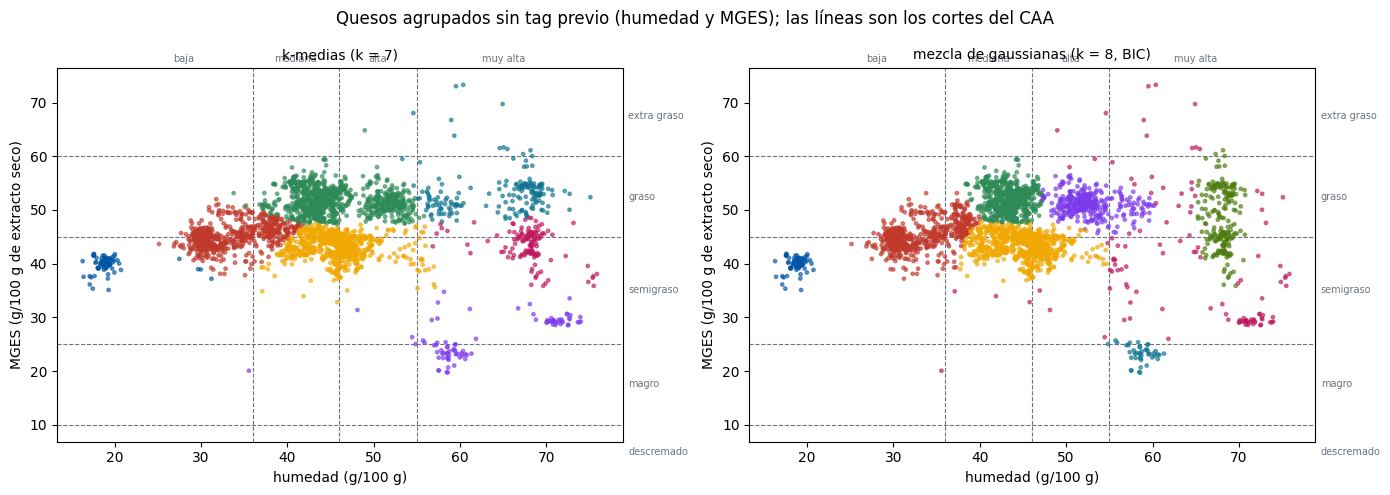

In [38]:
ns = Q.no_supervisado(rama)
print(f"{len(rama)} quesos · {ns['n_outliers']} outliers por consenso · se agrupan {len(ns['base'])}")
print("k-medias, silueta por k:", {k_: round(float(v_), 3) for k_, v_ in ns["silueta"].items()}, "→ k =", ns["k_km"])
print("Mezcla de gaussianas, BIC por k:", {k_: round(float(v_)) for k_, v_ in ns["bic"].items()}, "→ k =", ns["k_gm"])
display(ns["tabla"].round(2).T)
for (alg_, ref_), t_ in ns["cruzadas"].items():
    print(f"{alg_} (filas) contra {ref_} (columnas):")
    display(t_)
print("Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:")
display(ns["estabilidad"].round(2))
print("Promedio:", ns["estabilidad"].mean().round(3).to_dict())

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax_, (nombre_, et_) in zip(ejes, ns["et"].items()):
    ax_.scatter(ns["base"]["humedad"], ns["base"]["mges"], c=[COLORES[e_ % len(COLORES)] for e_ in et_], s=6, alpha=0.6)
    Q.lineas_caa(ax_); ax_.set_xlabel("humedad (g/100 g)"); ax_.set_ylabel("MGES (g/100 g de extracto seco)"); ax_.set_title(nombre_, fontsize=10)
fig.suptitle("Quesos agrupados sin tag previo (humedad y MGES); las líneas son los cortes del CAA")
plt.tight_layout(); plt.show()

**Respuesta.** Sí hay estructura, pero no es la del dominio y el número de grupos es poco robusto. De los 2891 quesos de
la rama, 81 salen como outliers y se agrupan 2810 (humedad y MGES estandarizadas).

- **Qué encuentra.** k-medias elige k = 7 (silueta 0,49; silueta macro 0,54; Davies-Bouldin 0,63) y la mezcla de
  gaussianas k = 8 por BIC (silueta 0,43). Son grupos más compactos que los del corte del CAA (silueta 0,22,
  Davies-Bouldin 1,70).
- **Coincidencia con el dominio.** Contra la clase de humedad del CAA el Rand ajustado (ARI) es 0,31 (k-medias) y 0,38
  (mezcla); contra la clase de MGES, 0,29 y 0,18 (NMI de humedad 0,50 y 0,56). Los extremos se reconocen (un grupo de 101
  quesos puros de baja humedad y dos de 177 y 138 casi puros de muy alta humedad); el medio no tiene corte natural: los
  grupos de humedad intermedia mezclan mediana y alta humedad (641 y 320; 370 y 365). Contra la **consistencia del rótulo**
  el agrupamiento da ARI 0,31 y 0,37 y **la regla del CAA aplicada directo, 0,63**: el corte por humedad coincide con el
  rótulo mejor que cualquier agrupamiento sin tag. Contra el **tipo** (variedad) pasa al revés: 0,28 y 0,36 contra 0,19 de
  la regla, porque los grupos separan también por grasa.
- **Estabilidad.** Con k fijo y otras 10 semillas, el ARI contra la partición base es 1,00 en promedio en k-medias (y el k
  que elige la silueta es 7 en las 10 semillas) y 0,75 en la mezcla (de 0,51 a 0,99; el k que elige el BIC es 8 en 9 semillas
  y 7 en una). Con solo Senasa la mezcla era mucho más estable (ARI 0,99): al sumar los quesos de MQ la humedad y la grasa se
  solapan más y la partición de la mezcla deja de ser única; la del k-medias se mantiene.

Conclusión: sin tag previo se separan grupos en la composición, pero son una partición del continuo (7 a 8 zonas, y la
de la mezcla cambia con la semilla) y no una clasificación por tipo de queso; por eso el subtag de la rama sale de la regla del CAA, que
además coincide mejor con el rótulo.

#### Guardar: el tag y el subtag de cada muestra y el agrupamiento
`clusters_senasa_mq.csv`: una fila por muestra que pasó el filtro (incluidos los outliers, que quedan sin cluster, tag ni subtag),
con Identificador, familia, origen, los cuatro análisis, cluster, tag, subtag (el tag cuando no hay subtag),
criterio_subtag (de qué rama y regla sale), silueta, outlier, votos_outlier (cuántos de los tres métodos la marcan) y, en
el DDL, las tres probabilidades de la logística (p_familiar, p_heladero, p_repostero). Y `agrupamiento_senasa_mq_clase41.joblib`: imputar,
escalar y k-medias en un `Pipeline`, con el mapeo cluster → tag, los nombres, los centroides, el filtro de outliers usado
y los modelos del segundo nivel (`segundo_nivel`: la logística y los detectores de novedad del DDL; el escalador, el
k-medias, el mapeo cluster → subtag y los outliers de la rama del polvo; los cortes de humedad del queso).
`N.predecir` los usa.

In [39]:
import joblib
from sklearn.pipeline import Pipeline
muestras["cluster"] = grupos; muestras["tag"] = tag_de; muestras["subtag"] = subtag_de; muestras["criterio_subtag"] = criterio_de
muestras["silueta"] = coef
prob_ = N.probabilidades_ddl(modelos_subtag, muestras.loc[N.tag_base(tag_de) == "DDL", COLUMNAS]).round(4)
for c_ in prob_:
    muestras[c_] = np.nan
    muestras.loc[N.tag_base(tag_de) == "DDL", c_] = prob_[c_].to_numpy()
salida = muestras_pre[["Identificador", "desc_familia", "origen"] + COLUMNAS + ["outlier"]].rename(columns={"desc_familia": "familia"})
salida["votos_outlier"] = votos["votos"].to_numpy()
salida = salida.merge(muestras[["Identificador", "cluster", "tag", "subtag", "criterio_subtag", "silueta"] + list(prob_)],
                      on="Identificador", how="left")
salida["cluster"] = salida["cluster"].astype("Int64"); salida["silueta"] = salida["silueta"].round(4)
salida["rama"] = "k-medias"
filas_queso = pd.DataFrame({"Identificador": rama["Identificador"], "familia": "queso", "origen": rama["origen"], "humedad": rama["humedad"],
                            "grasa": rama["mg"], "proteinas": rama["proteina"], "cenizas": rama["cenizas"], "tag": "QUESO",
                            "subtag": rama["subtag"], "criterio_subtag": rama["criterio_subtag"], "outlier": False,
                            "rama": "queso (humedad y MG)"})
salida = pd.concat([salida, filas_queso], ignore_index=True)       # los quesos de la rama: sin cluster ni silueta
salida = salida[["Identificador", "familia", "origen", "rama"] + COLUMNAS + ["cluster", "tag", "subtag", "criterio_subtag", "silueta",
                                                                           "outlier", "votos_outlier"] + list(prob_)]
salida.to_csv(R.TABLAS / "clusters_senasa_mq.csv", index=False, encoding="utf-8-sig")
print(f"Guardado: resultados/tablas/clusters_senasa_mq.csv ({len(salida)} filas: {int((salida['rama'] == 'k-medias').sum())} del k-medias y {len(filas_queso)} de la rama de queso; "
      f"{int(salida['tag'].notna().sum())} con tag, {int(salida['outlier'].sum())} outliers)")
print("tag:", salida["tag"].value_counts(dropna=False).to_dict())
print("subtag:", salida["subtag"].value_counts(dropna=False).to_dict())
print("criterio_subtag:", salida["criterio_subtag"].value_counts(dropna=False).to_dict())

agrupamiento = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                         ("kmedias", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA))]).fit(muestras[COLUMNAS])
assert (agrupamiento.predict(muestras[COLUMNAS]) == grupos).all()
out_polvo_ = muestras["Identificador"].isin(modelos_subtag.get("polvo", {}).get("outliers", [])).to_numpy()
assert (N.predecir(modelos_subtag, muestras[COLUMNAS], tag_de, out_polvo_)[0] == subtag_de).all()
joblib.dump({"modelo": agrupamiento, "tags": tags, "nombres": nombres, "columnas": COLUMNAS, "centros": centros,
             "outliers": {"método": "consenso (LOF 50 vecinos, IsolationForest 200, EllipticEnvelope) dentro del k-medias preliminar",
                          "k_preliminar": K_PRE, "pct": PCT_OUTLIER, "minimo_votos": 2},
             "segundo_nivel": N.para_guardar(modelos_subtag),
             "rama_queso": {"criterio": "familia queso del catálogo (Senasa) o rótulo con variedad (solo MQ); humedad = 100 − ST; subtag por clase de humedad del CAA",
                            "cortes_humedad": N.CORTES_QUESO, "muestras": int(len(rama))}},
            R.MODELOS / "agrupamiento_senasa_mq_clase41.joblib")
print("Guardado: resultados/modelos/agrupamiento_senasa_mq_clase41.joblib · cluster → tag:", tags, "· ramas del segundo nivel:", list(modelos_subtag),
      "· polvo, cluster → subtag:", modelos_subtag.get("polvo", {}).get("mapa"))

Guardado: resultados/tablas/clusters_senasa_mq.csv (6828 filas: 3937 del k-medias y 2891 de la rama de queso; 6727 con tag, 101 outliers)
tag: {'QUESO': 2891, 'DDL': 2226, 'POLVO_GRASO': 644, 'LIQUIDO': 454, 'POLVO_MAGRO': 446, nan: 101, 'PROT_ALTA': 66}
subtag: {'QUESO_SEMIDURO': 1195, 'DDL_FAMILIAR': 876, 'QUESO_PASTA_BLANDA': 693, 'DDL_REPOSTERO': 646, 'POLVO_LECHE_ENTERA': 620, 'QUESO_DURO': 539, 'DDL': 527, 'QUESO_MUY_ALTA_HUMEDAD': 464, 'LIQUIDO': 454, 'POLVO_WPC': 310, 'DDL_HELADERO': 177, nan: 101, 'POLVO_LECHE_DESCREMADA': 73, 'POLVO_SUERO_DESMINERALIZADO': 70, 'POLVO_CASEINATO': 40, 'PROT_ALTA': 26, 'POLVO_SUERO_REENGRASADO': 15, 'POLVO_GRASO': 2}
criterio_subtag: {'queso: humedad del CAA': 2891, 'DDL: logística (prob ≥ 0,70)': 1699, 'polvo: k-medias en base seca': 1040, 'DDL: sin decidir (prob < 0,70)': 496, 'sin segundo nivel': 454, nan: 101, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 73, 'DDL: sin decidir (novedad)': 31, 'polvo: cluster s

#### Cuántos datos entran en cada entrenamiento
La celda siguiente guarda los conteos de esta versión (cuántas muestras hay antes de los filtros, cuántas saca cada filtro,
cuántas entran a cada modelo); el apartado «Datos usados en cada entrenamiento», al final del cuaderno, los junta en una
tabla. No calcula nada nuevo.

In [40]:
ENTRENOS = globals().get("ENTRENOS", {})
n_nolact, n_quesos = int(no_lactea.sum()), int(a_rama.sum())
_ddl, _pol = modelos_subtag["DDL"], modelos_subtag["polvo"]
ENTRENOS["senasa_mq"] = dict(
    inicial=n_inicial, n_hs=n_inicial - len(todas) - n_nolact - n_quesos, n_nolact=n_nolact, n_quesos=n_quesos,
    n_sin4=len(todas) - len(completas), n_suma=len(completas) - len(muestras_pre),
    pre=len(muestras_pre), k_pre=int(K_PRE), n_out=int(es_outlier.sum()), final=len(muestras), k=int(K), silueta=float(coef.mean()),
    ddl_n=int(ddl_.sum()), ddl_lab=int(_ddl["etiquetadas"]), ddl_clases=dict(_ddl["por_clase"]),
    ddl_decide=int((criterio_de[ddl_] == N.C_DDL).sum()),
    pol_tag=int(pol_.sum()), pol_rama=int(_pol["n"]), pol_out=int(_pol["n_outliers"]), pol_k=int(_pol["k"]),
    pol_sil=float(_pol["siluetas"][_pol["k"]]),
    q_leidos=int(conteo_q["quesos leídos"]), q_mgst=int(conteo_q["con MG y ST"]), q_rama=len(rama),
    q_sin_confirmar=int(conteo_q.get("solo MQ de familia queso sin confirmar por el rótulo (no entran)", 0)),
    q_out=int(ns["n_outliers"]), q_base=len(ns["base"]), q_k_km=int(ns["k_km"]), q_k_gm=int(ns["k_gm"]),
    comparacion=True)
print({k_: v_ for k_, v_ in ENTRENOS["senasa_mq"].items()})

{'inicial': 30089, 'n_hs': 8, 'n_nolact': 2319, 'n_quesos': 5915, 'n_sin4': 17907, 'n_suma': 3, 'pre': 3937, 'k_pre': 5, 'n_out': 101, 'final': 3836, 'k': 5, 'silueta': 0.8346436859093868, 'ddl_n': 2226, 'ddl_lab': 1601, 'ddl_clases': {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}, 'ddl_decide': 1699, 'pol_tag': 1156, 'pol_rama': 1154, 'pol_out': 16, 'pol_k': 7, 'pol_sil': 0.7677762234245176, 'q_leidos': 5915, 'q_mgst': 2892, 'q_rama': 2891, 'q_sin_confirmar': 1128, 'q_out': 81, 'q_base': 2810, 'q_k_km': 7, 'q_k_gm': 8, 'comparacion': True}


### G · Qué quedó
- Se sumaron Senasa y MQ con la regla del proyecto (Senasa manda; MQ completa huecos y aporta las muestras que no están
  en Senasa). MQ sale de `MQ encolumnado.xlsx` (misma estructura que Senasa; solo los códigos MQ, sin las 1839 MO de la tabla
  ancha, que ya son de Senasa), con las correcciones de la revisión, sin las 8 muestras con humedad + sólidos incoherentes,
  sin las familias que no son lácteas (68 con los cuatro análisis) y **sin los quesos confirmados por el catálogo, que van
  a su rama** (5915 quesos, 75 con los cuatro análisis). Quedan 3940 muestras con los cuatro análisis y 3937 tras
  descartar las 3 que suman más de 102.
- Outliers **dentro de cada tipo de producto**, por consenso (k-medias preliminar con k = 5; LOF, bosque de aislamiento y
  elipse dentro de cada grupo, corte 3 %, 2 de 3 votos): 101 (2,6 %), 57 solo MQ, 35 de Senasa y 9 de Senasa completadas
  con MQ; por familia, 29 sueros, 21 sin clasificar y 21 «queso» (solo MQ que el modelo llama queso y el rótulo no confirma:
  son raras para su grupo). Quedan 3836. La regla anterior (Q3 + 1,5·IQR) quitaría 362 (9,2 %), entre ellos 141 de
  los 176 heladeros: el consenso conserva 172 heladeros y los 11 reducidos en grasa.
- La silueta elige **k = 5** (0,835). Los cinco grupos y su tag: **DDL** (2226), **POLVO_GRASO** (644, leche en polvo),
  **POLVO_MAGRO** (446, concentrados y sueros), **LIQUIDO** (454, suero y leche fluida) y **PROT_ALTA** (66). **Ya no hay
  QUESO en el k-medias**: el tag sale solo de la rama de queso. POLVO_MAGRO y PROT_ALTA son los grupos más débiles
  (silueta media 0,63 y 0,60).
- Sin el sesgo del DDL (B.5): silueta macro 0,754, peor grupo 0,60, Davies-Bouldin 0,37, Calinski-Harabasz 17860.
  Contra la regla anterior (0,862 y macro 0,779) baja porque quedan muestras legítimas del borde; sobre las muestras que
  no quita ninguno de los dos filtros, los dos modelos dan lo mismo (0,864 y macro 0,784).
- Escalar es la decisión correcta, aunque acá la partición no cambia sin escalar (Rand ajustado 1,00).
- k-medias, minilotes y Ward llegan a particiones casi iguales (Rand ajustado 0,999 a 1). El enlace simple encadena y
  deja grupos de 1 a 5 muestras (0,64), el promedio manhattan también se aparta (0,73), y el bisectivo que parte el
  grupo **más grande** corta el dulce de leche en pedazos (0,49).
- Al revelar la familia (la de MQ encolumnado), los grupos se leen como tipos de producto (Rand ajustado contra la familia
  0,92); no coinciden del todo porque algunas familias comparten composición (suero en polvo y concentrados magros; suero
  líquido y leche fluida).
- Las muestras **solo MQ** (893 de las 3836) llevan la familia que les asigna un modelo (`mq_tipo_muestra.csv`, no revisada a
  mano): 508 caen en POLVO_GRASO y 228 en LIQUIDO. De las 1128 solo MQ que el modelo llama queso y el rótulo no confirma
  (697 con MG y ST), ninguna entra a la rama de queso; 44 tenían los cuatro análisis y entraron al k-medias, 21 salieron como
  outliers y las otras 23 cayeron en LIQUIDO (22) y POLVO_MAGRO (1).
- Segundo nivel por familia. **DDL** (logística entrenada con 1601 muestras de subtipo conocido): decide en 1699 de
  2226: **DDL_FAMILIAR** 876, **DDL_REPOSTERO** 646 y **DDL_HELADERO** 177; 527 quedan como DDL (496 sin probabilidad
  suficiente y 31 novedades). Entre las etiquetadas acierta 584 de 789 familiares, 460 de 637 reposteros y 165 de 175
  heladeros (es el ajuste sobre ellas mismas: la exactitud honesta, 0,86 en clientes no vistos, es la de
  `prueba_subtipo_ddl.ipynb`). **Polvo** (1154 muestras con humedad ≤ 15; 16 outliers de la rama; k-medias k = 7 en base seca, silueta
  0,77): por regla, **POLVO_LECHE_DESCREMADA** 73 (72 leches descremadas y 1 parcialmente descremada) y
  **POLVO_SUERO_REENGRASADO** 15 (4 rotuladas suero reengrasado, 8 rotuladas suero y 3 sin tipo); por k-medias,
  **POLVO_LECHE_ENTERA** 620, **POLVO_WPC** 310 (284 WPC; 15 rotuladas solo «suero», con proteína de WPC, y 8 sin tipo),
  **POLVO_SUERO_DESMINERALIZADO** 70 y **POLVO_CASEINATO** 40; un cluster de 18 sin subtag (78 % de proteína en base seca,
  sobre todo caseína) y los outliers de la rama quedan con su tag (PROT_ALTA 26), y 2 muestras con humedad > 15, que no son
  polvo, con el suyo (POLVO_GRASO 2). El LIQUIDO (454) no tiene segundo nivel.
- **Queso** (rama propia, fuera del k-medias; por la humedad del CAA): 2891 quesos (1627 de Senasa, 49 de Senasa completados
  con MQ y 1215 solo MQ con el rótulo que lo confirma): QUESO_SEMIDURO 1195, QUESO_PASTA_BLANDA 693, QUESO_DURO 539 y
  QUESO_MUY_ALTA_HUMEDAD 464. Contra la consistencia del rótulo: 491 de los 539 duros son de baja humedad, 997 de los 1195
  semiduros de mediana, 606 de los 693 de pasta blanda de alta; los muy altos de humedad son sobre todo untables (166) y
  procesados (162). La pregunta «¿se separan sin tag previo?» está arriba: sí, pero en 7 a 8 zonas (las de la mezcla cambian
  con la semilla) y sin coincidir con el CAA (ARI 0,31 a 0,38).
- Cada muestra queda con su `tag`, su `subtag` y su `criterio_subtag` en `resultados/tablas/clusters_senasa_mq.csv` (3937
  del k-medias, 101 de ellas outliers sin tag, y 2891 de la rama de queso, con `rama = queso (humedad y MG)` y sin cluster),
  y el modelo con el mapeo cluster → tag y los modelos del segundo nivel en
  `resultados/modelos/agrupamiento_senasa_mq_clase41.joblib`.

## 5 · Cortes para categorizar (CAA por familia)
`src/cortes_caa.py` (ex `build_cortes_categorias.py`) arma `resultados/tablas/cortes_categorias.csv`: donde el Código
Alimentario Argentino define clases, esas; donde no, terciles dentro de la familia; con menos de 30 valores, cortes
globales (familia `*`). La tabla no se edita a mano: se regenera acá. Criterios y decisiones abiertas:
`docs/cortes_categorias.md`.

**Terciles por estado.** En suero / permeado, concentrado proteico, yogur / bebida láctea, base nutricional y
manteca / crema la composición cambia por completo entre el polvo y el líquido (o entre la manteca y la crema), así que
los terciles se calculan aparte para cada estado (columna `estado`). El estado de una muestra sale de la humedad medida
(≤ 15 polvo, ≥ 25 líquido; en manteca / crema, < 30 es manteca) y, si no hay humedad, del estado declarado. Donde
Senasa tiene menos de 30 valores de un estado (casi no tiene cremas ni sueros líquidos) se suman las muestras nuevas
de MQ. Una muestra de esas familias sin estado no se categoriza en los análisis que dependen del estado.

In [41]:
import cortes_caa
cortes = cortes_caa.armar()
display(cortes.groupby(["analisis", "fuente"], sort=False).size().rename("filas").reset_index()
        .assign(fuente=lambda t: t["fuente"].str.replace(r" \(http.*\)", "", regex=True)))

361 filas -> E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\tablas\cortes_categorias.csv
  humedad: cortes globales para carnicos (17), helado (14), leche fluida (22), panificados / otros (12), sin clasificar (2)
  materia_grasa: cortes globales para carnicos (15), panificados / otros (11), sin clasificar (2)
  proteinas: cortes globales para arroz con leche / postre (5), carnicos (17), panificados / otros (11)
  cenizas: cortes globales para arroz con leche / postre (2), carnicos (15), panificados / otros (11)
  solidos_totales: cortes globales para helado (14), leche fluida (22), panificados / otros (12), sin clasificar (2)
  lactosa: cortes globales para agua / hisopado (6), arroz con leche / postre (2), manteca / crema (4), panificados / otros (7), sin clasificar (6)
  galactosa: cortes globales para agua / hisopado (12), arroz con leche / postre (2), base nutricional (12), concentrado proteico (26), manteca / crema (3), panificados / otros (11), sin clasificar

,analisis,fuente,filas
0,humedad,terciles globales (Senasa encolumnado.xlsx),3
1,humedad,terciles (Senasa encolumnado.xlsx),9
2,humedad,terciles por estado (Senasa + MQ encolumnado.x...,18
3,humedad,terciles por estado (Senasa encolumnado.xlsx),9
4,humedad,"CAA art. 605, inc. 2.b",4
5,materia_grasa,terciles globales (Senasa encolumnado.xlsx),3
6,materia_grasa,terciles (Senasa encolumnado.xlsx),6
7,materia_grasa,terciles por estado (Senasa + MQ encolumnado.x...,12
8,materia_grasa,terciles por estado (Senasa encolumnado.xlsx),9
9,materia_grasa,"CAA art. 592, inc. 5.2",3


## 6 · Categorías de los análisis e ítems para reglas de asociación

Cada resultado numérico de una muestra pasa a una categoría (por ejemplo `humedad=alta humedad` o
`materia_grasa=entera`) con la tabla `cortes_categorias.csv` (criterio «CAA por familia»; ver
`docs/cortes_categorias.md`; la tabla se regenera en la sección 5). Con las categorías, la familia y el tag del cluster se arma una canasta por muestra y se buscan
reglas de asociación como en la clase 44.

**Tag y subtag.** Cada muestra agrupada lleva su `tag=` (el primer nivel: DDL, POLVO_GRASO...), igual que antes, y las
que tienen subtag (secciones 3 y 4, segundo nivel por familia: DDL_FAMILIAR, DDL_REPOSTERO, DDL_HELADERO, POLVO_WPC,
POLVO_LECHE_ENTERA...) suman además el ítem `subtag=`. Se eligió sumar en vez de reemplazar porque así `tag=DDL` sigue
siendo todo el dulce de leche (las reglas del primer nivel no cambian de significado y se comparan con las de antes) y el
subtag agrega lo que el tag no ve: el heladero tiene menos humedad y más cenizas que el familiar, justo lo que miden las
categorías. Una regla que junta el tag con su propio subtag (`subtag=DDL_HELADERO ⇒ tag=DDL`) es trivial («mismo
análisis»). El subtag del queso (QUESO_SEMIDURO...) **no** entra como ítem: es la clase de humedad del CAA, que ya está
como `humedad=`; queda en `clusters_senasa_mq.csv`.

- Lectura y correcciones: `src/datos_clase41.py` (las mismas de la clase 41, sección 1).
- Categorización: `src/categorizar.py`. Las decisiones están como constantes al principio del módulo.
- Salidas, en `resultados/tablas/`: `categorias_senasa.csv`, `categorias_senasa_mq.csv` (una fila por muestra) y
  `transacciones_senasa.parquet`, `transacciones_senasa_mq.parquet` (matriz one-hot muestra × ítem).

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings; warnings.filterwarnings("ignore")

import categorizar as cz

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 110); pd.set_option("display.max_rows", 200)
nombre = lambda s: "{" + ", ".join(sorted(s)) + "}"

print("Decisiones (categorizar.py):")
for k in ["HUMEDAD_QUESO_4_CLASES", "NO_SON_ITEMS", "USAR_CORTES_GLOBALES", "GLOBALES_PARA_SIN_FAMILIA",
          "MARCAR_DDL_GRASA_BAJO_MINIMO", "LACTOSA_REFERENCIA", "SUBTIPO_COMO_ITEM", "SUBTAG_COMO_ITEM", "LIFT_MIN"]:
    print(f"   {k} = {getattr(cz, k)}")
print("   desc_consistencia: queda como columna, no es ítem · terciles por subtipo: no")

Decisiones (categorizar.py):
   HUMEDAD_QUESO_4_CLASES = True
   NO_SON_ITEMS = ['solidos_totales']
   USAR_CORTES_GLOBALES = True
   GLOBALES_PARA_SIN_FAMILIA = True
   MARCAR_DDL_GRASA_BAJO_MINIMO = True
   LACTOSA_REFERENCIA = 4.83
   SUBTIPO_COMO_ITEM = False
   SUBTAG_COMO_ITEM = True
   LIFT_MIN = 1.2
   desc_consistencia: queda como columna, no es ítem · terciles por subtipo: no


### 1 · Las dos tablas

Solo Senasa, y Senasa + MQ (MQ sale de `MQ encolumnado.xlsx`: Senasa manda; MQ completa huecos de humedad, grasa,
proteínas y cenizas y agrega las muestras que solo están en MQ, con la familia que les asigna MQ encolumnado). Los quesos
que confirma el catálogo llevan `tag=QUESO` (rama propia, fuera del k-medias de cuatro análisis); su subtag no es un ítem,
porque sale de la humedad. Las muestras excluidas por humedad + sólidos fuera de 100 ± 1 quedan en la
tabla, sin categorías y con el motivo.

In [43]:
tablas, matrices = {}, {}
for version in ["senasa", "senasa_mq"]:
    tablas[version], matrices[version] = cz.guardar(version)
A = cz.ANALISIS_LISTA
resumen = []
for version, t in tablas.items():
    n_val = int(t[A].notna().sum().sum()); n_cat = int(t[[f"cat_{a}" for a in A]].notna().sum().sum())
    resumen.append({"versión": version, "muestras": len(t), "con algún análisis": int(t[A].notna().any(axis=1).sum()),
                    "transacciones (con ítems)": len(matrices[version]), "ítems distintos": matrices[version].shape[1],
                    "valores": n_val, "categorizados": n_cat, "% categorizado": round(100 * n_cat / n_val, 2),
                    "excluidas": int(t["excluida"].sum())})
display(pd.DataFrame(resumen).set_index("versión"))
t = tablas["senasa"]; M = matrices["senasa"]
print("Orígenes en Senasa + MQ:", tablas["senasa_mq"]["origen"].value_counts().to_dict())
print("Dos muestras con sus ítems:")
for i in t.index[t["items"].map(len) >= 6][:2]:
    print(f"   {t.at[i, 'Identificador']} ({t.at[i, 'familia']}): {t.at[i, 'items']}")

,muestras,con algún análisis,transacciones (con ítems),ítems distintos,valores,categorizados,% categorizado,excluidas
versión,,,,,,,,
senasa,16347,15997,15757,116,40480,40096,99.05,8
senasa_mq,30089,27860,27484,123,65423,64753,98.98,8


Orígenes en Senasa + MQ: {'Senasa': 15996, 'solo MQ': 13742, 'Senasa completada con MQ': 351}
Dos muestras con sus ítems:
   MO-07253-01 (suero / permeado): ['humedad=bajo', 'materia_grasa=medio', 'proteinas=medio', 'cenizas=alto', 'familia=suero / permeado', 'tag=POLVO_MAGRO', 'subtag=POLVO_SUERO_PERMEADO']
   MO-07274-01 (suero / permeado): ['humedad=medio', 'materia_grasa=alto', 'proteinas=medio', 'cenizas=alto', 'familia=suero / permeado', 'tag=POLVO_MAGRO', 'subtag=POLVO_SUERO_PERMEADO']


### 2 · Los cortes que se aplicaron

Para cada análisis y familia: qué juego de cortes se usó (familia + subtipo, familia o los globales `*`), cada
categoría con sus límites (desde incluido, hasta excluido), si está verificada en el CAA y cuántas muestras cayeron.

In [44]:
cortes = cz.leer_cortes()
filas = []
for a in A:
    x = t[t[f"cat_{a}"].notna()]
    g = x.groupby(["familia", f"juego_{a}", f"cat_{a}"]).size().reset_index(name="n")
    g.columns = ["familia", "juego", "categoria", "n"]; g.insert(0, "analisis", a)
    filas.append(g)
aplicados = pd.concat(filas, ignore_index=True)
aplicados["familia_corte"] = np.where(aplicados["juego"] == "globales (*)", "*", aplicados["familia"])
aplicados = aplicados.merge(cortes[["analisis", "familia", "categoria", "desde", "hasta", "verificado", "fuente"]]
                            .rename(columns={"familia": "familia_corte"}), on=["analisis", "familia_corte", "categoria"], how="left")
assert aplicados["desde"].notna().all()
aplicados["fuente"] = aplicados["fuente"].str.replace(r" \(http.*\)", "", regex=True)
print(f"{len(aplicados)} combinaciones análisis × familia × categoría con muestras · juegos usados:",
      aplicados.groupby("juego")["n"].sum().to_dict())
display(aplicados[["analisis", "familia", "juego", "categoria", "desde", "hasta", "verificado", "n", "fuente"]])

371 combinaciones análisis × familia × categoría con muestras · juegos usados: {'familia': 36364, 'familia + estado': 6338, 'globales (*)': 481}


,analisis,familia,juego,categoria,desde,hasta,verificado,n,fuente
0,humedad,arroz con leche / postre,familia,alto,69.350000,inf,no,16,terciles (Senasa encolumnado.xlsx)
1,humedad,arroz con leche / postre,familia,bajo,0.000000,69.020000,no,13,terciles (Senasa encolumnado.xlsx)
2,humedad,arroz con leche / postre,familia,medio,69.020000,69.350000,no,14,terciles (Senasa encolumnado.xlsx)
3,humedad,base nutricional,familia + estado,alto,55.382400,inf,no,1,terciles por estado (Senasa + MQ encolumnado.xlsx)
4,humedad,base nutricional,familia + estado,alto,7.132000,inf,no,1,terciles por estado (Senasa + MQ encolumnado.xlsx)
...,...,...,...,...,...,...,...,...,...
366,fibra,panificados / otros,globales (*),alto,0.960000,inf,no,1,terciles globales (Senasa encolumnado.xlsx)
367,fibra,yogur / bebida lactea,globales (*),no detectado / 0,0.000000,0.000001,no,1,terciles globales (Senasa encolumnado.xlsx)
368,plomo,dulce de leche,familia,no detectado / 0,0.000000,0.000001,no,36,terciles (Senasa encolumnado.xlsx)
369,arsenico,dulce de leche,familia,detectado,0.000001,inf,no,1,terciles (Senasa encolumnado.xlsx)


In [45]:
print("Familias que usan los cortes globales (*), por análisis (n muestras):")
g = aplicados[aplicados["juego"] == "globales (*)"].groupby(["analisis", "familia"])["n"].sum()
for a, s in g.groupby(level=0):
    print(f"   {a}: " + ", ".join(f"{f} ({n})" for (_, f), n in s.items()))

Familias que usan los cortes globales (*), por análisis (n muestras):
   actividad_agua: arroz con leche / postre (3), helado (2), panificados / otros (1)
   azucares_totales: base nutricional (2), concentrado proteico (2), helado (2), leche en polvo (25), leche fluida (17), manteca / crema (2), sin clasificar (10), suero / permeado (6)
   carbohidratos_totales: helado (2), panificados / otros (2)
   cenizas: arroz con leche / postre (2), carnicos (15), panificados / otros (11)
   fibra: helado (2), panificados / otros (1), yogur / bebida lactea (1)
   galactosa: agua / hisopado (12), arroz con leche / postre (2), base nutricional (12), concentrado proteico (26), manteca / crema (2), panificados / otros (11), sin clasificar (5)
   grasas_saturadas: helado (2), panificados / otros (2), yogur / bebida lactea (1)
   grasas_trans: helado (2), panificados / otros (2), yogur / bebida lactea (1)
   humedad: carnicos (17), helado (14), leche fluida (21), panificados / otros (12), sin clasifica

### 3 · Conteos por categoría y familia

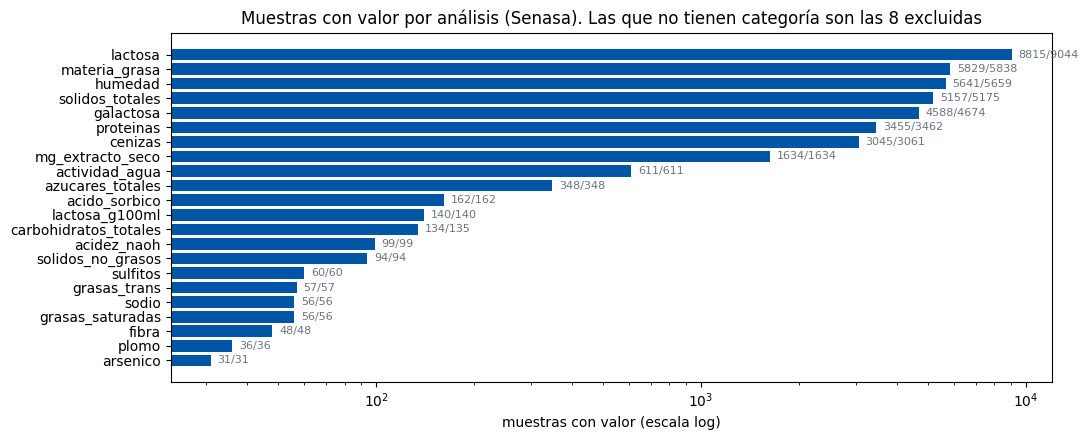

In [46]:
fig, ax = plt.subplots(figsize=(11, 4.5))
p = pd.DataFrame({"valores": t[A].notna().sum(), "categorizados": t[[f"cat_{a}" for a in A]].notna().sum().values}, index=A)
p = p.sort_values("valores")
ax.barh(p.index, p["valores"], color=AZUL); ax.set_xscale("log"); ax.set_xlabel("muestras con valor (escala log)")
ax.set_title("Muestras con valor por análisis (Senasa). Las que no tienen categoría son las 8 excluidas")
for y, (v, k) in enumerate(zip(p["valores"], p["categorizados"])):
    ax.text(v * 1.05, y, f"{k}/{v}", va="center", fontsize=8, color=GRIS)
plt.tight_layout(); plt.show()

In [47]:
for a in ["humedad", "materia_grasa", "proteinas", "cenizas", "lactosa", "galactosa", "mg_extracto_seco"]:
    x = t[t[f"cat_{a}"].notna()]
    tab = pd.crosstab(x[f"cat_{a}"], x["familia"], margins=True, margins_name="total")
    print(f"{a}: {len(x)} muestras"); display(tab)

humedad: 5641 muestras


familia,arroz con leche / postre,base nutricional,carnicos,concentrado proteico,dulce de leche,helado,leche en polvo,leche fluida,manteca / crema,panificados / otros,queso,sin clasificar,suero / permeado,yogur / bebida lactea,total
cat_humedad,,,,,,,,,,,,,,,
alta humedad,0,0,0,0,0,0,0,0,0,0,419,0,0,0,419
alto,16,1,14,111,1007,13,34,21,51,2,0,2,20,0,1292
baja humedad,0,0,0,0,0,0,0,0,0,0,385,0,0,0,385
bajo,13,1,1,108,965,0,33,0,47,9,0,0,19,7,1203
mediana humedad,0,0,0,0,0,0,0,0,0,0,980,0,0,0,980
medio,14,0,2,107,967,1,33,0,47,1,0,0,18,1,1191
muy alta humedad,0,0,0,0,0,0,0,0,0,0,171,0,0,0,171
total,43,2,17,326,2939,14,100,21,145,12,1955,2,57,8,5641


materia_grasa: 5829 muestras


familia,arroz con leche / postre,base nutricional,carnicos,concentrado proteico,dulce de leche,helado,leche en polvo,leche fluida,manteca / crema,panificados / otros,queso,sin clasificar,suero / permeado,yogur / bebida lactea,total
cat_materia_grasa,,,,,,,,,,,,,,,
alto,16,1,13,112,0,0,0,0,51,1,554,1,20,0,769
bajo,16,1,2,105,0,0,0,0,47,10,537,1,19,0,738
bajo el mínimo (<6),0,0,0,0,524,0,0,0,0,0,0,0,0,0,524
con crema,0,0,0,0,77,0,0,0,0,0,0,0,0,10,87
descremada,0,0,0,0,0,0,29,0,0,0,0,0,0,0,29
dulce de leche,0,0,0,0,2728,0,0,0,0,0,0,0,0,0,2728
entera,0,0,0,0,0,0,69,2,0,0,0,0,0,0,71
helado de crema,0,0,0,0,0,114,0,0,0,0,0,0,0,0,114
helado de leche,0,0,0,0,0,11,0,0,0,0,0,0,0,0,11


proteinas: 3455 muestras


familia,arroz con leche / postre,base nutricional,carnicos,concentrado proteico,dulce de leche,helado,leche en polvo,panificados / otros,suero / permeado,yogur / bebida lactea,total
cat_proteinas,,,,,,,,,,,
alto,0,0,16,113,959,34,34,0,20,2,1178
bajo,5,1,1,108,932,31,33,11,19,3,1144
medio,0,0,0,105,935,29,33,0,18,13,1133
total,5,1,17,326,2826,94,100,11,57,18,3455


... (4 outputs left out)

galactosa: 4588 muestras


familia,agua / hisopado,arroz con leche / postre,base nutricional,concentrado proteico,dulce de leche,helado,leche en polvo,leche fluida,manteca / crema,panificados / otros,queso,sin clasificar,suero / permeado,yogur / bebida lactea,total
cat_galactosa,,,,,,,,,,,,,,,
alto,0,0,2,0,140,165,16,490,0,2,635,1,26,26,1503
bajo,12,2,9,25,132,152,14,472,2,5,605,3,23,25,1481
medio,0,0,1,1,131,0,18,473,0,4,610,1,25,23,1287
no detectado / 0,0,0,0,0,0,317,0,0,0,0,0,0,0,0,317
total,12,2,12,26,403,634,48,1435,2,11,1850,5,74,74,4588


mg_extracto_seco: 1634 muestras


familia,dulce de leche,queso,sin clasificar,total
cat_mg_extracto_seco,,,,
bajo,4,0,1,5
extra graso,0,8,0,8
graso,0,1000,0,1000
magro,0,30,0,30
semigraso,0,591,0,591
total,4,1629,1,1634


In [48]:
print("Análisis con pocos datos (casi todos de dulce de leche):")
chicos = [a for a in A if t[f"cat_{a}"].notna().sum() < 400]
display(pd.DataFrame({a: t[f"cat_{a}"].value_counts() for a in chicos}).fillna(0).astype(int).T)

Análisis con pocos datos (casi todos de dulce de leche):


,alto,bajo,detectado,lactosa normal,medio,no detectado / 0
lactosa_g100ml,0,0,0,140,0,0
acido_sorbico,55,54,0,0,53,0
carbohidratos_totales,46,43,0,0,45,0
azucares_totales,122,87,0,0,47,92
acidez_naoh,36,31,0,0,32,0
solidos_no_grasos,32,32,0,0,30,0
sulfitos,0,0,0,0,0,60
grasas_saturadas,20,19,0,0,17,0
grasas_trans,20,18,0,0,19,0
sodio,22,18,0,0,16,0


### 4 · Requisitos del CAA y marcas

Los requisitos que no son clases (`cortes_categorias.md`, decisión 3) entran como ítems `req_<requisito>=cumple / no
cumple`. Además se marcan los dulces de leche con grasa menor a 6 (conservan la categoría «bajo el mínimo (<6)») y la
lactosa «bajo / reducido / normal» de la leche fluida, que depende de la referencia 4,83 g/100 g (no verificada en el
CAA).

In [49]:
req = pd.DataFrame({f"req_{r[0]}": t[f"req_{r[0]}"].value_counts() for r in cz.REQUISITOS}).fillna(0).astype(int).T
req["% no cumple"] = (100 * req.get("no cumple", 0) / req.sum(axis=1)).round(1)
req["fuente"] = [r[6] for r in cz.REQUISITOS]
display(req)
ddl = t[t["ddl_grasa_bajo_minimo"]]
print(f"Dulce de leche con grasa < 6: {len(ddl)} · por subtipo: {ddl['subtipo'].fillna('sin subtipo').value_counts().to_dict()}")
print(f"Lactosa con categoría que depende de la referencia {cz.LACTOSA_REFERENCIA} (no verificada): {int(t['lactosa_sin_verificar'].sum())} muestras",
      t.loc[t["lactosa_sin_verificar"], "cat_lactosa"].value_counts().to_dict())

,cumple,no cumple,% no cumple,fuente
req_ddl_humedad_max_30,2681,258,8.8,CAA art. 592
req_ddl_proteinas_min_5,2631,195,6.9,CAA art. 592
req_ddl_cenizas_max_2,2058,379,15.6,CAA art. 592
req_polvo_humedad_max_5,100,0,0.0,CAA art. 567
req_manteca_grasa_min_82,145,0,0.0,CAA art. 596
req_manteca_humedad_max_16,145,0,0.0,CAA art. 596


Dulce de leche con grasa < 6: 524 · por subtipo: {'FAMILIAR': 199, 'HELADERO': 136, 'sin subtipo': 101, 'REPOSTERO': 88}
Lactosa con categoría que depende de la referencia 4.83 (no verificada): 1614 muestras {'reducido en lactosa': 670, 'lactosa normal': 551, 'bajo en lactosa': 253}


### 5 · Muestras sin categoría y por qué

Cada valor sin categoría tiene su motivo en la columna `sin_categoria` («análisis: motivo»). Motivos posibles: muestra
excluida (humedad + sólidos), valor fuera del rango físico, valor negativo, familia sin cortes ni globales, globales
desactivados.

In [50]:
for version, tv in tablas.items():
    s = tv["sin_categoria"].dropna().str.split("; ").explode()
    mot = s.str.split(": ", n=1).str[1].str.replace(r"valor [-\d.e+]+", "valor X", regex=True)
    print(f"{version}: {tv['sin_categoria'].notna().sum()} muestras con algún valor sin categoría · {len(s)} valores")
    display(pd.crosstab(s.str.split(": ", n=1).str[0], mot))
    # comprobación: todo valor tiene categoría o motivo
    for a in A:
        sin = tv[a].notna() & tv[f"cat_{a}"].isna()
        assert tv.loc[sin, "sin_categoria"].fillna("").str.contains(f"{a}: ", regex=False).all(), a
print("Comprobado: cada valor sin categoría tiene su motivo.")
display(t.loc[t["sin_categoria"].notna(), ["Identificador", "familia", "humedad", "solidos_totales", "sin_categoria"]])

senasa: 248 muestras con algún valor sin categoría · 384 valores


sin_categoria,la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado),muestra excluida: humedad + sólidos fuera de 100 ± 1,sin cortes de cenizas para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de solidos_totales para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores)
sin_categoria,,,,,
carbohidratos_totales,0,1,0,0,0
cenizas,0,6,10,0,0
galactosa,86,0,0,0,0
humedad,0,8,0,10,0
lactosa,229,0,0,0,0
materia_grasa,1,8,0,0,0
proteinas,1,6,0,0,0
solidos_totales,0,8,0,0,10


senasa_mq: 478 muestras con algún valor sin categoría · 670 valores


sin_categoria,la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado),muestra excluida: humedad + sólidos fuera de 100 ± 1,sin cortes de cenizas para el estado LIQUIDO de «base nutricional» (menos de 30 valores),sin cortes de cenizas para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de proteinas para el estado LIQUIDO de «base nutricional» (menos de 30 valores),sin cortes de solidos_totales para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores)
sin_categoria,,,,,,,
carbohidratos_totales,0,1,0,0,0,0,0
cenizas,48,6,4,10,0,0,0
galactosa,85,0,0,0,0,0,0
humedad,0,8,0,0,11,0,0
lactosa,219,0,0,0,0,0,0
materia_grasa,87,8,0,0,0,0,0
proteinas,147,6,0,0,0,12,0
solidos_totales,0,8,0,0,0,0,10


Comprobado: cada valor sin categoría tiene su motivo.


,Identificador,familia,humedad,solidos_totales,sin_categoria
1466,MO-07732-01,yogur / bebida lactea,3.88,96.12,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
1540,MO-07984-01,yogur / bebida lactea,3.97,96.03,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
1668,MO-08308-01,yogur / bebida lactea,3.46,96.54,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
1701,MO-08429-01,leche fluida,90.70,4.30,humedad: muestra excluida: humedad + sólidos fuera de 100 ± 1; materia_grasa: muestra excluida: humedad + ...
1833,MO-08806-01,yogur / bebida lactea,3.69,96.31,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
...,...,...,...,...,...
16026,MQ-44089-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)
16027,MQ-44091-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)
16028,MQ-44094-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)
16101,MQ-44348-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)


### 6 · Las categorías frente a los tags de cluster (clase 41)

El tag sale del agrupamiento de humedad, grasa, proteínas y cenizas (solo para las muestras con los cuatro análisis; los
outliers no tienen tag ni subtag). Si las categorías y los clusters cuentan la misma historia, cada tag debería
concentrarse en pocas categorías. Las tablas por categoría usan el subtag (que fuera del DDL y de los polvos es el mismo
tag), para ver también en qué se diferencian los subtipos del DDL y los tipos de polvo.

In [51]:
for version, tv in tablas.items():
    print(f"{version} · estado del cluster:", tv["estado_cluster"].value_counts().to_dict())
x = t[t["tag"].notna()]
display(pd.crosstab(x["familia"], x["tag"], margins=True, margins_name="total"))
print("Subtags del DDL contra el subtipo (Senasa):")
display(pd.crosstab(x.loc[x["tag"] == "DDL", "subtag"], x.loc[x["tag"] == "DDL", "subtipo"].fillna("sin subtipo"), margins=True, margins_name="total"))
for a in ["humedad", "materia_grasa", "proteinas", "cenizas"]:
    y = x[x[f"cat_{a}"].notna()]
    print(f"{a} × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):")
    tab = pd.crosstab([y["familia"], y[f"cat_{a}"]], y["subtag"], normalize="columns").mul(100).round(0)
    display(tab[(tab > 0).any(axis=1)])

senasa · estado del cluster: {'no agrupada (faltan análisis, suma > 102 o excluida)': 12060, 'con tag': 2597, 'con tag (rama de queso)': 1627, 'outlier (sin tag)': 63}
senasa_mq · estado del cluster: {'no agrupada (faltan análisis, suma > 102 o excluida)': 23261, 'con tag': 3836, 'con tag (rama de queso)': 2891, 'outlier (sin tag)': 101}


tag,DDL,LIQUIDO,POLVO_GRASO,POLVO_MAGRO,PROT_ALTA,QUESO,total
familia,,,,,,,
arroz con leche / postre,0,2,0,0,0,0,2
concentrado proteico,0,0,1,276,49,0,326
dulce de leche,2115,5,0,0,0,0,2120
helado,1,2,0,0,0,0,3
leche en polvo,0,0,71,29,0,0,100
queso,0,0,0,0,0,1627,1627
suero / permeado,0,0,8,30,0,0,38
yogur / bebida lactea,0,1,7,0,0,0,8
total,2116,10,87,335,49,1627,4224


Subtags del DDL contra el subtipo (Senasa):


subtipo,FAMILIAR,HELADERO,REPOSTERO,sin subtipo,total
subtag,,,,,
DDL,145,5,120,214,484
DDL_FAMILIAR,564,0,43,247,854
DDL_HELADERO,1,146,3,7,157
DDL_REPOSTERO,39,1,446,135,621
total,749,152,612,603,2116


humedad × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):


subtag                                      DDL  DDL_FAMILIAR  DDL_HELADERO  DDL_REPOSTERO  LIQUIDO  POLVO_CASEINATO  POLVO_CONCENTRADO  \
familia                  cat_humedad                                                                                                      
arroz con leche / postre alto               0.0           0.0           0.0            0.0     20.0              0.0                0.0   
concentrado proteico     alto               0.0           0.0           0.0            0.0      0.0             97.0              100.0   
                         bajo               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         medio              0.0           0.0           0.0            0.0      0.0              3.0                0.0   
dulce de leche           alto              31.0          70.0           3.0            5.0     50.0              0.0                0.0   
                         bajo              12.0           0.0          92.0           64.0      0.0              0.0                0.0   
                         medio             57.0          30.0           5.0           32.0      0.0              0.0                0.0   
helado                   alto               0.0           0.0           0.0            0.0     20.0              0.0                0.0   
leche en polvo           alto               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         bajo               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         medio              0.0           0.0           0.0            0.0      0.0              0.0                0.0   
queso                    alta humedad       0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         baja humedad       0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         mediana humedad    0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         muy alta humedad   0.0           0.0           0.0            0.0      0.0              0.0                0.0   
suero / permeado         alto               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         bajo               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         medio              0.0           0.0           0.0            0.0      0.0              0.0                0.0   
yogur / bebida lactea    bajo               0.0           0.0           0.0            0.0     10.0              0.0                0.0   

subtag                                     POLVO_LECHE_DESCREMADA  POLVO_LECHE_ENTERA  POLVO_SUERO_PERMEADO  POLVO_SUERO_REENGRASADO  POLVO_WPC  PROT_ALTA  \
familia                  cat_humedad                                                                                                                         
arroz con leche / postre alto                                 0.0                 0.0                   0.0                      0.0        0.0        0.0   
concentrado proteico     alto                                 0.0                 0.0                   3.0                      0.0       23.0      100.0   
                         bajo                                 0.0                 1.0                   3.0                      0.0       39.0        0.0   
                         medio                                0.0                 0.0                   0.0                      0.0       39.0        0.0   
dulce de leche           alto                                 0.0                 0.0                   0.0                      0.0

... (2 outputs left out)

proteinas × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):


subtag                                   DDL  DDL_FAMILIAR  DDL_HELADERO  DDL_REPOSTERO  LIQUIDO  POLVO_CASEINATO  POLVO_CONCENTRADO  POLVO_GRASO  \
familia                  cat_proteinas                                                                                                              
arroz con leche / postre bajo            0.0           0.0           0.0            0.0     20.0              0.0                0.0          0.0   
concentrado proteico     alto            0.0           0.0           0.0            0.0      0.0            100.0              100.0          0.0   
                         bajo            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
dulce de leche           alto           48.0          18.0          69.0           63.0     10.0              0.0                0.0          0.0   
                         bajo           14.0          32.0           5.0           25.0     20.0              0.0                0.0          0.0   
                         medio          38.0          51.0          26.0           13.0     20.0              0.0                0.0          0.0   
helado                   alto            0.0           0.0           0.0            0.0     10.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0     10.0              0.0                0.0          0.0   
leche en polvo           alto            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         bajo            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
suero / permeado         alto            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         bajo            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
yogur / bebida lactea    alto            0.0           0.0           0.0            0.0      0.0              0.0                0.0         29.0   
                         medio           0.0           0.0           0.0            0.0     10.0              0.0                0.0         71.0   

subtag                                  POLVO_LECHE_DESCREMADA  POLVO_LECHE_ENTERA  POLVO_SUERO_PERMEADO  POLVO_SUERO_REENGRASADO  POLVO_WPC  PROT_ALTA  
familia                  cat_proteinas                                                                                                                   
arroz con leche / postre bajo                              0.0                 0.0                   0.0                      0.0        0.0        0.0  
concentrado proteico     alto                              0.0                 1.0                   0.0                      0.0       23.0      100.0  
                         bajo                              0.0                 0.0                   6.0                      0.0       39.0        0.0  
                         medio                             0.0                 0.0                   0.0                      0.0       38.0        0.0  
dulce de leche           alto                              0.0                 0.0                   0.0                      0.0        0.0        0.0  
                         bajo                              0.0                 0.0        

cenizas × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):


subtag                                 DDL  DDL_FAMILIAR  DDL_HELADERO  DDL_REPOSTERO  LIQUIDO  POLVO_CASEINATO  POLVO_CONCENTRADO  POLVO_LECHE_DESCREMADA  \
familia                  cat_cenizas                                                                                                                         
arroz con leche / postre bajo          0.0           0.0           0.0            0.0     20.0              0.0                0.0                     0.0   
concentrado proteico     alto          0.0           0.0           0.0            0.0      0.0              0.0              100.0                     0.0   
                         bajo          0.0           0.0           0.0            0.0      0.0             97.0                0.0                     0.0   
                         medio         0.0           0.0           0.0            0.0      0.0              3.0                0.0                     0.0   
dulce de leche           alto         29.0          10.0          97.0           30.0      0.0              0.0                0.0                     0.0   
                         bajo         28.0          53.0           0.0           28.0     30.0              0.0                0.0                     0.0   
                         medio        44.0          37.0           3.0           42.0     20.0              0.0                0.0                     0.0   
helado                   medio         0.0           0.0           0.0            0.0     20.0              0.0                0.0                     0.0   
leche en polvo           alto          0.0           0.0           0.0            0.0      0.0              0.0                0.0                   100.0   
                         bajo          0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
                         medio         0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
suero / permeado         alto          0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
                         bajo          0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
                         medio         0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
yogur / bebida lactea    medio         0.0           0.0           0.0            0.0     10.0              0.0                0.0                     0.0   

subtag                                POLVO_LECHE_ENTERA  POLVO_SUERO_PERMEADO  POLVO_SUERO_REENGRASADO  POLVO_WPC  PROT_ALTA  
familia                  cat_cenizas                                                                                           
arroz con leche / postre bajo                        0.0                   0.0                      0.0        0.0        0.0  
concentrado proteico     alto                        0.0                   0.0                      0.0       38.0       25.0  
                         bajo                        0.0                   6.0                      0.0       24.0       75.0  
                         medio                       1.0                   0.0                      0.0       38.0        0.0  
dulce de leche           alto                        0.0                   0.0                      0.0        0.0        0.0  
                         bajo                        0.0                   0.0                      0.0        0.0        0.0  
                         medio                       0.0                   0.0                      0.0        0.0        0.0  
helado                   medio                       0.0                   0.0                      0.0        0.0        0.0  
leche en polvo           alto    

### 7 · La matriz transaccional

Una fila por muestra con al menos un análisis categorizado; una columna por ítem. Como en la clase 44, la matriz sale de
`TransactionEncoder`. Los sólidos totales están categorizados pero no son ítems (son ≈ 100 − humedad).

Matriz Senasa: 15757 transacciones × 116 ítems · ítems por muestra: {'count': 15757.0, 'mean': 4.2, 'std': 2.8, 'min': 2.0, '25%': 2.0, '50%': 3.0, '75%': 5.0, 'max': 18.0}


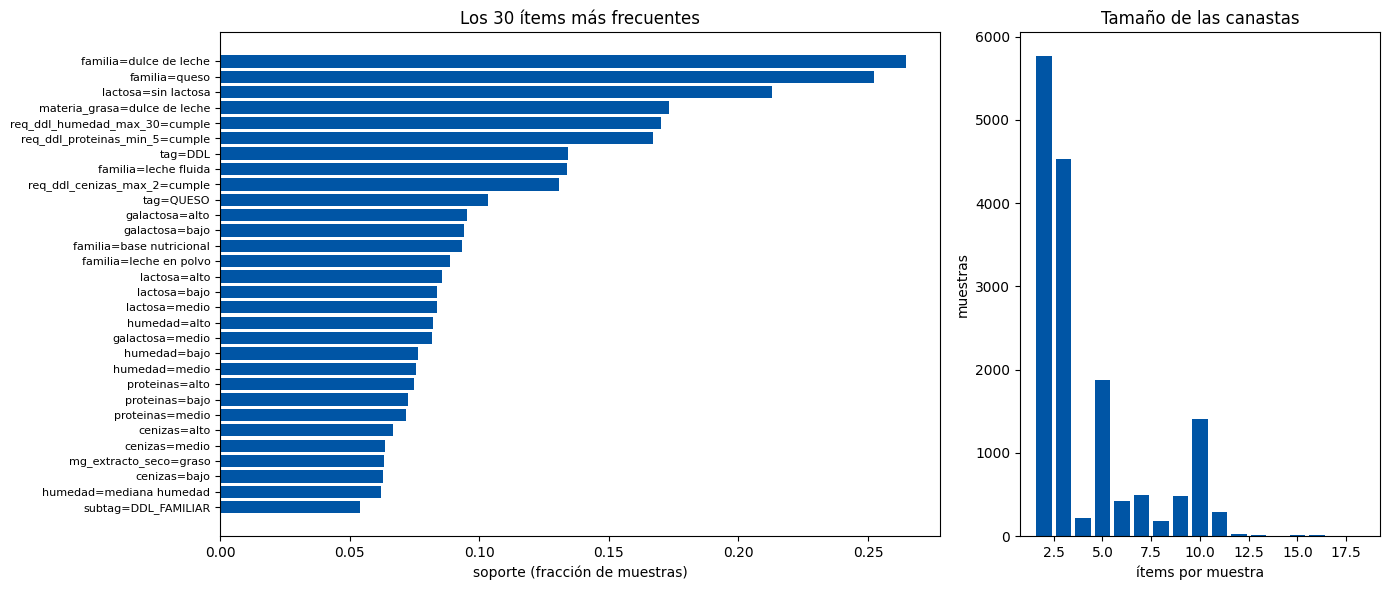

,acidez_naoh=alto,acidez_naoh=bajo,acidez_naoh=medio,acido_sorbico=alto,acido_sorbico=bajo,acido_sorbico=medio,actividad_agua=alto,actividad_agua=bajo,actividad_agua=medio,arsenico=detectado,...,subtag=POLVO_SUERO_PERMEADO,subtag=POLVO_SUERO_REENGRASADO,subtag=POLVO_WPC,sulfitos=no detectado / 0,tag=DDL,tag=LIQUIDO,tag=POLVO_GRASO,tag=POLVO_MAGRO,tag=PROT_ALTA,tag=QUESO
Identificador,,,,,,,,,,,,,,,,,,,,,
MO-01393-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01395-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01396-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01397-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01431-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [52]:
soportes = M.mean().sort_values(ascending=False)
print(f"Matriz Senasa: {M.shape[0]} transacciones × {M.shape[1]} ítems · ítems por muestra: {M.sum(axis=1).describe().round(1).to_dict()}")
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2, 1]})
top = soportes.head(30)
a.barh(top.index, top.values, color=AZUL); a.invert_yaxis(); a.set_xlabel("soporte (fracción de muestras)"); a.set_title("Los 30 ítems más frecuentes")
a.tick_params(axis="y", labelsize=8)
tam = M.sum(axis=1).value_counts().sort_index(); b.bar(tam.index, tam.values, color=AZUL)
b.set_xlabel("ítems por muestra"); b.set_ylabel("muestras"); b.set_title("Tamaño de las canastas")
plt.tight_layout(); plt.show()
M.head().astype(int)

### 8 · Reglas de asociación (Senasa)

`fpgrowth` (da los mismos conjuntos que `apriori`, más rápido) con soporte mínimo 1 % (la celda imprime cuántas
transacciones son) y hasta 3 ítems; `association_rules` con confianza mínima 0,6.

Muchas reglas son triviales. `cz.filtrar_reglas` las marca:

- **mismo análisis**: el consecuente repite un análisis del antecedente (humedad=alto ⇒ req_ddl_humedad_max_30=no
  cumple repite la definición del corte);
- **cuenta**: la materia grasa en extracto seco junto con la grasa y la humedad, de las que se calcula;
- **define la familia**: materia_grasa=helado de crema ⇒ familia=helado (esa categoría solo existe en el helado);
- **familia redundante**: familia=queso junto con una categoría que solo existe en el queso;
- **cortes globales en la familia**: familia=X junto con un análisis que en X usa los cortes globales (familias chicas
  y muestras solo MQ): `cenizas=alto` de una muestra sin familia no se compara con el tercil de cada familia;
- **explicada por la familia o el panel**: la elevación global es alta solo porque la categoría es propia de una
  familia o porque los análisis se miden juntos (cenizas y proteínas van en el mismo panel). Se recalcula la elevación
  sobre las muestras que pueden tener la regla (las familias donde aparecen sus ítems, con sus análisis medidos):
  `lift_ajustado`. Si es menor que 1,2, la regla es trivial.

Las reglas útiles se ordenan por elevación (`lift`); al lado, `lift_ajustado`.

In [53]:
MIN_SOPORTE, MIN_CONFIANZA, MAX_LEN = 0.01, 0.6, 3
columnas = ["regla", "support", "confidence", "lift", "lift_ajustado", "familias"]

def reglas_de(M_):
    frec = fpgrowth(M_, min_support=MIN_SOPORTE, use_colnames=True, max_len=MAX_LEN)
    r = association_rules(frec, metric="confidence", min_threshold=MIN_CONFIANZA)
    r = cz.filtrar_reglas(r, M_)
    r["regla"] = [f"{nombre(a)} ⇒ {nombre(b)}" for a, b in zip(r["antecedents"], r["consequents"])]
    return frec, r      # los listados ordenan por elevación y desempatan por soporte y por texto: sin eso, el orden de los empates cambia entre corridas

frec, reglas = reglas_de(M)
print(f"Soporte mínimo {MIN_SOPORTE:.0%} de {len(M)} transacciones = {MIN_SOPORTE * len(M):.0f} muestras (Senasa) · y de {len(matrices['senasa_mq'])} = {MIN_SOPORTE * len(matrices['senasa_mq']):.0f} (Senasa + MQ)")
print(f"{len(frec)} conjuntos frecuentes (por tamaño: {frec['itemsets'].apply(len).value_counts().sort_index().to_dict()}) → {len(reglas)} reglas con confianza ≥ {MIN_CONFIANZA}")
print("Reglas por motivo:", reglas["motivo_trivial"].fillna("útil").value_counts().to_dict())
for m in ["mismo análisis", "cuenta", "define la familia", "familia redundante", "cortes globales en la familia", "explicada por la familia o el panel"]:
    ej = reglas[reglas["motivo_trivial"] == m].sort_values(["lift", "support", "regla"], ascending=[False, False, True], kind="mergesort")
    if len(ej):
        print(f"Triviales «{m}» (las 3 de mayor elevación):"); display(ej[columnas].head(3).round(3).reset_index(drop=True))

Soporte mínimo 1% de 15757 transacciones = 158 muestras (Senasa) · y de 27484 = 275 (Senasa + MQ)
741 conjuntos frecuentes (por tamaño: {1: 55, 2: 206, 3: 480}) → 1090 reglas con confianza ≥ 0.6
Reglas por motivo: {'explicada por la familia o el panel': 527, 'mismo análisis': 199, 'define la familia': 159, 'familia redundante': 113, 'útil': 85, 'cuenta': 7}
Triviales «mismo análisis» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,"{familia=concentrado proteico, tag=POLVO_MAGRO} ⇒ {subtag=POLVO_WPC}",0.017,0.993,56.883,1.177,concentrado proteico
1,"{subtag=POLVO_WPC} ⇒ {familia=concentrado proteico, tag=POLVO_MAGRO}",0.017,0.996,56.883,1.177,concentrado proteico
2,"{tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico, subtag=POLVO_WPC}",0.017,0.818,46.865,1.380,concentrado proteico


Triviales «cuenta» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,"{materia_grasa=bajo, mg_extracto_seco=semigraso} ⇒ {humedad=alta humedad}",0.015,0.677,25.468,3.095,queso
1,"{humedad=alta humedad, materia_grasa=bajo} ⇒ {mg_extracto_seco=semigraso}",0.015,0.822,21.907,2.262,queso
2,"{humedad=alta humedad, mg_extracto_seco=semigraso} ⇒ {materia_grasa=bajo}",0.015,1.000,21.351,3.030,queso


Triviales «define la familia» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,{subtag=POLVO_WPC} ⇒ {familia=concentrado proteico},0.017,1.0,27.741,1.0,concentrado proteico
1,"{subtag=POLVO_WPC, tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico}",0.017,1.0,27.741,1.0,concentrado proteico
2,{galactosa=no detectado / 0} ⇒ {familia=helado},0.020,1.0,23.413,1.0,helado


Triviales «familia redundante» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,"{familia=queso, materia_grasa=bajo} ⇒ {mg_extracto_seco=semigraso}",0.022,0.646,17.228,1.779,queso
1,"{familia=queso, humedad=alta humedad} ⇒ {materia_grasa=bajo}",0.018,0.683,14.574,2.434,queso
2,"{familia=queso, materia_grasa=medio} ⇒ {mg_extracto_seco=graso}",0.028,0.813,12.817,1.326,queso


Triviales «explicada por la familia o el panel» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,{tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico},0.018,0.824,22.855,1.173,concentrado proteico
1,"{materia_grasa=alto, tag=QUESO} ⇒ {mg_extracto_seco=graso}",0.026,0.733,11.548,1.195,queso
2,{mg_extracto_seco=semigraso} ⇒ {tag=QUESO},0.038,1.000,9.685,1.000,queso


In [54]:
utiles = reglas[reglas["motivo_trivial"].isna()].sort_values(["lift", "support", "regla"], ascending=[False, False, True], kind="mergesort").reset_index(drop=True)
print(f"{len(utiles)} reglas no triviales, ordenadas por elevación:")
display(utiles[columnas].round(3))

85 reglas no triviales, ordenadas por elevación:


,regla,support,confidence,lift,lift_ajustado,familias
0,"{humedad=bajo, req_ddl_cenizas_max_2=cumple} ⇒ {subtag=DDL_REPOSTERO}",0.024,0.845,21.453,2.912,dulce de leche
1,"{subtag=DDL_REPOSTERO} ⇒ {humedad=bajo, req_ddl_cenizas_max_2=cumple}",0.024,0.617,21.453,2.912,dulce de leche
2,"{humedad=alta humedad} ⇒ {materia_grasa=bajo, tag=QUESO}",0.018,0.683,20.029,2.434,queso
3,"{cenizas=medio, humedad=bajo} ⇒ {subtag=DDL_REPOSTERO}",0.011,0.729,18.504,3.065,dulce de leche
4,"{humedad=baja humedad} ⇒ {materia_grasa=alto, tag=QUESO}",0.015,0.621,17.656,2.160,queso
5,"{humedad=alta humedad, tag=QUESO} ⇒ {mg_extracto_seco=semigraso}",0.015,0.660,17.600,1.817,queso
6,"{materia_grasa=bajo, tag=QUESO} ⇒ {mg_extracto_seco=semigraso}",0.022,0.646,17.228,1.779,queso
7,"{humedad=alta humedad, tag=QUESO} ⇒ {materia_grasa=bajo}",0.018,0.803,17.153,2.434,queso
8,"{humedad=baja humedad, tag=QUESO} ⇒ {mg_extracto_seco=semigraso}",0.013,0.631,16.817,1.736,queso
9,"{cenizas=bajo, humedad=bajo} ⇒ {subtag=DDL_REPOSTERO}",0.011,0.602,15.278,2.820,dulce de leche


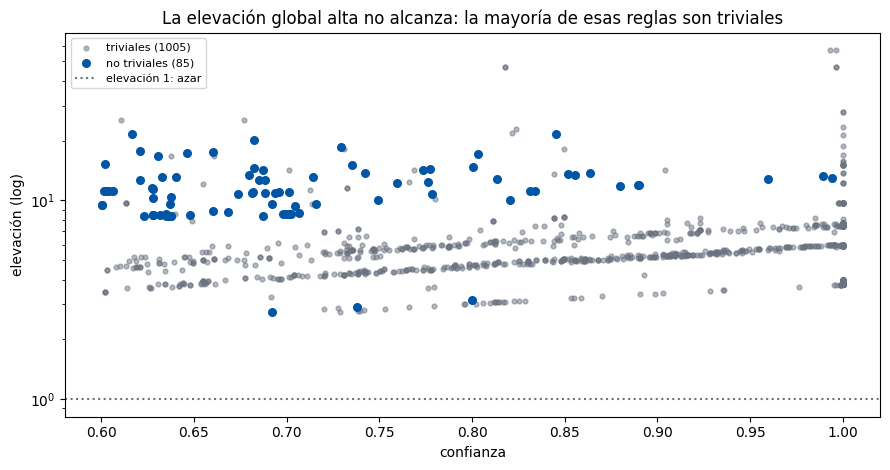

In [55]:
fig, ax = plt.subplots(figsize=(9, 4.8))
tr = reglas["motivo_trivial"].notna()
ax.scatter(reglas.loc[tr, "confidence"], reglas.loc[tr, "lift"], s=12, alpha=0.5, color=GRIS, label=f"triviales ({tr.sum()})")
ax.scatter(reglas.loc[~tr, "confidence"], reglas.loc[~tr, "lift"], s=30, color=AZUL, label=f"no triviales ({(~tr).sum()})")
ax.axhline(1, color=GRIS, ls=":", label="elevación 1: azar"); ax.set_yscale("log")
ax.set_xlabel("confianza"); ax.set_ylabel("elevación (log)"); ax.legend(fontsize=8)
ax.set_title("La elevación global alta no alcanza: la mayoría de esas reglas son triviales")
plt.tight_layout(); plt.show()

### 9 · Reglas con Senasa + MQ

Las muestras solo MQ llevan la familia de MQ encolumnado (la asigna un modelo o, si el modelo no decide y la descripción es clara, una regla por descripción; no está revisada a mano). En las familias con terciles por estado (sección 5) cada muestra se compara con las de su mismo estado. Las «sin clasificar» usan los cortes globales y solo tienen los cuatro análisis principales.

In [56]:
M2 = matrices["senasa_mq"]
frec2, reglas2 = reglas_de(M2)
print(f"Senasa + MQ: {M2.shape[0]} transacciones × {M2.shape[1]} ítems · {len(frec2)} frecuentes → {len(reglas2)} reglas")
print("Reglas por motivo:", reglas2["motivo_trivial"].fillna("útil").value_counts().to_dict())
utiles2 = reglas2[reglas2["motivo_trivial"].isna()].sort_values(["lift", "support", "regla"], ascending=[False, False, True], kind="mergesort").reset_index(drop=True)
display(utiles2[columnas].head(20).round(3))
nuevas = sorted(set(utiles2["regla"]) - set(utiles["regla"]))
print(f"Reglas útiles que aparecen con MQ y no solo con Senasa: {len(nuevas)} (las primeras 15):")
for r in nuevas[:15]:
    print("   ", r)

Senasa + MQ: 27484 transacciones × 123 ítems · 694 frecuentes → 913 reglas
Reglas por motivo: {'explicada por la familia o el panel': 411, 'mismo análisis': 152, 'define la familia': 131, 'útil': 121, 'familia redundante': 94, 'cuenta': 3, 'cortes globales en la familia': 1}


,regla,support,confidence,lift,lift_ajustado,familias
0,"{materia_grasa=entera, proteinas=medio} ⇒ {tag=POLVO_GRASO}",0.016,0.863,36.816,1.274,leche en polvo; yogur / bebida lactea
1,"{tag=POLVO_GRASO} ⇒ {materia_grasa=entera, proteinas=medio}",0.016,0.693,36.816,1.274,leche en polvo; yogur / bebida lactea
2,"{humedad=bajo, req_ddl_cenizas_max_2=cumple} ⇒ {subtag=DDL_REPOSTERO}",0.014,0.841,35.793,2.919,dulce de leche
3,"{subtag=POLVO_LECHE_ENTERA} ⇒ {familia=leche en polvo, proteinas=medio}",0.017,0.732,30.264,2.158,leche en polvo
4,"{tag=POLVO_GRASO} ⇒ {familia=leche en polvo, proteinas=medio}",0.017,0.707,29.200,2.230,leche en polvo
5,"{cenizas=medio, materia_grasa=entera} ⇒ {tag=POLVO_GRASO}",0.011,0.662,28.235,1.276,leche en polvo; yogur / bebida lactea
6,"{subtag=POLVO_WPC, tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico}",0.010,0.932,27.538,10.272,concentrado proteico
7,{subtag=POLVO_WPC} ⇒ {familia=concentrado proteico},0.010,0.926,27.360,10.433,concentrado proteico
8,"{subtag=POLVO_LECHE_ENTERA} ⇒ {humedad=bajo, proteinas=medio}",0.014,0.637,24.185,1.899,4 familias
9,"{subtag=DDL_FAMILIAR} ⇒ {humedad=alto, req_ddl_cenizas_max_2=cumple}",0.022,0.701,24.050,1.973,dulce de leche


Reglas útiles que aparecen con MQ y no solo con Senasa: 72 (las primeras 15):
    {cenizas=bajo, humedad=medio} ⇒ {familia=dulce de leche}
    {cenizas=bajo, materia_grasa=entera} ⇒ {humedad=bajo}
    {cenizas=medio, humedad=alto} ⇒ {familia=dulce de leche}
    {cenizas=medio, humedad=medio} ⇒ {familia=dulce de leche}
    {cenizas=medio, materia_grasa=entera} ⇒ {familia=leche en polvo}
    {cenizas=medio, materia_grasa=entera} ⇒ {humedad=bajo}
    {cenizas=medio, materia_grasa=entera} ⇒ {tag=POLVO_GRASO}
    {cenizas=medio, proteinas=alto} ⇒ {familia=dulce de leche}
    {cenizas=medio, subtag=POLVO_LECHE_ENTERA} ⇒ {familia=leche en polvo}
    {cenizas=medio, tag=POLVO_GRASO} ⇒ {familia=leche en polvo}
    {cenizas=medio, tag=POLVO_GRASO} ⇒ {materia_grasa=entera}
    {familia=dulce de leche, subtag=DDL_REPOSTERO} ⇒ {humedad=bajo}
    {familia=dulce de leche, subtag=DDL_REPOSTERO} ⇒ {proteinas=alto}
    {familia=leche en polvo, humedad=bajo} ⇒ {materia_grasa=entera}
    {familia=leche en

### 10 · Lo que queda abierto

- Las categorías por terciles son relativas a la familia: `humedad=alto` no es el mismo número en el queso que en el
  dulce de leche. Por eso las reglas que mezclan familias se leen con `lift_ajustado`.
- El soporte mínimo de 1 % deja afuera a las familias chicas (manteca, helado, yogur). Para ellas conviene correr las
  reglas dentro de cada familia.
- Por la misma razón, no todos los subtags llegan al 1 % de las transacciones: quedan afuera los polvos chicos y, según
  la versión, hasta algún subtag del DDL. La celda de abajo cuenta cuáles entran y cuáles
  no, en cada versión. Para ver las reglas de los que quedan afuera hay que correrlas dentro de la familia o bajar el
  soporte.
- Las decisiones de `cortes_categorias.md` siguen abiertas (bases de la leche fluida, del yogur y del helado; lactosa con
  referencia 4,83; cortes globales en las familias chicas y en las muestras sin familia; dulce de leche con grasa < 6).
  Se cambian en las constantes de `categorizar.py`.

In [57]:
for version, Mx in [("senasa", M), ("senasa_mq", M2)]:
    corte = MIN_SOPORTE * len(Mx)
    n_sub = Mx[[c for c in Mx.columns if c.startswith("subtag=")]].sum().sort_values(ascending=False)
    n_sub.index = n_sub.index.str.replace("subtag=", "", regex=False)
    print(f"{version} (corte: {corte:.0f} de {len(Mx)} transacciones)")
    print("   entran:   ", ", ".join(f"{k} ({v})" for k, v in n_sub[n_sub >= corte].items()))
    print("   quedan afuera:", ", ".join(f"{k} ({v})" for k, v in n_sub[n_sub < corte].items()))

senasa (corte: 158 de 15757 transacciones)
   entran:    DDL_FAMILIAR (854), DDL_REPOSTERO (621), POLVO_WPC (275)
   quedan afuera: DDL_HELADERO (157), POLVO_LECHE_ENTERA (72), POLVO_CASEINATO (39), POLVO_SUERO_PERMEADO (32), POLVO_LECHE_DESCREMADA (29), POLVO_SUERO_REENGRASADO (8), POLVO_CONCENTRADO (5)
senasa_mq (corte: 275 de 27484 transacciones)
   entran:    DDL_FAMILIAR (876), DDL_REPOSTERO (646), POLVO_LECHE_ENTERA (620), POLVO_WPC (310)
   quedan afuera: DDL_HELADERO (177), POLVO_LECHE_DESCREMADA (73), POLVO_SUERO_DESMINERALIZADO (70), POLVO_CASEINATO (40), POLVO_SUERO_REENGRASADO (15)


## 7 · MQ con el formato de Senasa encolumnado
`src/mq_encolumnado.py` (ex `build_mq_encolumnado.py`) pone las muestras de tipo MQ con las 177 columnas de
`Senasa encolumnado.xlsx` (más los analitos que solo tiene MQ), para sumarlas al entrenamiento del modelo supervisado.
Usa los crudos de `datos_entrada/mq/crudos/`, `muestras_ancha.csv`, `mq_tipo_muestra.csv` y el extractor de
`src/compartido/Filtrado_de_Datos_2_ordenado.ipynb`; lo que escribe pasa por `src/compartido/anonimizar.py`.
Con `REGENERAR_MQ = False` (por defecto) solo lee los dos Excel ya generados.

La familia de las muestras nuevas la asigna un modelo. Las que el modelo deja «sin clasificar» pasan por las reglas de
`src/reglas_descripcion.py`: si la descripción nombra un producto de una sola familia (crema, manteca, ricota, WPC,
salame...) se clasifica; si es ambigua, queda «sin clasificar». `desc_familia_fuente` dice de dónde sale cada familia.

In [58]:
import mq_encolumnado
mq_todas, mq_nuevas = mq_encolumnado.armar(REGENERAR_MQ)
print(f"MQ encolumnado: {mq_todas.shape} · solo nuevas: {mq_nuevas.shape}")
display(mq_todas["desc_familia"].value_counts().rename("muestras MQ").to_frame()
        .join(mq_nuevas["desc_familia"].value_counts().rename("nuevas (no están en Senasa)")).fillna(0).astype(int))
display(mq_nuevas["desc_familia_fuente"].value_counts().rename("muestras nuevas").to_frame())

AVISO: falta datos/marcas_privadas.txt; sin lista negra de marcas.


Leídos (sin regenerar): MQ encolumnado.xlsx (15821, 199) · MQ encolumnado - solo nuevas.xlsx (13742, 199)
MQ encolumnado: (15821, 199) · solo nuevas: (13742, 199)


,muestras MQ,nuevas (no están en Senasa)
desc_familia,,
leche en polvo,4485,4231
queso,3101,3037
suero / permeado,1590,1342
sin clasificar,1282,1280
manteca / crema,1185,1181
dulce de leche,1160,112
leche fluida,1020,830
yogur / bebida lactea,565,538
concentrado proteico,542,460


,muestras nuevas
desc_familia_fuente,
modelo,11132
sin clasificar,1280
regla por descripción: crema,830
regla por descripción: carnicos,131
regla por descripción: ricota,81
regla por descripción: harina / cereal / lactosa,77
regla por descripción: soja,62
regla por descripción: manteca,57
regla por descripción: wpc,43


### 7.1 · Lo declarado contra la humedad medida
`src/declarado_vs_medido.py` compara lo que la clasificación afirma sobre la humedad con el resultado: la consistencia
del queso (baja / mediana / alta, donde «alta» incluye «muy alta») contra la clase del CAA art. 605, y el estado
(polvo ≤ 15, líquido ≥ 25). «borde» es quedar fuera de la clase por 1 g/100 g o menos. El detalle de las que no
coinciden queda en `resultados/excel/declarado_vs_medido.xlsx`.

In [59]:
import declarado_vs_medido
dvm, dvm_resumen = declarado_vs_medido.armar()
display(dvm_resumen)
q = dvm[dvm["eje"] == "consistencia del queso"]
display(q.groupby(["origen", "origen_declarado"]).agg(muestras=("coincide", "size"), coincide=("coincide", "mean"))
        .assign(coincide=lambda t: (100 * t["coincide"]).round(1)).rename(columns={"coincide": "% coincide"}))

6502 comparaciones (347 no coinciden) -> declarado_vs_medido.csv, declarado_vs_medido.xlsx


,eje,origen,declarado,muestras,coincide,borde,no coincide,% coincide,% coincide o borde
0,consistencia del queso,MQ nueva (automática),TOTAL,1399,1200,72,127,85.8,90.9
1,consistencia del queso,MQ nueva (automática),alta humedad,562,499,24,39,88.8,93.1
2,consistencia del queso,MQ nueva (automática),baja humedad,363,305,13,45,84.0,87.6
3,consistencia del queso,MQ nueva (automática),mediana humedad,474,396,35,43,83.5,90.9
4,consistencia del queso,Senasa (manual),TOTAL,1706,1590,66,50,93.2,97.1
5,consistencia del queso,Senasa (manual),alta humedad,424,362,25,37,85.4,91.3
6,consistencia del queso,Senasa (manual),baja humedad,356,351,4,1,98.6,99.7
7,consistencia del queso,Senasa (manual),mediana humedad,926,877,37,12,94.7,98.7
8,estado,MQ nueva (automática),LIQUIDO,1046,1045,0,1,99.9,99.9
9,estado,MQ nueva (automática),POLVO,1953,1928,0,25,98.7,98.7


muestras  % coincide
origen                origen_declarado                      
MQ nueva (automática) formato                125        95.2
                      rotulo                  71        59.2
                      variedad              1203        86.4
Senasa (manual)       formato                102       100.0
                      rotulo                 256       100.0
                      variedad              1348        91.4

## 8 · Datos usados en cada entrenamiento
Cuántas muestras entran a cada modelo que se entrena en este cuaderno, con la misma tabla que en los demás cuadernos:
cuántas hay antes de los filtros propios del modelo, cuántas se excluyen y por qué, cuántas se usan y cómo se reparten
entre entrenamiento, validación y prueba. Los números salen de las variables de las secciones 3, 4 y 6 (no están escritos
a mano). Una fila por modelo y por población (solo Senasa; Senasa + MQ). Los agrupamientos no tienen prueba: se ajustan
con todas las muestras que usan. La tabla también se guarda en `resultados/datos_entrenamiento/trabajo_senasa_mq.csv`.

In [60]:
import datos_entrenamiento as DE

ETIQUETAS = {"senasa": "solo Senasa", "senasa_mq": "Senasa + MQ"}
SIN_PARTICION = "sin partición: se ajusta con todas las muestras que usa"
filas = []
for clave, etiqueta in ETIQUETAS.items():
    e = ENTRENOS[clave]
    origen = "muestras de Senasa" if clave == "senasa" else "muestras de Senasa y de MQ"
    umbral = str(N.UMBRAL_DDL).replace(".", ",")
    filas += [
        DE.fila("I", f"k-medias preliminar y consenso de outliers, {etiqueta}", f"{origen} con los cuatro análisis (humedad, grasa, proteínas y cenizas)",
                e["inicial"], e["pre"],
                motivo=(f"{e['n_hs']} con humedad + sólidos incoherentes; {e['n_nolact']} de familias no lácteas; {e['n_quesos']} quesos (van a su rama); "
                        f"{e['n_sin4']} sin los cuatro análisis; {e['n_suma']} suman más de {SUMA_MAX}"),
                particion=SIN_PARTICION,
                nota=(f"k-medias preliminar con k = {e['k_pre']} (silueta, {N_INIT_KMEDIAS} reinicios, semilla {SEMILLA}); el consenso (factor local, bosque de "
                      f"aislamiento y elipse, 2 de 3 votos, dentro de cada grupo preliminar) marca {e['n_out']} outliers")),
        DE.fila("I", f"k-medias final, {etiqueta}", "muestras del k-medias preliminar sin los outliers", e["pre"], e["final"],
                motivo=f"{e['n_out']} outliers por consenso", particion=SIN_PARTICION,
                nota=f"k = {e['k']} por silueta máxima ({e['silueta']:.3f}); {N_INIT_KMEDIAS} reinicios, semilla {SEMILLA}"),
        DE.fila("I", f"segundo nivel del DDL: regresión logística, {etiqueta}", "muestras con tag DDL del k-medias final", e["ddl_n"], e["ddl_lab"],
                motivo="sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag)",
                particion="sin partición en este cuaderno (se ajusta con todas las que tienen subtipo); la validación por cliente, con clientes no vistos, está en prueba_subtipo_ddl.ipynb",
                nota=(f"subtipo conocido por clase: {e['ddl_clases']}; decide en {e['ddl_decide']} de {e['ddl_n']} (probabilidad ≥ {umbral} y sin novedad; "
                      f"la novedad se detecta con Mahalanobis robusta y LOF)")),
        DE.fila("I", f"segundo nivel de polvos: k-medias en base seca, {etiqueta}", "muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",
                e["pol_tag"], e["pol_rama"] - e["pol_out"],
                motivo=f"{e['pol_tag'] - e['pol_rama']} con humedad > 15 (no son polvo); {e['pol_out']} outliers de la rama (consenso)",
                particion=SIN_PARTICION,
                nota=(f"k = {e['pol_k']} por silueta ({e['pol_sil']:.2f}) en grasa, proteína y cenizas en base seca; además dos reglas de composición "
                      f"(leche descremada y suero reengrasado) que no se entrenan")),
        DE.fila("I", f"rama de queso: regla del CAA, no se entrena, {etiqueta}", "quesos que confirma el catálogo", e["q_leidos"], e["q_rama"],
                motivo=(f"{e['q_leidos'] - e['q_mgst']} sin materia grasa o sin sólidos totales; {e['q_mgst'] - e['q_rama']} imposibles "
                        f"(MG > ST o humedad + sólidos fuera de 100 ± 1)"),
                entrenamiento=0, particion="no se entrena: el subtag sale de la clase de humedad del CAA (art. 605)",
                nota=(f"entran las {e['q_rama']}, sin quitar outliers" +
                      (f"; {e['q_sin_confirmar']} solo MQ de familia queso que el rótulo no confirma no entran" if e["q_sin_confirmar"] else ""))),
        DE.fila("I", f"quesos sin tag previo: k-medias y mezcla de gaussianas, {etiqueta}", "quesos de la rama (humedad y MGES)", e["q_rama"], e["q_base"],
                motivo=f"{e['q_out']} outliers por consenso", particion=SIN_PARTICION + "; estabilidad con 10 semillas",
                nota=f"k-medias con k = {e['q_k_km']} (silueta) y mezcla con k = {e['q_k_gm']} (BIC); es un ensayo, no un modelo guardado"),
    ]
    if e["comparacion"]:
        filas.append(DE.fila("I", f"comparación de algoritmos (k-medias sin escalar, minilotes, Ward, enlaces, bisectivo), {etiqueta}",
                             "muestras del k-medias final", e["pre"], e["final"], motivo=f"{e['n_out']} outliers por consenso", particion=SIN_PARTICION,
                             nota=(f"ninguno se guarda: se comparan con el k-medias final (k = {e['k']}); la sección 3 no los repite. Entran también las 40 corridas "
                                   f"de A.2 (inicialización al azar contra k-means++)")))
for clave, etiqueta, mx, fr, rg in [("senasa", "solo Senasa", matrices["senasa"], frec, reglas), ("senasa_mq", "Senasa + MQ", matrices["senasa_mq"], frec2, reglas2)]:
    tv = tablas[clave]
    filas.append(DE.fila("I", f"reglas de asociación (FP-growth), {etiqueta}", "muestras con ítems (categorías de los análisis, familia, tag y subtag)", len(tv), len(mx),
                         motivo=f"{len(tv) - len(mx)} sin ningún ítem: no son transacciones (hay {int(tv['excluida'].sum())} excluidas por humedad + sólidos, que pierden los ítems de sus análisis)",
                         particion="sin partición: las reglas se buscan en todas las transacciones",
                         nota=(f"soporte mínimo {MIN_SOPORTE:.0%}, hasta {MAX_LEN} ítems, confianza ≥ {str(MIN_CONFIANZA).replace('.', ',')}: "
                               f"{len(fr)} conjuntos frecuentes y {len(rg)} reglas, {int(rg['motivo_trivial'].isna().sum())} no triviales")))
display(DE.guardar(filas, "trabajo_senasa_mq"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,I,"k-medias preliminar y consenso de outliers, solo Senasa","muestras de Senasa con los cuatro análisis (humedad, grasa, proteínas y cenizas)",16347,13687,8 con humedad + sólidos incoherentes; 1727 de familias no lácteas; 4006 quesos (van a su rama); 7946 sin l...,2660,2660,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k-medias preliminar con k = 5 (silueta, 50 reinicios, semilla 42); el consenso (factor local, bosque de ai..."
1,I,"k-medias final, solo Senasa",muestras del k-medias preliminar sin los outliers,2660,63,63 outliers por consenso,2597,2597,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 5 por silueta máxima (0.854); 50 reinicios, semilla 42"
2,I,"segundo nivel del DDL: regresión logística, solo Senasa",muestras con tag DDL del k-medias final,2116,595,sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag),1521,1521,<NA>,<NA>,"sin partición en este cuaderno (se ajusta con todas las que tienen subtipo); la validación por cliente, co...","subtipo conocido por clase: {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}; decide en 1632 de 2116 (..."
3,I,"segundo nivel de polvos: k-medias en base seca, solo Senasa","muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",471,8,0 con humedad > 15 (no son polvo); 8 outliers de la rama (consenso),463,463,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 8 por silueta (0.73) en grasa, proteína y cenizas en base seca; además dos reglas de composición (lech..."
4,I,"rama de queso: regla del CAA, no se entrena, solo Senasa",quesos que confirma el catálogo,4006,2379,2379 sin materia grasa o sin sólidos totales; 0 imposibles (MG > ST o humedad + sólidos fuera de 100 ± 1),1627,0,<NA>,<NA>,no se entrena: el subtag sale de la clase de humedad del CAA (art. 605),"entran las 1627, sin quitar outliers"
5,I,"quesos sin tag previo: k-medias y mezcla de gaussianas, solo Senasa",quesos de la rama (humedad y MGES),1627,43,43 outliers por consenso,1584,1584,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa; estabilidad con 10 semillas,"k-medias con k = 5 (silueta) y mezcla con k = 7 (BIC); es un ensayo, no un modelo guardado"
6,I,"k-medias preliminar y consenso de outliers, Senasa + MQ","muestras de Senasa y de MQ con los cuatro análisis (humedad, grasa, proteínas y cenizas)",30089,26152,8 con humedad + sólidos incoherentes; 2319 de familias no lácteas; 5915 quesos (van a su rama); 17907 sin ...,3937,3937,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k-medias preliminar con k = 5 (silueta, 50 reinicios, semilla 42); el consenso (factor local, bosque de ai..."
7,I,"k-medias final, Senasa + MQ",muestras del k-medias preliminar sin los outliers,3937,101,101 outliers por consenso,3836,3836,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 5 por silueta máxima (0.835); 50 reinicios, semilla 42"
8,I,"segundo nivel del DDL: regresión logística, Senasa + MQ",muestras con tag DDL del k-medias final,2226,625,sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag),1601,1601,<NA>,<NA>,"sin partición en este cuaderno (se ajusta con todas las que tienen subtipo); la validación por cliente, co...","subtipo conocido por clase: {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}; decide en 1699 de 2226 (..."
9,I,"segundo nivel de polvos: k-medias en base seca, Senasa + MQ","muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",1156,18,2 con humedad > 15 (no son polvo); 16 outliers de la rama (consenso),1138,1138,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 7 por silueta (0.77) en grasa, proteína y cenizas en base seca; además dos reglas de composición (lech..."


## 9 · Verificación
Que estén todas las salidas, con su forma y su huella (sha256), y que sean coherentes entre sí: el tag de cada muestra
en `clusters_*.csv` es el del modelo guardado, y el subtag el que dan los modelos del segundo nivel del joblib; las tablas de categorías tienen una fila por muestra de Senasa (o de
Senasa + MQ), y MQ encolumnado empieza con las 177 columnas de Senasa encolumnado.

In [61]:
import hashlib
import joblib
import segundo_nivel

def huella(p):
    return hashlib.sha256(p.read_bytes()).hexdigest()[:12]

salidas = {
    "excel/dataset_senasa_revision.xlsx": None, "excel/dataset_senasa_mq_revision.xlsx": None,
    "excel/MQ encolumnado.xlsx": None, "excel/MQ encolumnado - solo nuevas.xlsx": None,
    "tablas/clusters_senasa.csv": None, "tablas/clusters_senasa_mq.csv": None, "tablas/cortes_categorias.csv": None,
    "tablas/categorias_senasa.csv": None, "tablas/categorias_senasa_mq.csv": None,
    "tablas/declarado_vs_medido.csv": None, "excel/declarado_vs_medido.xlsx": None,
    "tablas/transacciones_senasa.parquet": None, "tablas/transacciones_senasa_mq.parquet": None,
    "modelos/agrupamiento_senasa_clase41.joblib": None, "modelos/agrupamiento_senasa_mq_clase41.joblib": None,
}
filas = []
for rel in salidas:
    p = R.RESULTADOS / rel
    assert p.exists(), f"falta {rel}"
    if p.suffix == ".csv":
        forma = pd.read_csv(p, low_memory=False).shape
    elif p.suffix == ".parquet":
        forma = pd.read_parquet(p).shape
    elif p.suffix == ".xlsx":
        forma = {h: d.shape for h, d in pd.read_excel(p, sheet_name=None).items()}
    else:
        forma = "-"
    filas.append({"salida": rel, "forma": str(forma), "bytes": p.stat().st_size, "sha256 (12)": huella(p)})
display(pd.DataFrame(filas))

for v, archivo in [("senasa", "agrupamiento_senasa_clase41.joblib"), ("senasa_mq", "agrupamiento_senasa_mq_clase41.joblib")]:
    cl = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig")
    m = joblib.load(R.MODELOS / archivo)
    con = cl.dropna(subset=["cluster"])
    assert (con["cluster"].astype(int).map(m["tags"]) == con["tag"]).all(), v
    assert cl.loc[cl["outlier"], "tag"].isna().all() and cl.loc[cl["outlier"], "subtag"].isna().all(), v
    assert con["subtag"].notna().all(), v
    q = cl[cl["rama"] == "queso (humedad y MG)"]            # la rama de queso: sin cluster, tag QUESO, subtag por humedad del CAA
    assert q["cluster"].isna().all() and (q["tag"] == "QUESO").all() and not q["outlier"].any(), v
    assert (q["subtag"].to_numpy() == segundo_nivel.subtag_queso(q["humedad"])).all(), v
    assert not set(q["Identificador"]) & set(con["Identificador"]), f"{v}: un queso en el k-medias y en la rama"
    assert len(q) + len(con) + int(cl["outlier"].sum()) == len(cl), v
    sn = m["segundo_nivel"]
    out_polvo = con["Identificador"].isin(sn.get("polvo", {}).get("outliers", [])).to_numpy()
    sub, crit = segundo_nivel.predecir(sn, con[COLUMNAS], con["tag"], out_polvo)
    assert (sub == con["subtag"].to_numpy()).all() and (crit == con["criterio_subtag"].to_numpy()).all(), v
    cat = pd.read_csv(R.TABLAS / f"categorias_{v}.csv", encoding="utf-8-sig", low_memory=False)
    assert cat["Identificador"].is_unique, v
    print(f"{v}: {len(con)} muestras con tag {sorted(m['tags'].values())} · subtags {sorted(set(con['subtag']) - set(con['tag']))} · "
          f"{int(cl['outlier'].sum())} outliers · {len(q)} quesos en su rama {q['subtag'].value_counts().to_dict()} · categorías {cat.shape}")
assert len(pd.read_csv(R.TABLAS / "categorias_senasa.csv", encoding="utf-8-sig", low_memory=False)) == len(S.crudo)
cols_senasa = list(pd.read_excel(R.SENASA, nrows=0).columns)
for d in (mq_todas, mq_nuevas):
    assert list(d.columns[:177]) == cols_senasa
sin = mq_nuevas["desc_familia"].eq("sin clasificar")
assert (mq_nuevas.loc[sin, "desc_familia_fuente"] == "sin clasificar").all() and not (mq_nuevas.loc[~sin, "desc_familia_fuente"] == "sin clasificar").any()
ce = cortes[cortes["estado"].fillna("").ne("")]
assert set(ce["familia"]) <= set(cortes_caa.FAMILIAS_CON_ESTADO) and set(ce["estado"]) <= set(cortes_caa.ESTADOS)
print("Verificación: todo en orden.")

,salida,forma,bytes,sha256 (12)
0,excel/dataset_senasa_revision.xlsx,"{'dataset': (16347, 43), 'inconsistencias': (161, 6), 'resumen': (44, 7), 'notas': (34, 3)}",2920253,ed7e97bc8008
1,excel/dataset_senasa_mq_revision.xlsx,"{'dataset': (30089, 55), 'inconsistencias': (924, 7), 'resumen': (53, 10), 'notas': (41, 3)}",5598868,8a1ced8e92ad
2,excel/MQ encolumnado.xlsx,"{'Sheet1': (15821, 199)}",8531221,e70d29ae636c
3,excel/MQ encolumnado - solo nuevas.xlsx,"{'Sheet1': (13742, 199)}",7375957,d6a890c28ebb
4,tablas/clusters_senasa.csv,"(4287, 18)",592607,ca033364c262
5,tablas/clusters_senasa_mq.csv,"(6828, 18)",934855,d3cadab8aff1
6,tablas/cortes_categorias.csv,"(361, 11)",58750,bf5026bf6a53
7,tablas/categorias_senasa.csv,"(16347, 87)",5759568,52134b53b73e
8,tablas/categorias_senasa_mq.csv,"(30089, 87)",9855394,318ab5ffb5c2
9,tablas/declarado_vs_medido.csv,"(6502, 15)",1283108,1f417ddb9e56


senasa: 2597 muestras con tag ['DDL', 'LIQUIDO', 'POLVO_GRASO', 'POLVO_MAGRO', 'PROT_ALTA'] · subtags ['DDL_FAMILIAR', 'DDL_HELADERO', 'DDL_REPOSTERO', 'POLVO_CASEINATO', 'POLVO_CONCENTRADO', 'POLVO_LECHE_DESCREMADA', 'POLVO_LECHE_ENTERA', 'POLVO_SUERO_PERMEADO', 'POLVO_SUERO_REENGRASADO', 'POLVO_WPC'] · 63 outliers · 1627 quesos en su rama {'QUESO_SEMIDURO': 793, 'QUESO_PASTA_BLANDA': 358, 'QUESO_DURO': 325, 'QUESO_MUY_ALTA_HUMEDAD': 151} · categorías (16347, 87)


senasa_mq: 3836 muestras con tag ['DDL', 'LIQUIDO', 'POLVO_GRASO', 'POLVO_MAGRO', 'PROT_ALTA'] · subtags ['DDL_FAMILIAR', 'DDL_HELADERO', 'DDL_REPOSTERO', 'POLVO_CASEINATO', 'POLVO_LECHE_DESCREMADA', 'POLVO_LECHE_ENTERA', 'POLVO_SUERO_DESMINERALIZADO', 'POLVO_SUERO_REENGRASADO', 'POLVO_WPC'] · 101 outliers · 2891 quesos en su rama {'QUESO_SEMIDURO': 1195, 'QUESO_PASTA_BLANDA': 693, 'QUESO_DURO': 539, 'QUESO_MUY_ALTA_HUMEDAD': 464} · categorías (30089, 87)
Verificación: todo en orden.
